# Honours Co-12 analysis mock-up

This results notebook compares SHAP explanations of Random Forest, XGBoost and MLP models with native symbolic equations fitted by PySR. It loads the saved datasets, fitted models and completed audit artefacts. Ordinary execution also recomputes the lightweight Feynman TreeSHAP matrices and generating-equation permutation summary from the frozen tree models; the more expensive audit calculations remain behind explicit rerun switches (off by default). No estimator is trained or tuned here. The primary comparison is RF/XGBoost/MLP SHAP versus native PySR equations; legacy PySR SHAP scores are supplementary historical results only.

The explanation units are deliberately kept distinct. A SHAP vector is a **local explanation** of one fitted-model prediction. Means, rankings and distributions aggregated over those vectors are **global summaries of local explanations**, not a single global rule. A PySR equation is instead one **global executable prediction rule** that can be evaluated at any admissible input.

The Feynman benchmark is a controlled problem with a known generating equation, so recovery and global alignment can be assessed against a reference relationship. The body-fat dataset is a small real observational dataset with no known ground-truth explanation, so its analysis focuses on predictive performance, faithfulness evidence, stability and representation-specific compactness. Feynman equation recovery is kept separate from faithfulness to each fitted model.

Explanation quality is multidimensional. This honours project deliberately evaluates a selected subset of the Co-12 properties rather than attempting all twelve. Predictive performance is reported as essential model context, but it is **not itself a Co-12 explanation-quality property**. The body-fat survey is supplementary; two responses and their exploratory interpretation are recorded below.

| Property | Status |
|---|---|
| Correctness | RF/XGBoost/MLP local model-faithfulness checks and native-equation audits implemented |
| Completeness | RF/XGBoost/MLP output-completeness and native PySR structural completeness implemented |
| Continuity | Response-conditioned RF/XGBoost/MLP SHAP continuity implemented; native PySR retained as equation/model sensitivity |
| Compactness | RF/XGBoost/MLP 80%/90%/95% local-attribution distributions and native PySR equation structure implemented separately |
| Supplementary survey | Two body-fat responses; individual ratings, preference counts, comments and exploratory interpretation included |

The MLP extension loads the frozen September 2026 HPC pipelines, including their input and target scalers. It adds model-agnostic exact SHAP and paired audits without training. Historical tree/PySR artefacts remain unchanged; MLP results and combined figures are saved under `outputs/mlp_analysis`. The native-importance comparisons and the existing three-model survey retain their original scope.


## Configuration and validation

All paths are project-relative. The next cell checks every required saved artefact before analysis and raises one readable error listing anything missing. Packages are not installed and missing artefacts are not substituted. The interpreter path printed below records the environment used for the clean execution.

MLP audit caches are checked against source/model hashes, recorded versions, and an output inventory. Missing or stale results require the explicit `RERUN_MLP_AUDITS` switch or `python -m scripts.mlp_analysis`; ordinary execution never silently omits MLP.


In [1]:
from pathlib import Path
import json
import sys

import joblib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
import shap
from IPython.display import JSON, Markdown, display
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

PROJECT_ROOT = Path.cwd().resolve()

def project_path(relative_path):
    return PROJECT_ROOT / Path(relative_path)

if not project_path("outputs").is_dir():
    raise RuntimeError(
        "Project outputs directory was not found. Run this notebook from the project root: "
        f"{PROJECT_ROOT}"
    )

COLORS = {
    "Random Forest": "#4C78A8",
    "XGBoost": "#F58518",
    "PySR": "#54A24B",
    "MLP": "#B279A2",
}

REQUIRED_ARTIFACTS = {
    "Feynman metrics": "outputs/best_models/metrics.csv",
    "Feynman continuity summary": "outputs/best_models/noise_sensitivity.csv",
    "Feynman continuity repeats": "outputs/best_models/noise_sensitivity_repeats.csv",
    "Feynman continuity audit": "outputs/best_models/selection_audit/continuity_manifest.json",
    "Feynman continuity detail": "outputs/best_models/selection_audit/continuity_summary.csv",
    "Feynman training manifest": "outputs/best_models/training_manifest.json",
    "Feynman Random Forest": "outputs/best_models/random_forest_best.joblib",
    "Feynman XGBoost": "outputs/best_models/xgboost_best.joblib",
    "Feynman source notebook": "Feynman_Best_RF_XGBoost.ipynb",
    "Feynman data": "Feynman_without_units/I.9.18_sample_10000",
    "Body-fat performance": "outputs/bodyfat/analysis/clean_performance.csv",
    "Body-fat deletion correctness": "outputs/bodyfat/analysis/single_deletion_correctness.csv",
    "Body-fat correctness rankings": "outputs/bodyfat/analysis/feature_correctness_rankings.csv",
    "Body-fat continuity summary": "outputs/bodyfat/analysis/noise_sensitivity.csv",
    "Body-fat continuity repeats": "outputs/bodyfat/analysis/noise_sensitivity_repeats.csv",
    "Body-fat continuity audit": "outputs/bodyfat/analysis/reliability_audit/continuity_manifest.json",
    "Body-fat continuity detail": "outputs/bodyfat/analysis/reliability_audit/continuity_summary.csv",
    "Body-fat compactness": "outputs/bodyfat/analysis/compactness.csv",
    "Body-fat conclusion summary": "outputs/bodyfat/analysis/conclusion.csv",
    "Body-fat SHAP archive": "outputs/bodyfat/analysis/shap_values.npz",
    "Body-fat analysis manifest": "outputs/bodyfat/analysis/analysis_manifest.json",
    "Body-fat prepared results": "hpc_results/bodyfat/prepared",
    "Body-fat Random Forest results": "hpc_results/bodyfat/random_forest_20260719_232404",
    "Body-fat XGBoost results": "hpc_results/bodyfat/xgboost_20260719_232404",
    "Body-fat PySR results": "hpc_results/bodyfat/pysr_20260719_232448",
}

from scripts.mlp_analysis import RUNS, MLPAudit, run_mlp_analysis, validate_results
from scripts.explanation_metrics import local_agreement, agreement_summary

TREE_METHODS = ("Random Forest", "XGBoost")
SHAP_METHODS = (*TREE_METHODS, "MLP")
PREDICTIVE_METHODS = (*SHAP_METHODS, "PySR")
for dataset, folder in RUNS.items():
    for filename in ("mlp_best.joblib", "mlp_manifest.json", "mlp_metrics.csv", "mlp_test_predictions.csv"):
        REQUIRED_ARTIFACTS[f"{dataset} MLP {filename}"] = f"{folder}/{filename}"

missing = [
    f"- {label}: {project_path(path)}"
    for label, path in REQUIRED_ARTIFACTS.items()
    if not project_path(path).exists()
]
if missing:
    raise FileNotFoundError(
        "Required saved artefacts are missing:\n" + "\n".join(missing)
    )

print(f"Project root: {PROJECT_ROOT}")
print(f"Analysis interpreter: {sys.executable}")
print(f"Validated {len(REQUIRED_ARTIFACTS)} required saved artefacts.")
from scipy.stats import rankdata


# Expensive MLP calculations are explicit; ordinary execution validates and reads.
RERUN_MLP_AUDITS = False
if RERUN_MLP_AUDITS:
    run_mlp_analysis(PROJECT_ROOT, force=True)
mlp_audit_manifests = {dataset: validate_results(PROJECT_ROOT, dataset) for dataset in RUNS}
mlp_audits = {dataset: MLPAudit(PROJECT_ROOT, dataset) for dataset in RUNS}
MLP_RESULT_DIRS = {dataset: project_path(f"outputs/mlp_analysis/{dataset}") for dataset in RUNS}
COMPARISON_DIRS = {dataset: project_path(f"outputs/mlp_analysis/comparison/{dataset}") for dataset in RUNS}
for directory in COMPARISON_DIRS.values():
    directory.mkdir(parents=True, exist_ok=True)

def mlp_table(dataset, filename):
    return pd.read_csv(MLP_RESULT_DIRS[dataset] / filename)

def include_mlp(frame, dataset, filename):
    if "MLP" in frame["Method"].values:
        raise ValueError("MLP results were already included.")
    return pd.concat([frame, mlp_table(dataset, filename)], ignore_index=True)

def mlp_shap(dataset):
    audit = mlp_audits[dataset]
    with np.load(MLP_RESULT_DIRS[dataset] / "shap_values.npz") as archive:
        np.testing.assert_array_equal(archive["observation_ids"], audit.test.index.to_numpy().astype(str))
        np.testing.assert_array_equal(archive["features"], audit.features)
        np.testing.assert_allclose(archive["input_values"], audit.test, atol=0, rtol=0)
        np.testing.assert_allclose(archive["values"].sum(1) + archive["base_values"],
                                   audit.predict(audit.test), atol=1e-9, rtol=1e-9)
        return archive["values"].copy()


Project root: C:\Users\jarra\OneDrive\Documents\Work\UWA\Year 4\Research Project\Project
Analysis interpreter: C:\Users\jarra\miniconda3\envs\xai-compare\python.exe
Validated 33 required saved artefacts.


The two analysis manifests document the saved Feynman run and the downloaded HPC body-fat analysis. They are displayed without changing them. The separate audit manifests record superseding results, with original source files and hashes preserved. Historical manifests are not silently rewritten.

The two additional MLP manifests record training-only cross-validation selection. Their seed checks are training diagnostics, not independent performance estimates. Body-fat prepared data match by hash; the HPC preprocessing manifest differs only in recorded package versions and path separators.


In [2]:
with project_path("outputs/best_models/training_manifest.json").open(encoding="utf-8") as handle:
    feynman_manifest = json.load(handle)

with project_path("outputs/bodyfat/analysis/analysis_manifest.json").open(encoding="utf-8") as handle:
    bodyfat_manifest = json.load(handle)

display(Markdown("**Feynman training manifest**"))
display(JSON(feynman_manifest, expanded=False))
display(Markdown("**Body-fat analysis manifest**"))
display(JSON(bodyfat_manifest, expanded=False))
for dataset, audit in mlp_audits.items():
    display(Markdown(f"**{dataset.title()} MLP training and explanation manifests**"))
    display(JSON(audit.manifest, expanded=False))
    display(JSON(mlp_audit_manifests[dataset], expanded=False))
display(pd.DataFrame([
    {"Dataset": dataset, "Model": "MLP", "Hidden units": audit.manifest["best_params"]["regressor__mlp__hidden_layer_sizes"][0],
     "Activation": audit.manifest["best_params"]["regressor__mlp__activation"],
     "Solver": audit.manifest["arguments"]["solver"], "Parameters (model size only)": audit.manifest["final_fit"]["parameter_count"],
     "Training CV RMSE": np.sqrt(-audit.manifest["cv_best_neg_mse"]),
     "Convergence warnings": str(audit.manifest["final_fit"]["convergence_warnings"]),
     "Maximum saved-prediction difference": audit.prediction_max_error}
    for dataset, audit in mlp_audits.items()
]))


**Feynman training manifest**

<IPython.core.display.JSON object>

**Body-fat analysis manifest**

<IPython.core.display.JSON object>

**Feynman MLP training and explanation manifests**

...

<IPython.core.display.JSON object>

**Bodyfat MLP training and explanation manifests**

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

,Dataset,Model,Hidden units,Activation,Solver,Parameters (model size only),Training CV RMSE,Convergence warnings,Maximum saved-prediction difference
0,feynman,MLP,64,tanh,adam,513,0.004644,[],8.881784e-16
1,bodyfat,MLP,8,tanh,lbfgs,137,4.709938,[],7.105427e-15


## Feynman benchmark

### Feynman: data and models

The saved Random Forest, XGBoost and MLP models are loaded directly. The original deterministic split is reconstructed only to align the controlled test rows with the saved models; no estimator is fitted. This split is historical: its test metrics were previously used to rank PySR configurations. The audit below reselects across saved candidates using fresh validation data, then evaluates the frozen models on the saved final data generated for that audit.

The full saved MLP pipeline is loaded and its exported predictions verified. Its frozen predictions are also evaluated on the already-saved fresh-final sample; this does not repeat PySR selection or regenerate evaluation data.


In [3]:
feynman_features = feynman_manifest["feature_columns"]
feynman_columns = [*feynman_features, "target"]
feynman_data = pd.read_csv(
    project_path("Feynman_without_units/I.9.18_sample_10000"),
    sep=r"\s+",
    header=None,
    names=feynman_columns,
)
if feynman_data.shape[1] != len(feynman_columns):
    raise ValueError(
        f"Expected {len(feynman_columns)} Feynman columns, found {feynman_data.shape[1]}."
    )

X_feynman = feynman_data[feynman_features]
y_feynman = feynman_data["target"]
_, X_feynman_test, _, y_feynman_test = train_test_split(
    X_feynman,
    y_feynman,
    test_size=feynman_manifest["test_size"],
    random_state=feynman_manifest["random_state"],
)

feynman_tree_models = {
    "Random Forest": joblib.load(project_path("outputs/best_models/random_forest_best.joblib")),
    "XGBoost": joblib.load(project_path("outputs/best_models/xgboost_best.joblib")),
}

display(
    pd.DataFrame(
        {
            "Rows": [len(feynman_data)],
            "Test rows": [len(X_feynman_test)],
            "Features": [len(feynman_features)],
            "Loaded tree models": [", ".join(feynman_tree_models)],
        },
        index=["Feynman"],
    )
)
feynman_saved_predictions = pd.read_csv(project_path("outputs/best_models/test_predictions.csv"))
np.testing.assert_array_equal(feynman_saved_predictions.source_row_index, X_feynman_test.index)
np.testing.assert_allclose(feynman_saved_predictions[feynman_features], X_feynman_test, rtol=0, atol=1e-14)
for method, model in feynman_tree_models.items():
    model.set_params(n_jobs=1)
    np.testing.assert_allclose(model.predict(X_feynman_test), feynman_saved_predictions[method.lower().replace(" ", "_")+"_prediction"], atol=1e-6, rtol=1e-6)

feynman_models = {**feynman_tree_models, "MLP": mlp_audits["feynman"].model}
np.testing.assert_array_equal(mlp_audits["feynman"].test.index, X_feynman_test.index)


,Rows,Test rows,Features,Loaded tree models
Feynman,10000,2000,6,"Random Forest, XGBoost"


**Selection audit and correction**

`feynmanRF.py` and `feynmanXGBoost.py` fit both search stages with five-fold cross-validation on `X_train`; no confirmed defect requires repeating those searches. XGBoost's historical `eval_set` includes test rows for logging, with no early stopping configured. The supplied logs reproduce the saved tree parameters.

`feynmanPySR.py` selects each configuration's equation by training loss, then sorts configurations by `test_mse`. This confirms test-based configuration ranking. The supplied `pawsey-results/pysr_results.csv` contains 183 completed configurations, from 192 planned. Retain their training-selected equations and use **fresh validation data only** to reselect across this frozen candidate set. A fixed numerical-equivalence tolerance resolves machine-precision ties by complexity, then label. Generate the independent final sample only after writing the selection lock. No fitted model is retrained.

The new samples use independent physical draws (masses and second-object coordinates in [1,2], first-object coordinates in [3,4]), then form the original six ratios with a shared x1 denominator. This is an explicitly documented synthetic evaluation design using the I.9.18 ranges in the [PySR benchmark metadata](https://huggingface.co/spaces/MilesCranmer/PySR/blob/6e2fc47a46ef3c644c333a73d17fcc4b5d9c115f/datasets/FeynmanEquations.csv). Previously inspected test rows are retained only as historical diagnostics. The source snapshot, excluded legacy test scores, selection table, seeds, physical draws, final predictions and hashes are saved under `outputs/best_models/selection_audit`.

In [4]:
import hashlib
import sympy as sp
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

FEYNMAN_AUDIT_DIR = project_path("outputs/best_models/selection_audit")
FEYNMAN_AUDIT_DIR.mkdir(parents=True, exist_ok=True)
RERUN_FEYNMAN_SELECTION = False
PYSR_SWEEP_SOURCE = PROJECT_ROOT.parent / "pawsey-results/pysr_results.csv"

def evaluate_recorded_equation(equation, rows):
    # The same square mapping and direct output used by the original PySR run.
    namespace = {name: rows[name].to_numpy() for name in feynman_features}
    namespace["square"] = np.square
    with np.errstate(all="ignore"):
        result = pd.eval(str(equation), local_dict=namespace, engine="python")
    return np.broadcast_to(np.asarray(result, float), (len(rows),)).copy()

def fresh_feynman_rows(n, seed, role):
    # Fresh independent physical draws, then dimensionless ratios. Do not sample
    # dimensionless columns independently: x1 is their common denominator.
    # Explicit audit sampling design uses benchmark I.9.18 physical ranges.
    rng = np.random.default_rng(seed)
    lo = np.array([1, 1, 3, 1, 3, 1, 3, 1], float)
    hi = lo+1
    v = rng.uniform(lo, hi, size=(n, 8))
    m1, m2, x1, x2, y1, y2, z1, z2 = v.T
    frame = pd.DataFrame(np.column_stack([m2/m1, x2/x1, y1/x1, y2/x1, z1/x1, z2/x1]), columns=feynman_features)
    frame.insert(0, "observation_id", [f"{role}_{seed}_{i}" for i in range(n)])
    frame["target"] = (m2/m1)*x1**2/((x2-x1)**2+(y2-y1)**2+(z2-z1)**2)
    physical = pd.DataFrame(v, columns=["m1", "m2", "x1", "x2", "y1", "y2", "z1", "z2"])
    return frame, physical

if RERUN_FEYNMAN_SELECTION:
    source_bytes = PYSR_SWEEP_SOURCE.read_bytes()
    # Preserve the entire supplied snapshot, including historical test metrics.
    (FEYNMAN_AUDIT_DIR / "pysr_sweep_snapshot.csv").write_bytes(source_bytes)
    candidates = pd.read_csv(FEYNMAN_AUDIT_DIR / "pysr_sweep_snapshot.csv")
    assert candidates.label.is_unique
    assert len(candidates) == 183  # completed candidates in the supplied 192-config sweep
    validation, validation_physical = fresh_feynman_rows(2000, 9020801, "validation")
    validation.to_csv(FEYNMAN_AUDIT_DIR / "validation_rows.csv", index=False)
    validation_physical.to_csv(FEYNMAN_AUDIT_DIR / "validation_physical_rows.csv", index=False)
    ranked = candidates.drop(columns=["test_mse", "r2"]).copy()
    values = []
    for equation in ranked.equation:
        pred = evaluate_recorded_equation(equation, validation)
        values.append(float(np.mean((pred-validation.target.to_numpy())**2)) if np.isfinite(pred).all() else np.inf)
    ranked["validation_mse"] = values
    # Fixed absolute tolerance for numerical-equivalence ties, in target^2 units.
    # Within 1e-20 of best validation MSE, prefer complexity then lexical label.
    best = ranked.validation_mse.min()
    tied = ranked[ranked.validation_mse <= best+1e-20]
    chosen = tied.sort_values(["complexity", "label"], kind="stable").iloc[0]
    ranked["selected"] = ranked.label == chosen.label
    ranked.sort_values(["validation_mse", "complexity", "label"]).to_csv(FEYNMAN_AUDIT_DIR / "pysr_validation_selection.csv", index=False)
    lock = {"status": "selection_frozen_before_final_generation", "selected": chosen.to_dict(),
            "validation_seed": 9020801, "validation_n": 2000, "final_seed": 9020802, "final_n": 2000,
            "tie_rule": "validation MSE <= minimum + 1e-20; then complexity, then lexical label",
            "candidate_sha256": hashlib.sha256(source_bytes).hexdigest(),
            "candidate_source": str(PYSR_SWEEP_SOURCE), "available_configurations": len(candidates), "planned_configurations": 192,
            "within_config_selection": "Saved minimum-training-loss equation per configuration; retained",
            "across_config_selection": "Fresh validation MSE only; legacy test metrics excluded from ranked table",
            "legacy_test_status": "Previously inspected and used to rank PySR configurations; historical diagnostic only, never relabelled untouched",
            "training": "All fitted models and training-only RF/XGBoost 5-fold CV retained; no refit",
            "sampling_design": "Independent uniform physical m1,m2,x2,y2,z2 in [1,2], x1,y1,z1 in [3,4]; form six shared-denominator ratios; direct dimensionless target",
            "range_reference": "https://huggingface.co/spaces/MilesCranmer/PySR/blob/6e2fc47a46ef3c644c333a73d17fcc4b5d9c115f/datasets/FeynmanEquations.csv",
            "limitation": "183 completed configurations available out of 192 planned; correction covers this frozen snapshot. New synthetic sampling design, not the original held-out rows."}
    (FEYNMAN_AUDIT_DIR / "selection_lock.json").write_text(json.dumps(lock, indent=2), encoding="utf-8")

    # Only now generate and evaluate final data; there is no selection on these scores.
    final, final_physical = fresh_feynman_rows(lock["final_n"], lock["final_seed"], "final")
    final_physical.to_csv(FEYNMAN_AUDIT_DIR / "final_physical_rows.csv", index=False)
    # Check exact duplicate inputs against ALL legacy rows and fresh validation.
    def row_set(frame):
        return set(map(tuple, frame[feynman_features].to_numpy()))
    assert not row_set(final) & row_set(feynman_data)
    assert not row_set(final) & row_set(validation)
    final.to_csv(FEYNMAN_AUDIT_DIR / "final_rows.csv", index=False)
    final_predictions = final.copy()
    metric_rows = []
    for method in [*feynman_tree_models, "PySR"]:
        pred = (evaluate_recorded_equation(chosen.equation, final) if method == "PySR"
                else feynman_tree_models[method].predict(final[feynman_features]))
        final_predictions[method.lower().replace(" ", "_")+"_prediction"] = pred
        metric_rows.append({"Method": method, "MSE": mean_squared_error(final.target,pred),
                            "RMSE": np.sqrt(mean_squared_error(final.target,pred)),
                            "MAE": mean_absolute_error(final.target,pred), "R2": r2_score(final.target,pred)})
    final_predictions.to_csv(FEYNMAN_AUDIT_DIR / "final_predictions.csv", index=False)
    pd.DataFrame(metric_rows).to_csv(FEYNMAN_AUDIT_DIR / "metrics.csv", index=False)
    lock["status"] = "completed"
    lock["source_sha256"] = {p:hashlib.sha256(project_path(p).read_bytes()).hexdigest() for p in [
        "feynmanPySR.py", "feynmanRF.py", "feynmanXGBoost.py", "outputs/best_models/training_manifest.json",
        "outputs/best_models/random_forest_best.joblib", "outputs/best_models/xgboost_best.joblib"]}
    (FEYNMAN_AUDIT_DIR / "audit_manifest.json").write_text(json.dumps(lock, indent=2), encoding="utf-8")

with (FEYNMAN_AUDIT_DIR / "audit_manifest.json").open() as f:
    feynman_selection_audit = json.load(f)
feynman_validation_ranking = pd.read_csv(FEYNMAN_AUDIT_DIR / "pysr_validation_selection.csv")
feynman_final_rows = pd.read_csv(FEYNMAN_AUDIT_DIR / "final_rows.csv")
feynman_final_performance = pd.read_csv(FEYNMAN_AUDIT_DIR / "metrics.csv")
display(feynman_validation_ranking.head(8).drop(columns="equation").style.format({"validation_mse":"{:.3e}","best_loss":"{:.3e}"}))
display(feynman_final_performance)
print("Validation-selected configuration:", feynman_selection_audit["selected"]["label"])


,label,population_size,populations,niterations,parsimony,adaptive_parsimony_scaling,best_loss,complexity,validation_mse,selected
0,ps200_p80_ni400_par0.001_adp1000,200,80,400,0.001000,1000,9.559e-15,18,3.928e-32,False
1,ps100_p40_ni1000_par0.001_adp500,100,40,1000,0.001000,500,9.559e-15,19,3.928e-32,False
2,ps100_p40_ni1000_par0.0032_adp500,100,40,1000,0.003200,500,9.386e-15,17,3.970e-32,True
3,ps200_p80_ni1000_par0.001_adp1000,200,80,1000,0.001000,1000,9.297e-15,17,4.008e-32,False
4,ps200_p80_ni1000_par0.001_adp10000,200,80,1000,0.001000,10000,9.297e-15,19,4.008e-32,False
5,ps200_p80_ni1000_par0.0032_adp1000,200,80,1000,0.003200,1000,1.313e-13,16,8.151e-14,False
6,ps200_p80_ni1000_par0.0032_adp500,200,80,1000,0.003200,500,7.690e-13,16,7.336e-13,False
7,ps100_p40_ni400_par0.0032_adp10000,100,40,400,0.003200,10000,1.958e-12,16,2.038e-12,False


,Method,MSE,RMSE,MAE,R2
0,Random Forest,7.098333e-03,8.425161e-02,5.531872e-02,0.953298
1,XGBoost,1.417172e-03,3.764534e-02,2.335820e-02,0.990676
2,PySR,4.168791e-32,2.041762e-16,1.432465e-16,1.000000


Validation-selected configuration: ps100_p40_ni1000_par0.0032_adp500


### Feynman: predictive performance

The primary table and plot use the fresh final sample generated after validation-only selection was frozen. The historical test table is retained as a diagnostic, explicitly labelled as previously used in PySR selection. R² is plotted on the existing scale; error magnitudes are not combined with body-fat errors.


**Historical test metrics (previously used for PySR configuration ranking)**

,Method,R2,RMSE,MAE
0,Random Forest,0.955581,8.265300e-02,5.674499e-02
1,XGBoost,0.992921,3.299587e-02,2.209721e-02
2,PySR,1.000000,7.012994e-16,5.846434e-16


**MLP historical test metrics (training-only CV selection)**

,Method,R2,RMSE,MAE,MSE
0,MLP,0.999773,0.005904,0.001832,0.000035


**Fresh final evaluation after frozen validation selection**

,Method,MSE,RMSE,MAE,R2
0,Random Forest,0.007098,0.084252,0.055319,0.9533
1,XGBoost,0.001417,0.037645,0.023358,0.9907
2,PySR,0.000000,0.000000,0.000000,1.0000
3,MLP,0.000040,0.006354,0.001915,0.9997


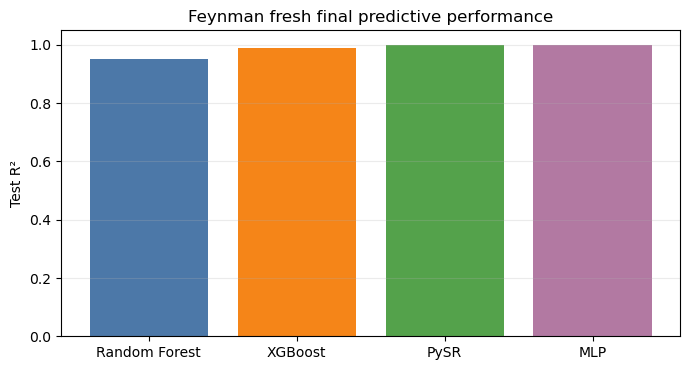

In [5]:
display(Markdown("**Historical test metrics (previously used for PySR configuration ranking)**"))
display(pd.read_csv(project_path("outputs/best_models/metrics.csv")))
display(Markdown("**MLP historical test metrics (training-only CV selection)**"))
display(mlp_table("feynman", "historical_metrics.csv"))
display(Markdown("**Fresh final evaluation after frozen validation selection**"))
feynman_performance = include_mlp(feynman_final_performance, "feynman", "metrics.csv")
display(
    feynman_performance.style.format(
        {"R2": "{:.4f}", "RMSE": "{:.6f}", "MAE": "{:.6f}"}
    )
)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(
    feynman_performance["Method"],
    feynman_performance["R2"],
    color=[COLORS[name] for name in feynman_performance["Method"]],
)
ax.set(title="Feynman fresh final predictive performance", ylabel="Test R²", ylim=(0, 1.05))
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


The native audit evaluates the literal recorded PySR expression, its symbolic simplification and saved predictions independently. Inputs are the six dimensionless ratios in manifest order; the fitted model has no additional scaler, target transform or output inverse transform. The generating equation is checked separately by symbolic subtraction. All checks are on the positive benchmark domain, excluding zero-separation singularities.


In [6]:
# Evaluate the literal saved expression as well as its symbolic simplification;
# do not substitute the known generating equation for the prediction rule.
feynman_selected = feynman_selection_audit["selected"]
symbol_namespace = {f: sp.Symbol(f) for f in feynman_features}
symbol_namespace["square"] = lambda x:x**2
feynman_native_expr = sp.sympify(feynman_selected["equation"], locals=symbol_namespace)
feynman_native_simplified = sp.simplify(feynman_native_expr)
feynman_native_fn = sp.lambdify([symbol_namespace[f] for f in feynman_features], feynman_native_simplified, "numpy")
feynman_oracle_expr = symbol_namespace["m2_m1"] / ((symbol_namespace["x2_x1"]-1)**2
    +(symbol_namespace["y2_x1"]-symbol_namespace["y1_x1"])**2
    +(symbol_namespace["z2_x1"]-symbol_namespace["z1_x1"])**2)
native_check_rows = []
for role, frame, equation, predicted in [
    ("Historical test", X_feynman_test, feynman_manifest["pysr_result"]["raw_equation"],
     pd.read_csv(project_path("outputs/best_models/test_predictions.csv"))["pysr_prediction"].to_numpy()),
    ("Fresh final", feynman_final_rows[feynman_features], feynman_selected["equation"],
     pd.read_csv(FEYNMAN_AUDIT_DIR / "final_predictions.csv")["pysr_prediction"].to_numpy()),
]:
    actual = evaluate_recorded_equation(equation, frame)
    np.testing.assert_allclose(actual, predicted, atol=1e-12, rtol=1e-12)
    native_check_rows.append({"Dataset": "Feynman", "Rows": role, "N": len(frame),
                              "Maximum prediction difference": np.max(np.abs(actual-predicted))})
simple_pred = feynman_native_fn(*[feynman_final_rows[f].to_numpy() for f in feynman_features])
np.testing.assert_allclose(simple_pred, evaluate_recorded_equation(feynman_selected["equation"], feynman_final_rows), atol=1e-12, rtol=1e-12)
feynman_pysr = {**feynman_selected, "raw_equation": feynman_selected["equation"],
                "simplified_equation": str(feynman_native_simplified)}
display(pd.DataFrame({"Raw equation": [feynman_pysr["raw_equation"]],
                      "Simplified equation": [feynman_pysr["simplified_equation"]],
                      "Complexity": [feynman_pysr["complexity"]],
                      "Symbolic difference from generating equation": [sp.simplify(feynman_native_simplified-feynman_oracle_expr)]}))
display(pd.DataFrame(native_check_rows))


,Raw equation,Simplified equation,Complexity,Symbolic difference from generating equation
0,m2_m1 / ((square(y1_x1 - y2_x1) + square(z2_x1 - z1_x1)) + square(x2_x1 - square(1.0))),m2_m1/((x2_x1 - 1.0)**2 + (y1_x1 - y2_x1)**2 + (z1_x1 - z2_x1)**2),17,0


,Dataset,Rows,N,Maximum prediction difference
0,Feynman,Historical test,2000,4.440892e-16
1,Feynman,Fresh final,2000,1.332268e-15


### Feynman: correctness

This lightweight controlled check follows the existing analysis: TreeSHAP global mean absolute magnitudes are compared with a known-equation permutation oracle over the saved test split. It is a **global synthetic-alignment check**, not a full local oracle attribution test.

This preserved calculation uses the historical test rows and assesses **agreement with the generating relationship**, not local faithfulness to each fitted model. The separate compact check below measures changes to each fitted model on a fixed subset of the fresh final data.

MLP uses exact SHAP over the same historical test rows and a fixed 50-row training background. The tree results use path-dependent TreeSHAP, so differences can reflect both the fitted models and their explanation conditioning.


In [7]:
def feynman_equation(rows):
    denominator = (
        (rows["x2_x1"].to_numpy() - 1.0) ** 2
        + (rows["y2_x1"].to_numpy() - rows["y1_x1"].to_numpy()) ** 2
        + (rows["z2_x1"].to_numpy() - rows["z1_x1"].to_numpy()) ** 2
    )
    if np.any(denominator == 0):
        raise ZeroDivisionError("The Feynman equation is undefined at zero separation.")
    return rows["m2_m1"].to_numpy() / denominator


def shap_matrix(explainer, rows):
    values = explainer.shap_values(rows, check_additivity=False)
    if isinstance(values, list):
        if len(values) != 1:
            raise ValueError("Expected one SHAP output for scalar regression.")
        values = values[0]
    values = np.asarray(values)
    if values.ndim == 3 and values.shape[-1] == 1:
        values = values[..., 0]
    if values.ndim != 2:
        raise ValueError(f"Expected a 2D SHAP matrix, received {values.shape}.")
    return values


feynman_shap_values = {}
feynman_mean_abs_shap = {}
for model_name, model in feynman_tree_models.items():
    values = shap_matrix(shap.TreeExplainer(model), X_feynman_test)
    feynman_shap_values[model_name] = values
    feynman_mean_abs_shap[model_name] = np.mean(np.abs(values), axis=0)

feynman_shap_values["MLP"] = mlp_shap("feynman")
feynman_mean_abs_shap["MLP"] = np.mean(np.abs(feynman_shap_values["MLP"]), axis=0)

oracle_rng = np.random.default_rng(feynman_manifest["random_state"])
clean_oracle_output = feynman_equation(X_feynman_test)
oracle_importance = {}
for feature in feynman_features:
    changes = []
    for _ in range(10):
        perturbed = X_feynman_test.copy()
        perturbed[feature] = oracle_rng.permutation(perturbed[feature].to_numpy())
        changes.append(np.mean(np.abs(feynman_equation(perturbed) - clean_oracle_output)))
    oracle_importance[feature] = np.mean(changes)

oracle_vector = np.array([oracle_importance[name] for name in feynman_features])
feature_labels = [name.replace("_", "/") for name in feynman_features]
feynman_ranking = pd.DataFrame(
    {
        "Feature": feature_labels,
        "Oracle importance": oracle_vector,
        "Oracle rank": pd.Series(oracle_vector).rank(method="min", ascending=False).astype(int),
    }
)

alignment_rows = []
for model_name, shap_vector in feynman_mean_abs_shap.items():
    feynman_ranking[f"{model_name} mean |SHAP|"] = shap_vector
    feynman_ranking[f"{model_name} SHAP rank"] = (
        pd.Series(shap_vector).rank(method="min", ascending=False).astype(int)
    )
    alignment_rows.append(
        {
            "Method": model_name,
            "Spearman correlation": spearmanr(shap_vector, oracle_vector).statistic,
        }
    )

feynman_alignment = pd.DataFrame(alignment_rows)
display(feynman_ranking.sort_values("Oracle rank").reset_index(drop=True).round(6))
display(feynman_alignment.style.format({"Spearman correlation": "{:.3f}"}))

,Feature,Oracle importance,Oracle rank,Random Forest mean |SHAP|,Random Forest SHAP rank,XGBoost mean |SHAP|,XGBoost SHAP rank,MLP mean |SHAP|,MLP SHAP rank
0,m2/m1,0.327671,1,0.231123,1,0.233777,1,0.236706,1
1,z1/x1,0.163436,2,0.084047,3,0.105661,3,0.118517,2
2,y1/x1,0.159806,3,0.095522,2,0.107989,2,0.115968,3
3,x2/x1,0.137255,4,0.077406,4,0.092639,4,0.101354,4
4,y2/x1,0.127991,5,0.074058,5,0.088836,5,0.094710,5
5,z2/x1,0.125322,6,0.070739,6,0.085522,6,0.092558,6


,Method,Spearman correlation
0,Random Forest,0.943
1,XGBoost,0.943
2,MLP,1.000


**Compact local fitted-model faithfulness (fresh final sample)**

A fixed input-only random subset of 50 fresh final observations is explained by TreeSHAP using training path counts for RF/XGBoost, and exact empirical-background SHAP for MLP. Paired training-donor replacements measure prediction changes in each fitted model. Three independent seeds and budgets 64, 256 and 1,024 check the replacement approximation; the reported impact is the mean of the three 1,024-donor estimates. This is separate from agreement with the generating equation above. The same tie and undefined-correlation conventions are used as in the body-fat analysis. Marginal replacements may violate shared-denominator dependencies, and TreeSHAP's path-dependent conditioning differs from marginal donor replacement.

In [8]:
RERUN_FEYNMAN_FAITHFULNESS = False
if RERUN_FEYNMAN_FAITHFULNESS:
    X_feynman_train, _, _, _ = train_test_split(X_feynman, y_feynman, test_size=.2, random_state=42)
    # Compact 50-row check from the fresh final sample, prechosen by input-only RNG.
    selected_positions = np.sort(np.random.default_rng(9020803).choice(len(feynman_final_rows), 50, replace=False))
    faith_rows = feynman_final_rows.iloc[selected_positions]
    X_faith = faith_rows[feynman_features]
    seeds, budgets = [42, 1729, 2026], [64, 256, 1024]
    n, p, d = len(X_faith), len(feynman_features), len(X_feynman_train)
    donor_indices = np.stack([np.random.default_rng(s).integers(d, size=(n,p,max(budgets))) for s in seeds])
    local_rows, convergence_rows, archive = [], [], {}
    for method, model in feynman_tree_models.items():
        model.set_params(n_jobs=1)
        explainer = shap.TreeExplainer(model)
        values = shap_matrix(explainer, X_faith)
        np.testing.assert_allclose(values.sum(axis=1)+np.asarray(explainer.expected_value).item(), model.predict(X_faith), rtol=1e-5, atol=1e-5)
        clean = model.predict(X_faith)
        per_seed = []
        for si, seed in enumerate(seeds):
            changes = np.empty((n,p,max(budgets)))
            for j in range(p):
                rows = np.repeat(X_faith.to_numpy(), max(budgets), axis=0)
                rows[:,j] = X_feynman_train.iloc[:,j].to_numpy()[donor_indices[si,:,j,:].ravel()]
                pred = model.predict(pd.DataFrame(rows, columns=feynman_features)).reshape(n,-1)
                changes[:,j,:] = np.abs(pred-clean[:,None])
            per_seed.append(changes)
        full = np.mean([c.mean(axis=2) for c in per_seed],axis=0)
        for i, subject in enumerate(faith_rows.observation_id):
            local_rows.append({"Method": method, "observation_id": subject, **local_agreement(np.abs(values[i]),full[i])})
        for budget in budgets:
            for si, seed in enumerate(seeds):
                estimate = per_seed[si][:,:,:budget].mean(axis=2)
                reference = np.mean([c.mean(axis=2) for k,c in enumerate(per_seed) if k!=si],axis=0)
                for i, subject in enumerate(faith_rows.observation_id):
                    a=local_agreement(estimate[i],reference[i])
                    convergence_rows.append({"Method": method,"Donors": budget,"Seed":seed,"observation_id":subject,
                                             "Impact rank rho":a["Spearman correlation"],
                                             "Impact top3":a["Top-three overlap"],
                                             "Normalized L1":np.abs(estimate[i]-reference[i]).sum()/max(reference[i].sum(),1e-12)})
        key=method.lower().replace(" ","_")
        archive[key+"_shap"] = values
        archive[key+"_base_values"] = explainer.expected_value
        archive[key+"_impact"] = full
        archive[key+"_donor_changes"] = np.stack(per_seed)
    local = pd.DataFrame(local_rows)
    local.to_csv(FEYNMAN_AUDIT_DIR / "local_faithfulness.csv",index=False)
    agreement_summary(local).to_csv(FEYNMAN_AUDIT_DIR / "local_faithfulness_summary.csv",index=False)
    pd.DataFrame(convergence_rows).to_csv(FEYNMAN_AUDIT_DIR / "deletion_convergence.csv",index=False)
    np.savez_compressed(FEYNMAN_AUDIT_DIR / "local_faithfulness.npz", **archive,
                        donor_indices=donor_indices, donor_training_indices=X_feynman_train.index.to_numpy(),
                        seeds=seeds, budgets=budgets, observation_ids=faith_rows.observation_id.to_numpy(dtype=str),
                        feature_names=feynman_features)
    (FEYNMAN_AUDIT_DIR / "faithfulness_manifest.json").write_text(json.dumps({
        "status":"completed", "subset_seed":9020803,"n":50,"seeds":seeds,"budgets":budgets,
        "final_estimate":"mean of 3 independent 1024-donor estimates; paired donors across models",
        "explanation":"TreeSHAP tree_path_dependent; training path counts as background; identity link",
        "comparison":"absolute TreeSHAP vs changes to the fitted model, separate from generating-equation alignment",
        "limitations":"Compact sample only; empirical marginal replacement can violate ratio dependencies and differ from path-dependent SHAP conditioning"
    },indent=2),encoding="utf-8")
feynman_local_summary = include_mlp(pd.read_csv(FEYNMAN_AUDIT_DIR / "local_faithfulness_summary.csv"),
                                    "feynman", "local_correctness_summary.csv")
display(feynman_local_summary.round(4))
feynman_budget_check = include_mlp(pd.read_csv(FEYNMAN_AUDIT_DIR / "deletion_convergence.csv"),
                                   "feynman", "deletion_budget_rows.csv")
display(feynman_budget_check.groupby(["Method","Donors"]).agg(
    rank_rho_median=("Impact rank rho","median"), top3_mean=("Impact top3","mean"),
    L1_p90=("Normalized L1",lambda s:s.quantile(.9))).round(4))


display(Markdown("At 1,024 donors per seed, the two tree models have median impact-rank correlation 1.0, mean top-three agreement above 0.97, and 90th-percentile normalized impact L1 below 0.03 against independent-seed references. The three-seed average is adequate for this compact descriptive ranking check; close feature ranks can still change."))

display(Markdown("MLP uses the same three seeds and donor budgets. Its convergence results are reported above without inheriting the tree-model adequacy claim."))


,Method,Metric,N,Defined N,Undefined N,Median,Q1,Q3,IQR
0,Random Forest,Spearman correlation,50,50,0,0.6571,0.3714,0.8286,0.4571
1,Random Forest,Top-three overlap,50,50,0,0.6667,0.6667,1.0000,0.3333
2,XGBoost,Spearman correlation,50,50,0,0.7714,0.5429,0.8286,0.2857
3,XGBoost,Top-three overlap,50,50,0,0.6667,0.6667,1.0000,0.3333
4,MLP,Spearman correlation,50,50,0,0.7714,0.5571,0.8286,0.2714
5,MLP,Top-three overlap,50,50,0,0.6667,0.6667,1.0000,0.3333


rank_rho_median  top3_mean  L1_p90
Method        Donors                                    
MLP           64               0.9429     0.9067  0.1007
              256              1.0000     0.9467  0.0517
              1024             1.0000     0.9756  0.0298
Random Forest 64               0.9429     0.9311  0.1042
              256              1.0000     0.9733  0.0521
              1024             1.0000     0.9911  0.0296
XGBoost       64               1.0000     0.9178  0.0992
              256              1.0000     0.9556  0.0514
              1024             1.0000     0.9711  0.0290

At 1,024 donors per seed, the two tree models have median impact-rank correlation 1.0, mean top-three agreement above 0.97, and 90th-percentile normalized impact L1 below 0.03 against independent-seed references. The three-seed average is adequate for this compact descriptive ranking check; close feature ranks can still change.

MLP uses the same three seeds and donor budgets. Its convergence results are reported above without inheriting the tree-model adequacy claim.

### Feynman: supplementary native feature importance versus SHAP

This supplementary comparison asks whether each fitted tree model's native feature importance agrees with its **global mean absolute SHAP ranking**. It uses the same six dimensionless model inputs and the existing `feynman_mean_abs_shap` values over the 2,000 historical test rows from the correctness section above. These remain historical diagnostics, not the fresh final evaluation sample. No model is fitted or selected here.

- **Random Forest:** normalised mean decrease in impurity (MDI), obtained from `feature_importances_`.
- **XGBoost:** explicitly requested **gain**, the average training-loss reduction across splits using each feature, normalised across features. This is not split count (`weight`) or summed gain (`total_gain`). Unused features receive zero.
- **SHAP:** mean absolute attribution across the stated evaluation rows. Its raw magnitude is in prediction units; for charts only, each importance vector is separately normalised to sum to one. Normalisation enables comparison of relative allocations, not equality of meaning.

Rank 1 denotes the most important feature. Spearman correlation uses average ranks for ties and is undefined for a constant vector. Top-three overlap is the shared fraction of the three selected features (0–1); if a tie crosses the third-place boundary, fractional membership gives the expected overlap under independent uniform tie-breaking. Positive **SHAP rank minus native rank** means the feature ranks lower under SHAP.

Native importance describes training splits, whereas SHAP summarises contributions to evaluated predictions. Agreement is descriptive consistency between these summaries, not proof of correctness, causality or complete model transparency. Disagreement can reflect these different definitions, the evaluation distribution and correlated inputs. MDI can also favour features with many possible split points. With only six features, rank correlations are descriptive; no significance test or overall explanation-quality score is assigned. SHAP remains applicable to tree ensembles even when native importances are available.

Definitions: [scikit-learn RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html), [XGBoost get_score](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.Booster.get_score), and [SHAP TreeExplainer](https://shap.readthedocs.io/en/stable/generated/shap.TreeExplainer.html).

**MLP is intentionally excluded:** the saved MLP has no native split-based feature importance. Network weights are not substituted for MDI or gain.


In [9]:
def native_importance_vector(model, method, features):
    """Read native importance in recorded model-input order, without changing models."""
    features = list(features)
    if len(set(features)) != len(features) or model.n_features_in_ != len(features):
        raise ValueError("Feature names must be unique and match the fitted input count.")
    if hasattr(model, "feature_names_in_"):
        np.testing.assert_array_equal(model.feature_names_in_, features)
    if method == "Random Forest":
        values = np.asarray(model.feature_importances_, dtype=float)
        definition = "MDI"
    elif method == "XGBoost":
        booster = model.get_booster()
        if booster.feature_names is not None:
            np.testing.assert_array_equal(booster.feature_names, features)
            keys = features
        else:
            keys = [f"f{i}" for i in range(len(features))]
        scores = booster.get_score(importance_type="gain")
        if not set(scores).issubset(keys):
            raise ValueError("Unexpected XGBoost feature names in gain scores.")
        values = np.array([scores.get(key, 0.0) for key in keys], dtype=float)
        definition = "Gain"
    else:
        raise ValueError(f"Unsupported native importance method: {method}")
    if values.shape != (len(features),) or not np.isfinite(values).all() or (values < 0).any():
        raise ValueError("Native importances must be finite, non-negative feature vectors.")
    return values, definition


def importance_top_membership(values, k=3):
    """Fractional top-k membership only where ties cross the selection boundary."""
    values = np.asarray(values, dtype=float)
    k = min(k, len(values))
    boundary = np.sort(values)[-k]
    above, tied = values > boundary, values == boundary
    return above.astype(float) + tied * ((k - above.sum()) / tied.sum())


def compare_native_with_shap(models, features, mean_absolute_shap, dataset, n_rows):
    """Return per-feature results and descriptive within-model agreement."""
    feature_tables, agreement_rows = [], []
    for method, model in models.items():
        native, definition = native_importance_vector(model, method, features)
        shap_magnitude = np.asarray(mean_absolute_shap[method], dtype=float)
        if (shap_magnitude.shape != native.shape or not np.isfinite(shap_magnitude).all()
                or (shap_magnitude < 0).any()):
            raise ValueError("Mean absolute SHAP must match the native feature vector.")
        native_share = native / native.sum() if native.sum() > 0 else np.zeros_like(native)
        shap_share = (shap_magnitude / shap_magnitude.sum()
                      if shap_magnitude.sum() > 0 else np.zeros_like(shap_magnitude))
        native_rank = pd.Series(native).rank(ascending=False, method="average").to_numpy()
        shap_rank = pd.Series(shap_magnitude).rank(ascending=False, method="average").to_numpy()
        rho = (float(spearmanr(native, shap_magnitude).statistic)
               if np.ptp(native) > 0 and np.ptp(shap_magnitude) > 0 else np.nan)
        native_top = importance_top_membership(native)
        shap_top = importance_top_membership(shap_magnitude)
        k = min(3, len(features))
        feature_tables.append(pd.DataFrame({
            "Dataset": dataset, "Method": method, "Feature": features,
            "Native definition": definition, "Native importance (normalised)": native_share,
            "Mean absolute SHAP": shap_magnitude, "SHAP share": shap_share,
            "Native rank": native_rank, "SHAP rank": shap_rank,
            "SHAP rank minus native rank": shap_rank - native_rank,
            "Native top-three membership": native_top, "SHAP top-three membership": shap_top,
        }))
        agreement_rows.append({
            "Dataset": dataset, "Method": method, "Native definition": definition,
            "Evaluation rows": n_rows, "Features": len(features),
            "Spearman correlation": rho,
            "Top-three overlap": float(np.dot(native_top, shap_top) / k),
            "Third-place boundary tie": bool(
                ((native_top > 0) & (native_top < 1)).any()
                or ((shap_top > 0) & (shap_top < 1)).any()),
            "Zero native total": bool(native.sum() == 0),
            "Zero SHAP total": bool(shap_magnitude.sum() == 0),
        })
    return pd.concat(feature_tables, ignore_index=True), pd.DataFrame(agreement_rows)


def display_native_shap_comparison(feature_table, agreement, dataset):
    display(agreement.style.format({"Spearman correlation": "{:.3f}", "Top-three overlap": "{:.3f}"}))
    methods = agreement["Method"].tolist()
    fig, axes = plt.subplots(1, len(methods), figsize=(14, max(4.5, feature_table["Feature"].nunique() * .36)),
                             squeeze=False, layout="constrained")
    for ax, method in zip(axes.ravel(), methods):
        table = feature_table.loc[feature_table["Method"] == method].sort_values(
            ["SHAP rank", "Native rank", "Feature"], kind="stable")
        definition = table["Native definition"].iloc[0]
        display(Markdown(f"**{dataset} — {method}: feature rankings**"))
        display(table[["Feature", "Native importance (normalised)", "Mean absolute SHAP",
                       "SHAP share", "Native rank", "SHAP rank", "SHAP rank minus native rank"]]
                .reset_index(drop=True).style.format({
                    "Native importance (normalised)": "{:.4f}", "Mean absolute SHAP": "{:.6f}",
                    "SHAP share": "{:.4f}", "Native rank": "{:.1f}", "SHAP rank": "{:.1f}",
                    "SHAP rank minus native rank": "{:+.1f}"}))
        positions = np.arange(len(table))
        ax.barh(positions - .19, table["Native importance (normalised)"], height=.36,
                label=f"Native {definition}", color="#4C78A8")
        ax.barh(positions + .19, table["SHAP share"], height=.36,
                label="Mean |SHAP| share", color="#F58518")
        ax.set_yticks(positions, table["Feature"])
        ax.invert_yaxis()
        ax.set_xlabel("Share of each method's total importance")
        ax.set_title(method)
        ax.grid(axis="x", alpha=.2)
        ax.set_axisbelow(True)
        ax.legend(loc="lower right")
    fig.suptitle(f"{dataset}: native feature importance versus mean absolute SHAP")
    plt.show()
    plt.close(fig)
    observations = []
    for row in agreement.to_dict("records"):
        table = feature_table.loc[feature_table["Method"] == row["Method"]]
        native_leaders = ", ".join(table.loc[table["Native rank"] == table["Native rank"].min(), "Feature"])
        shap_leaders = ", ".join(table.loc[table["SHAP rank"] == table["SHAP rank"].min(), "Feature"])
        rho_text = f"{row['Spearman correlation']:.3f}" if np.isfinite(row["Spearman correlation"]) else "undefined (constant vector)"
        observations.append(
            f"**{row['Method']}:** Spearman correlation = {rho_text}; top-three overlap = "
            f"{row['Top-three overlap']:.3f}. Highest native importance: {native_leaders}; "
            f"highest mean absolute SHAP: {shap_leaders}.")
    display(Markdown("**Within-section observations.**\n\n" + "\n\n".join(observations)
                     + "\n\nThese values describe global ranking agreement for these fitted models and evaluation rows; "
                     "they do not establish correctness or replace the existing local explanation audits."))


,Dataset,Method,Native definition,Evaluation rows,Features,Spearman correlation,Top-three overlap,Third-place boundary tie,Zero native total,Zero SHAP total
0,Feynman (historical test),Random Forest,MDI,2000,6,0.943,1.000,False,False,False
1,Feynman (historical test),XGBoost,Gain,2000,6,0.829,1.000,False,False,False


**Feynman (historical test) — Random Forest: feature rankings**

,Feature,Native importance (normalised),Mean absolute SHAP,SHAP share,Native rank,SHAP rank,SHAP rank minus native rank
0,m2_m1,0.5833,0.231123,0.3652,1.0,1.0,+0.0
1,y1_x1,0.1081,0.095522,0.1509,2.0,2.0,+0.0
2,z1_x1,0.0918,0.084047,0.1328,3.0,3.0,+0.0
3,x2_x1,0.0756,0.077406,0.1223,4.0,4.0,+0.0
4,y2_x1,0.0696,0.074058,0.1170,6.0,5.0,-1.0
5,z2_x1,0.0716,0.070739,0.1118,5.0,6.0,+1.0


**Feynman (historical test) — XGBoost: feature rankings**

,Feature,Native importance (normalised),Mean absolute SHAP,SHAP share,Native rank,SHAP rank,SHAP rank minus native rank
0,m2_m1,0.5335,0.233777,0.3272,1.0,1.0,+0.0
1,y1_x1,0.1238,0.107989,0.1512,2.0,2.0,+0.0
2,z1_x1,0.0991,0.105661,0.1479,3.0,3.0,+0.0
3,x2_x1,0.0784,0.092639,0.1297,6.0,4.0,-2.0
4,y2_x1,0.0853,0.088836,0.1243,4.0,5.0,+1.0
5,z2_x1,0.0799,0.085522,0.1197,5.0,6.0,+1.0


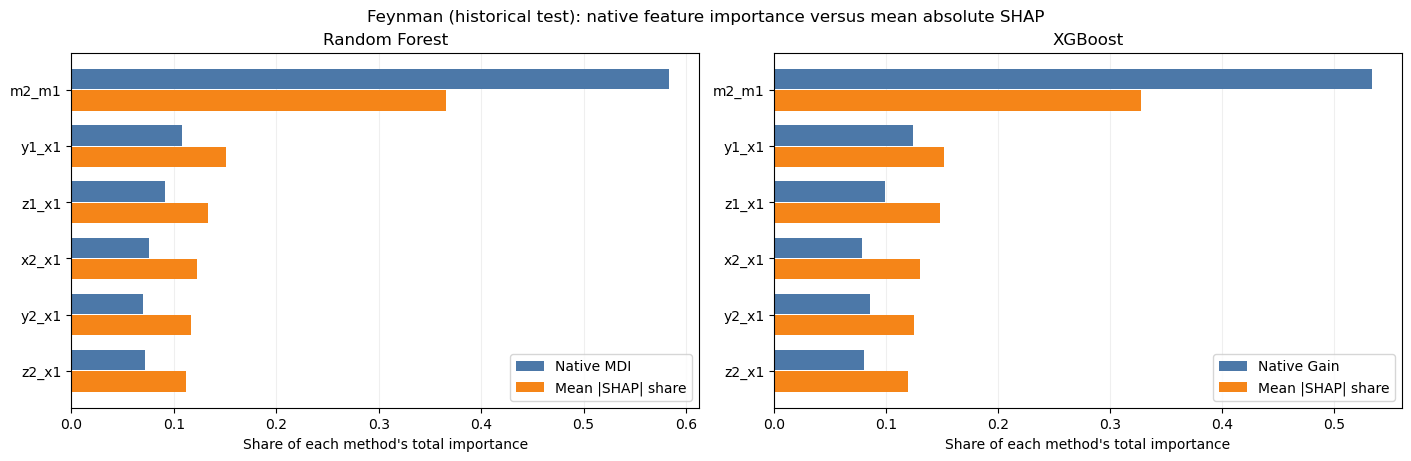

**Within-section observations.**

**Random Forest:** Spearman correlation = 0.943; top-three overlap = 1.000. Highest native importance: m2_m1; highest mean absolute SHAP: m2_m1.

**XGBoost:** Spearman correlation = 0.829; top-three overlap = 1.000. Highest native importance: m2_m1; highest mean absolute SHAP: m2_m1.

These values describe global ranking agreement for these fitted models and evaluation rows; they do not establish correctness or replace the existing local explanation audits.

In [10]:
feynman_native_shap_features, feynman_native_shap_agreement = compare_native_with_shap(
    feynman_tree_models, feynman_features, feynman_mean_abs_shap,
    dataset="Feynman (historical test)", n_rows=len(X_feynman_test),
)
display_native_shap_comparison(
    feynman_native_shap_features, feynman_native_shap_agreement, "Feynman (historical test)"
)


### Feynman: completeness

Following Nauta et al. (2023, Sections 3.3, 6.1 and 6.2), **output-completeness** is tested functionally: does the SHAP-selected feature set retain enough information to reproduce the fitted model output, and does removing it materially change that output? Features are ranked separately for every observation and model by decreasing absolute SHAP magnitude; ties use the existing stable feature order.

For each $k=0,\ldots,p$, the preservation/addition curve keeps the first $k$ ranked features at their observed values and replaces the remainder with a single empirical training-donor row. Its ordinate is mean absolute error from the original full-input regression prediction, so lower and a faster fall are preferred. The deletion curve replaces the first $k$ features from the same donor row and reports mean absolute prediction change, so higher and a faster rise are preferred. The horizontal axis is $k/p$: fraction retained for preservation and fraction replaced for deletion. Thirty-two independently shuffled feature orders form the matched random baseline. Donor rows and random orders are paired across RF, XGBoost and MLP and across checks.

Raw curves remain in target units. For a scale-free display, each subject is divided by its own mean absolute all-features-replaced change. Denominators at or below $10^{-6}$ of the model's training-prediction standard deviation (with a $10^{-12}$ floor) are reported as undefined, never replaced by zero; normalized values are not clipped. Curves are not forced to be monotone. The audit reports direction reversals and defines the reconstruction count as the smallest $k$ for which preservation error is within a tolerance of 5% of that fitted model's training-prediction standard deviation **and remains within tolerance for all larger $k$**.

The 90%-SHAP subset is the smallest local prefix whose cumulative absolute SHAP magnitude reaches 90%. Preservation and deletion are evaluated at that prefix, but 90% attribution coverage is not called 90% prediction recovery. Full-attribution additivity is checked numerically as a validation of the saved arrays; additivity alone does not show that SHAP exposes the model's entire internal reasoning.

,Method,Mean features for 90% absolute SHAP,Mean normalized preservation error at 90% SHAP,Mean matched-random normalized preservation error,Mean normalized deletion change at 90% SHAP,Mean matched-random normalized deletion change,Reconstruction tolerance,Median sustained reconstruction features,Subjects with preservation direction reversal,Subjects with deletion direction reversal,Subjects with undefined normalization
0,Random Forest,4.64,0.3027,0.4155,0.9049,0.8479,0.0191,6.0,36,48,0
1,XGBoost,4.42,0.3665,0.5073,0.9028,0.8589,0.0198,6.0,38,47,0
2,MLP,4.54,0.3104,0.4908,0.9530,0.8800,0.0198,6.0,38,48,0


,Dataset,Method,Full-preservation maximum error,Zero-deletion maximum change,All-replaced endpoint maximum discrepancy,Maximum additivity residual,Median additivity residual,Numerical endpoint floor,Normalization epsilon
0,Feynman,Random Forest,0.000e+00,0.000e+00,0.000e+00,3.841e-14,8.826e-15,0.000000,0.000000
1,Feynman,XGBoost,0.000e+00,0.000e+00,0.000e+00,1.663e-06,2.767e-07,0.000000,0.000000
2,Feynman,MLP,0.000e+00,0.000e+00,0.000e+00,2.220e-15,6.661e-16,0.000000,0.000000


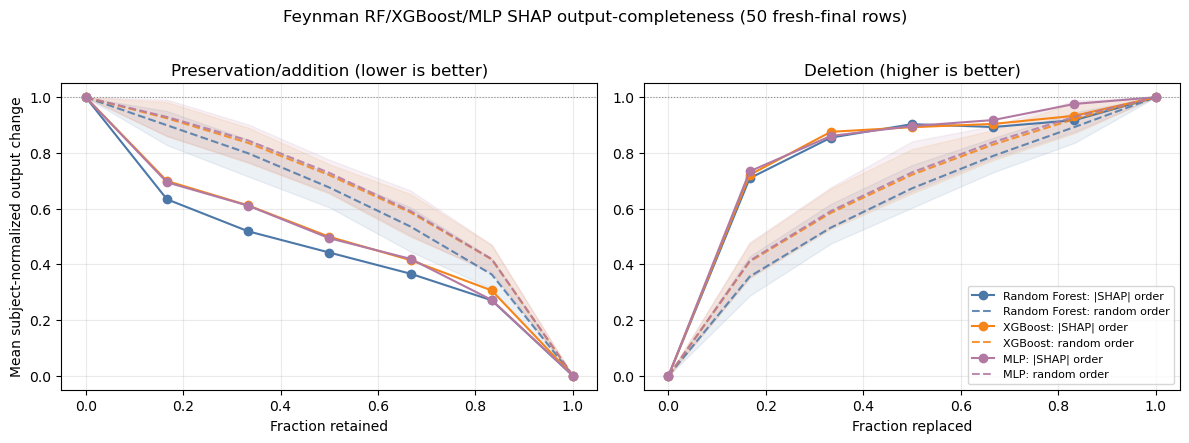

In [11]:
from scripts.explanation_metrics import COMPLETENESS_PROTOCOL_VERSION, run_output_completeness

def plot_completeness_curves(curves, title, output_path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    metrics = [
        ("Normalized preservation error", "Preservation/addition (lower is better)"),
        ("Normalized deletion change", "Deletion (higher is better)"),
    ]
    for ax, (metric, panel_title) in zip(axes, metrics):
        for method in SHAP_METHODS:
            shap_curve = (
                curves[(curves.Method == method) & (curves.Ordering == "Absolute SHAP")]
                .groupby("Fraction selected")[metric]
                .mean()
                .sort_index()
            )
            random_repeats = (
                curves[(curves.Method == method) & (curves.Ordering == "Random")]
                .groupby(["Order repeat", "Fraction selected"])[metric]
                .mean()
                .unstack("Fraction selected")
            )
            x = shap_curve.index.to_numpy(dtype=float)
            centre = random_repeats.mean(axis=0).to_numpy(dtype=float)
            lower = random_repeats.quantile(0.025, axis=0).to_numpy(dtype=float)
            upper = random_repeats.quantile(0.975, axis=0).to_numpy(dtype=float)
            ax.plot(
                x,
                shap_curve.to_numpy(),
                marker="o",
                color=COLORS[method],
                label=f"{method}: |SHAP| order",
            )
            ax.plot(
                x,
                centre,
                linestyle="--",
                color=COLORS[method],
                alpha=0.85,
                label=f"{method}: random order",
            )
            ax.fill_between(x, lower, upper, color=COLORS[method], alpha=0.10)
        ax.axhline(1, color="0.55", linewidth=0.8, linestyle=":")
        ax.set_title(panel_title)
        ax.set_xlabel(
            "Fraction retained" if "Preservation" in panel_title else "Fraction replaced"
        )
        ax.grid(alpha=0.25)
    axes[0].set_ylabel("Mean subject-normalized output change")
    axes[1].legend(fontsize=8, loc="best")
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    fig.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()


RERUN_FEYNMAN_COMPLETENESS = False
FEYNMAN_COMPLETENESS_REQUIRED = [
    FEYNMAN_AUDIT_DIR / "completeness_manifest.json",
    FEYNMAN_AUDIT_DIR / "completeness_curves.csv",
    FEYNMAN_AUDIT_DIR / "completeness_subjects.csv",
    FEYNMAN_AUDIT_DIR / "completeness_summary.csv",
    FEYNMAN_AUDIT_DIR / "completeness_endpoint_checks.csv",
    FEYNMAN_AUDIT_DIR / "completeness_design.npz",
]
feynman_completeness_stale = False
if FEYNMAN_COMPLETENESS_REQUIRED[0].exists():
    feynman_completeness_stale = (
        json.loads(FEYNMAN_COMPLETENESS_REQUIRED[0].read_text(encoding="utf-8"))
        .get("protocol_version")
        != COMPLETENESS_PROTOCOL_VERSION
    )

if RERUN_FEYNMAN_COMPLETENESS or feynman_completeness_stale or not all(
    path.exists() for path in FEYNMAN_COMPLETENESS_REQUIRED
):
    X_feynman_train, _, _, _ = train_test_split(
        X_feynman,
        y_feynman,
        test_size=feynman_manifest["test_size"],
        random_state=feynman_manifest["random_state"],
    )
    with np.load(FEYNMAN_AUDIT_DIR / "local_faithfulness.npz") as archive:
        np.testing.assert_array_equal(archive["feature_names"], feynman_features)
        np.testing.assert_array_equal(
            archive["donor_training_indices"], X_feynman_train.index.to_numpy()
        )
        feynman_completeness_ids = archive["observation_ids"].astype(str)
        feynman_completeness_shap = {
            method: archive[method.lower().replace(" ", "_") + "_shap"].copy()
            for method in feynman_tree_models
        }
        feynman_completeness_base = {
            method: archive[method.lower().replace(" ", "_") + "_base_values"].copy()
            for method in feynman_tree_models
        }
    feynman_completeness_rows = (
        feynman_final_rows.set_index("observation_id")
        .loc[feynman_completeness_ids, feynman_features]
        .reset_index(drop=True)
    )
    feynman_donor_indices = np.random.default_rng(9020810).integers(
        len(X_feynman_train), size=(len(feynman_completeness_rows), 512)
    )
    feynman_predictors = {
        name: (lambda frame, model=model: np.asarray(model.predict(frame)).ravel())
        for name, model in feynman_tree_models.items()
    }
    run_output_completeness(
        dataset="Feynman",
        output_dir=FEYNMAN_AUDIT_DIR,
        X_eval=feynman_completeness_rows,
        observation_ids=feynman_completeness_ids,
        X_training=X_feynman_train,
        donor_pool=X_feynman_train,
        donor_indices=feynman_donor_indices,
        feature_names=feynman_features,
        predictors=feynman_predictors,
        shap_values=feynman_completeness_shap,
        base_values=feynman_completeness_base,
        random_repeats=32,
        random_order_seed=9020811,
        target_unit="dimensionless target units",
        shap_source="outputs/best_models/selection_audit/local_faithfulness.npz; TreeSHAP on 50 input-only-selected fresh-final rows",
        donor_protocol="512 paired whole-row draws with replacement per explained row from the reconstructed 8,000-row training split; seed 9020810",
        source_files=[
            "outputs/best_models/random_forest_best.joblib",
            "outputs/best_models/xgboost_best.joblib",
            "outputs/best_models/selection_audit/local_faithfulness.npz",
            "outputs/best_models/selection_audit/final_rows.csv",
        ],
    )

feynman_completeness_curves = include_mlp(pd.read_csv(FEYNMAN_AUDIT_DIR / "completeness_curves.csv"), "feynman", "completeness_curves.csv")
feynman_completeness_subjects = include_mlp(pd.read_csv(FEYNMAN_AUDIT_DIR / "completeness_subjects.csv"), "feynman", "completeness_subjects.csv")
feynman_completeness_summary = include_mlp(pd.read_csv(FEYNMAN_AUDIT_DIR / "completeness_summary.csv"), "feynman", "completeness_summary.csv")
feynman_completeness_endpoints = include_mlp(pd.read_csv(FEYNMAN_AUDIT_DIR / "completeness_endpoint_checks.csv"), "feynman", "completeness_endpoint_checks.csv")
display(
    feynman_completeness_summary[
        [
            "Method",
            "Mean features for 90% absolute SHAP",
            "Mean normalized preservation error at 90% SHAP",
            "Mean matched-random normalized preservation error",
            "Mean normalized deletion change at 90% SHAP",
            "Mean matched-random normalized deletion change",
            "Reconstruction tolerance",
            "Median sustained reconstruction features",
            "Subjects with preservation direction reversal",
            "Subjects with deletion direction reversal",
            "Subjects with undefined normalization",
        ]
    ].round(4)
)
display(feynman_completeness_endpoints.style.format({
    "Full-preservation maximum error": "{:.3e}",
    "Zero-deletion maximum change": "{:.3e}",
    "All-replaced endpoint maximum discrepancy": "{:.3e}",
    "Maximum additivity residual": "{:.3e}",
    "Median additivity residual": "{:.3e}",
}))
plot_completeness_curves(
    feynman_completeness_curves,
    "Feynman RF/XGBoost/MLP SHAP output-completeness (50 fresh-final rows)",
    COMPARISON_DIRS["feynman"] / "completeness_curves.png",
)

**Interpretation.** The preservation and deletion curves quantify only how well the locally SHAP-ranked subsets recover or disrupt these fitted model outputs under the stated empirical donor intervention. They are compared with matched random orders, and their unsmoothed reversals are retained rather than hidden. The independently reported sustained-tolerance count is the prediction-reconstruction result; it is not inferred from the 90%-SHAP count.

The validation-selected PySR expression, together with its six dimensionless inputs and identity output mapping audited above, is the complete executable prediction rule for that fitted symbolic model. It is therefore reasoning-complete with respect to its own model. On this controlled benchmark the separate symbolic subtraction additionally shows equality to the generating equation on the audited domain, but structural completeness alone would not establish a complete or correct description of a real-world phenomenon. SHAP is not applied to PySR in this primary completeness comparison.

### Feynman: continuity

Three different results are kept separate. Aggregate RMSE under noise describes predictive accuracy; mean absolute prediction change describes the sensitivity of individual fitted predictions; RF/XGBoost TreeSHAP and MLP exact-SHAP continuity describes explanation change only for pairs whose fitted prediction changes by at most 5% of the training-response standard deviation. The primary threshold is therefore **0.019850 target units**. A proportionate sensitivity check repeats the filter at 2.5%, 5% and 10% of that standard deviation.

The existing paired Gaussian perturbations are retained: 100 repeats on the same 2,000 historical test rows for prediction sensitivity, and the original fixed random subset of 50 rows with 20 repeats at each non-zero level for explanations. TreeSHAP is recomputed using a fixed `tree_path_dependent` background (the training path counts encoded in each frozen tree). Two fresh TreeExplainers independently recompute unchanged inputs; the original SHAP array is not reused as its own zero-noise repeat.

Explanation direction is cosine similarity. If both attribution vectors are zero, cosine is defined as 1; if exactly one is zero, it is 0. Magnitude change is the **mean absolute attribution distance**, $p^{-1}\sum_j |\phi_j(x')-\phi_j(x)|$, in target units per feature. It is 0 for two zero vectors and retains the non-zero magnitude when only one vector is zero. Error bars on explanation results are empirical 2.5th and 97.5th percentiles of the repeat-level means across perturbations of the same fixed subjects; they are not population confidence intervals.

The PySR model uses one fixed global equation, so its text and operation graph are structurally unchanged across inputs. Its saved noisy-prediction results are shown only as **equation/model sensitivity**. They are not converted into SHAP cosine or attribution distance and do not establish superior explanation continuity.
MLP reuses the 50 saved subject identifiers, 20 explanation repeats, all 100 prediction repeats, and identical perturbations and thresholds. Its fixed 50-row training background is separate from the training-path conditioning of TreeSHAP.


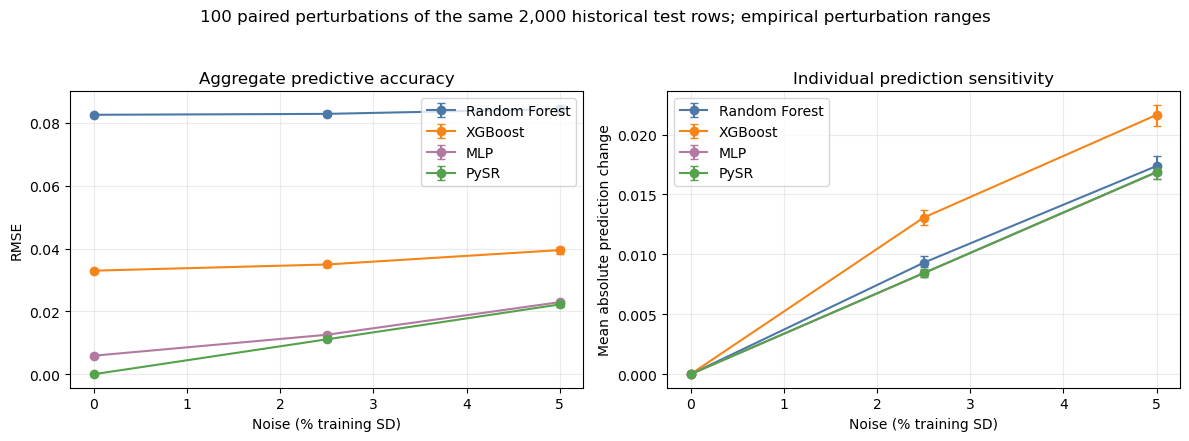

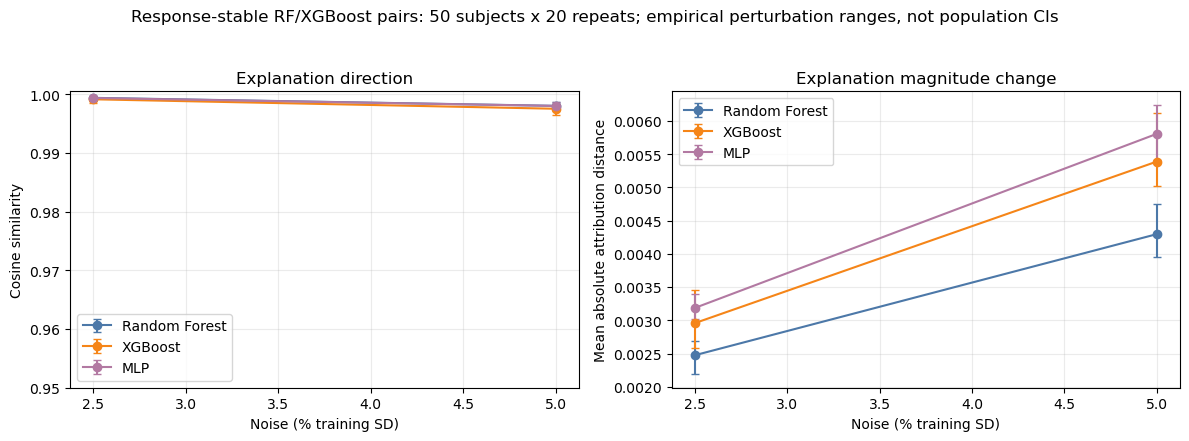

**Primary RF/XGBoost/MLP SHAP continuity (5% response-SD threshold)**

,Method,Noise (% training SD),Explanation subjects,Perturbation repeats,Candidate explanation pairs,Retained explanation pairs,Retained proportion,Response-stability threshold (target units),Mean cosine similarity,Repeat-mean cosine 2.5%,Repeat-mean cosine 97.5%,Mean absolute attribution distance,Repeat-mean attribution distance 2.5%,Repeat-mean attribution distance 97.5%,Both-zero vector pairs,One-zero vector pairs
0,Random Forest,2.5,50,20,1000,865,0.865,0.01985,0.999391,0.999222,0.999542,0.002474,0.002188,0.002696,0,0
1,XGBoost,2.5,50,20,1000,724,0.724,0.01985,0.999145,0.998467,0.999579,0.002957,0.002581,0.003458,0,0
2,Random Forest,5.0,50,20,1000,660,0.660,0.01985,0.998029,0.997261,0.998723,0.004298,0.003960,0.004752,0,0
3,XGBoost,5.0,50,20,1000,517,0.517,0.01985,0.997532,0.996436,0.998357,0.005390,0.005016,0.006127,0,0
4,MLP,2.5,50,20,1000,917,0.917,0.01985,0.999361,0.998978,0.999545,0.003186,0.003012,0.003393,0,0
5,MLP,5.0,50,20,1000,626,0.626,0.01985,0.998018,0.997377,0.998607,0.005808,0.005409,0.006244,0,0


**Response-threshold sensitivity**

,Method,Noise (% training SD),Threshold (% training response SD),Threshold (target units),Candidate explanation pairs,Retained explanation pairs,Retained proportion,Mean cosine similarity,Mean absolute attribution distance
0,Random Forest,2.5,2.5,0.009925,1000,645,0.645,0.999494,0.002176
1,XGBoost,2.5,2.5,0.009925,1000,490,0.490,0.999312,0.002482
2,Random Forest,5.0,2.5,0.009925,1000,395,0.395,0.998152,0.004049
3,XGBoost,5.0,2.5,0.009925,1000,290,0.290,0.997848,0.004901
4,Random Forest,2.5,5.0,0.019850,1000,865,0.865,0.999391,0.002474
5,XGBoost,2.5,5.0,0.019850,1000,724,0.724,0.999145,0.002957
6,Random Forest,5.0,5.0,0.019850,1000,660,0.660,0.998029,0.004298
7,XGBoost,5.0,5.0,0.019850,1000,517,0.517,0.997532,0.005390
8,Random Forest,2.5,10.0,0.039700,1000,962,0.962,0.999191,0.002768
9,XGBoost,2.5,10.0,0.039700,1000,920,0.920,0.998770,0.003646


**Independent unchanged-input SHAP repeatability**

...

,Noise (% training SD),Evaluated subject-perturbation rows,Finite input rows,Minimum equation denominator,Numerical singularity tolerance,Near-zero denominators,Finite PySR predictions,Maximum absolute PySR prediction
0,2.5,200000,200000,0.437340,0.0,0,200000,3.616572
1,5.0,200000,200000,0.426447,0.0,0,200000,3.710288


**Zero-noise prediction checks**

,Method,Rows,Maximum zero-noise prediction change,Exact zero-noise check
0,Random Forest,2000,0.0,True
1,XGBoost,2000,0.0,True
2,PySR,2000,0.0,True
3,MLP,2000,0.0,True


Response-stability threshold: 0.019850 target units; TreeSHAP background: fixed training path counts encoded in the frozen trees.


MLP uses exact empirical-background SHAP; the existing trees use path-dependent TreeSHAP. Explainer conditioning differs.

In [12]:
FEYNMAN_CONTINUITY_DIR = FEYNMAN_AUDIT_DIR
RERUN_FEYNMAN_CONTINUITY = False
feynman_continuity_required = [
    FEYNMAN_CONTINUITY_DIR / "continuity_manifest.json",
    FEYNMAN_CONTINUITY_DIR / "continuity_summary.csv",
    FEYNMAN_CONTINUITY_DIR / "continuity_repeat_summary.csv",
    FEYNMAN_CONTINUITY_DIR / "continuity_threshold_sensitivity.csv",
    FEYNMAN_CONTINUITY_DIR / "continuity_identical_input_repeats.csv",
    FEYNMAN_CONTINUITY_DIR / "continuity_native_equation_domain.csv",
    FEYNMAN_CONTINUITY_DIR / "continuity_zero_noise_prediction_checks.csv",
]
if RERUN_FEYNMAN_CONTINUITY or not all(path.exists() for path in feynman_continuity_required):
    from scripts.feynman_continuity_audit import run_feynman_continuity
    run_feynman_continuity(PROJECT_ROOT)

feynman_noise = pd.read_csv(project_path("outputs/best_models/noise_sensitivity.csv"))
feynman_noise_repeats = pd.read_csv(
    project_path("outputs/best_models/noise_sensitivity_repeats.csv")
)
with (FEYNMAN_CONTINUITY_DIR / "continuity_manifest.json").open(encoding="utf-8") as handle:
    feynman_continuity_manifest = json.load(handle)
feynman_continuity = pd.read_csv(FEYNMAN_CONTINUITY_DIR / "continuity_summary.csv")
feynman_continuity_repeats = pd.read_csv(
    FEYNMAN_CONTINUITY_DIR / "continuity_repeat_summary.csv"
)
feynman_threshold_sensitivity = pd.read_csv(
    FEYNMAN_CONTINUITY_DIR / "continuity_threshold_sensitivity.csv"
)
feynman_repeatability = pd.read_csv(
    FEYNMAN_CONTINUITY_DIR / "continuity_identical_input_repeats.csv"
)
feynman_native_domain = pd.read_csv(
    FEYNMAN_CONTINUITY_DIR / "continuity_native_equation_domain.csv"
)
feynman_zero_noise = pd.read_csv(
    FEYNMAN_CONTINUITY_DIR / "continuity_zero_noise_prediction_checks.csv"
)

def errorbar_from_columns(frame, centre, lower, upper):
    return np.vstack([
        np.maximum(frame[centre].to_numpy() - frame[lower].to_numpy(), 0),
        np.maximum(frame[upper].to_numpy() - frame[centre].to_numpy(), 0),
    ])

feynman_noise = include_mlp(feynman_noise, "feynman", "noise_sensitivity.csv")
feynman_noise_repeats = include_mlp(feynman_noise_repeats, "feynman", "noise_sensitivity_repeats.csv")
feynman_continuity = include_mlp(feynman_continuity, "feynman", "continuity_summary.csv")
feynman_continuity_repeats = include_mlp(feynman_continuity_repeats, "feynman", "continuity_repeat_summary.csv")
feynman_threshold_sensitivity = include_mlp(feynman_threshold_sensitivity, "feynman", "continuity_threshold_sensitivity.csv")
feynman_zero_noise = include_mlp(feynman_zero_noise, "feynman", "continuity_zero_noise_prediction_checks.csv")
feynman_repeatability = include_mlp(feynman_repeatability, "feynman", "shap_identical_input_repeats.csv")

prediction_ranges = (
    feynman_noise_repeats.groupby(["Method", "Noise (% training SD)"])
    ["Mean absolute prediction change"]
    .quantile([0.025, 0.975])
    .unstack()
    .reset_index()
    .rename(columns={0.025: "Prediction change 2.5%", 0.975: "Prediction change 97.5%"})
)
feynman_prediction_plot = feynman_noise.merge(
    prediction_ranges, on=["Method", "Noise (% training SD)"], how="left"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for method in PREDICTIVE_METHODS:
    subset = feynman_prediction_plot[
        feynman_prediction_plot["Method"] == method
    ].sort_values("Noise (% training SD)")
    axes[0].errorbar(
        subset["Noise (% training SD)"], subset["RMSE"],
        yerr=errorbar_from_columns(subset, "RMSE", "RMSE 2.5%", "RMSE 97.5%"),
        marker="o", capsize=3, color=COLORS[method], label=method,
    )
    axes[1].errorbar(
        subset["Noise (% training SD)"], subset["Mean absolute prediction change"],
        yerr=errorbar_from_columns(
            subset, "Mean absolute prediction change",
            "Prediction change 2.5%", "Prediction change 97.5%"
        ),
        marker="o", capsize=3, color=COLORS[method], label=method,
    )
axes[0].set(title="Aggregate predictive accuracy", ylabel="RMSE")
axes[1].set(title="Individual prediction sensitivity", ylabel="Mean absolute prediction change")
for axis in axes:
    axis.set_xlabel("Noise (% training SD)")
    axis.grid(alpha=0.25)
    axis.legend()
fig.suptitle(
    "100 paired perturbations of the same 2,000 historical test rows; empirical perturbation ranges",
    y=1.04,
)
plt.tight_layout()
fig.savefig(COMPARISON_DIRS["feynman"] / "continuity_prediction_context.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for method in SHAP_METHODS:
    subset = feynman_continuity[feynman_continuity["Method"] == method].sort_values(
        "Noise (% training SD)"
    )
    axes[0].errorbar(
        subset["Noise (% training SD)"], subset["Mean cosine similarity"],
        yerr=errorbar_from_columns(
            subset, "Mean cosine similarity",
            "Repeat-mean cosine 2.5%", "Repeat-mean cosine 97.5%"
        ),
        marker="o", capsize=3, color=COLORS[method], label=method,
    )
    axes[1].errorbar(
        subset["Noise (% training SD)"], subset["Mean absolute attribution distance"],
        yerr=errorbar_from_columns(
            subset, "Mean absolute attribution distance",
            "Repeat-mean attribution distance 2.5%",
            "Repeat-mean attribution distance 97.5%",
        ),
        marker="o", capsize=3, color=COLORS[method], label=method,
    )
axes[0].set(title="Explanation direction", ylabel="Cosine similarity", ylim=(0.95, 1.0005))
axes[1].set(title="Explanation magnitude change", ylabel="Mean absolute attribution distance")
for axis in axes:
    axis.set_xlabel("Noise (% training SD)")
    axis.grid(alpha=0.25)
    axis.legend()
fig.suptitle(
    "Response-stable RF/XGBoost pairs: 50 subjects x 20 repeats; empirical perturbation ranges, not population CIs",
    y=1.04,
)
plt.tight_layout()
fig.savefig(COMPARISON_DIRS["feynman"] / "continuity_explanations.png", dpi=200, bbox_inches="tight")
plt.show()

display(Markdown("**Primary RF/XGBoost/MLP SHAP continuity (5% response-SD threshold)**"))
display(feynman_continuity.round(6))
display(Markdown("**Response-threshold sensitivity**"))
display(feynman_threshold_sensitivity.round(6))

feynman_repeatability_summary = feynman_repeatability.groupby("Method").agg(
    independently_recomputed_rows=("source_row_index", "size"),
    minimum_cosine=("Cosine similarity", "min"),
    maximum_attribution_distance=("Mean absolute attribution distance", "max"),
).reset_index()
display(Markdown("**Independent unchanged-input SHAP repeatability**"))
display(feynman_repeatability_summary.round(12))
display(Markdown("**Native PySR equation/model sensitivity (not a SHAP continuity score)**"))
display(
    feynman_noise[feynman_noise["Method"] == "PySR"][[
        "Noise (% training SD)", "Noise repeats",
        "Mean absolute prediction change", "Response-stable rows (%)"
    ]].round(6)
)
display(Markdown("**Native PySR equation domain under all saved perturbations**"))
display(feynman_native_domain.round(8))
display(Markdown("**Zero-noise prediction checks**"))
display(feynman_zero_noise)
print(
    "Response-stability threshold:",
    f"{feynman_continuity_manifest['primary_response_stability_threshold']:.6f} target units;",
    "TreeSHAP background: fixed training path counts encoded in the frozen trees."
)
display(Markdown("MLP uses exact empirical-background SHAP; the existing trees use path-dependent TreeSHAP. Explainer conditioning differs."))


### Feynman: compactness

For RF/XGBoost/MLP SHAP, local explanation size is the smallest number of features, ranked by decreasing absolute attribution, whose cumulative magnitude reaches a stated fraction of that observation's total absolute attribution. The primary threshold is 90%; 80% and 95% are sensitivity checks. The empirical 90% distribution and the mean, median, Q1, Q3 and IQR are reported across all 2,000 historical test observations.

An observation whose total absolute attribution is at most machine epsilon is explicitly labelled a **zero-total attribution** and assigned an empty explanation of 0 features. Such rows remain in the distribution and summary; their number is always shown. The calculation below uses the tree TreeSHAP matrices recomputed earlier in this execution and the validated cached MLP exact-SHAP matrix, so the notebook does not claim that every displayed result is loaded from a saved SHAP archive.

Native PySR compactness is reported in its own representation. The exact recorded equation is displayed, followed by (1) PySR's recorded complexity, (2) an independently audited expression-tree node count, (3) distinct variables, and (4) operator occurrences and types. The audited node measure counts one node per operator occurrence, variable occurrence and signed numeric-constant leaf. These symbolic measures are not ranked against local SHAP feature counts.


**RF/XGBoost/MLP SHAP compactness summary and 80%/95% sensitivity**

,Method,Attribution coverage,Observations,Zero-total observations,Mean features,Median features,Q1,Q3,IQR,Minimum,Maximum
0,Random Forest,80%,2000,0,3.81,4.0,3.0,4.0,1.0,2,5
1,Random Forest,90%,2000,0,4.68,5.0,4.0,5.0,1.0,3,6
2,Random Forest,95%,2000,0,5.26,5.0,5.0,6.0,1.0,3,6
3,XGBoost,80%,2000,0,3.68,4.0,3.0,4.0,1.0,2,5
4,XGBoost,90%,2000,0,4.52,5.0,4.0,5.0,1.0,2,6
5,XGBoost,95%,2000,0,5.13,5.0,5.0,6.0,1.0,3,6
6,MLP,80%,2000,0,3.67,4.0,3.0,4.0,1.0,2,5
7,MLP,90%,2000,0,4.52,5.0,4.0,5.0,1.0,2,6
8,MLP,95%,2000,0,5.14,5.0,5.0,6.0,1.0,3,6


**Empirical distribution at 90% attribution coverage**

,Method,Feature count,Observations,Percent of observations,Zero-total category
0,Random Forest,3,54,2.7%,False
1,Random Forest,4,640,32.0%,False
2,Random Forest,5,1204,60.2%,False
3,Random Forest,6,102,5.1%,False
4,XGBoost,2,4,0.2%,False
5,XGBoost,3,91,4.5%,False
6,XGBoost,4,807,40.4%,False
7,XGBoost,5,1051,52.5%,False
8,XGBoost,6,47,2.4%,False
9,MLP,2,3,0.1%,False


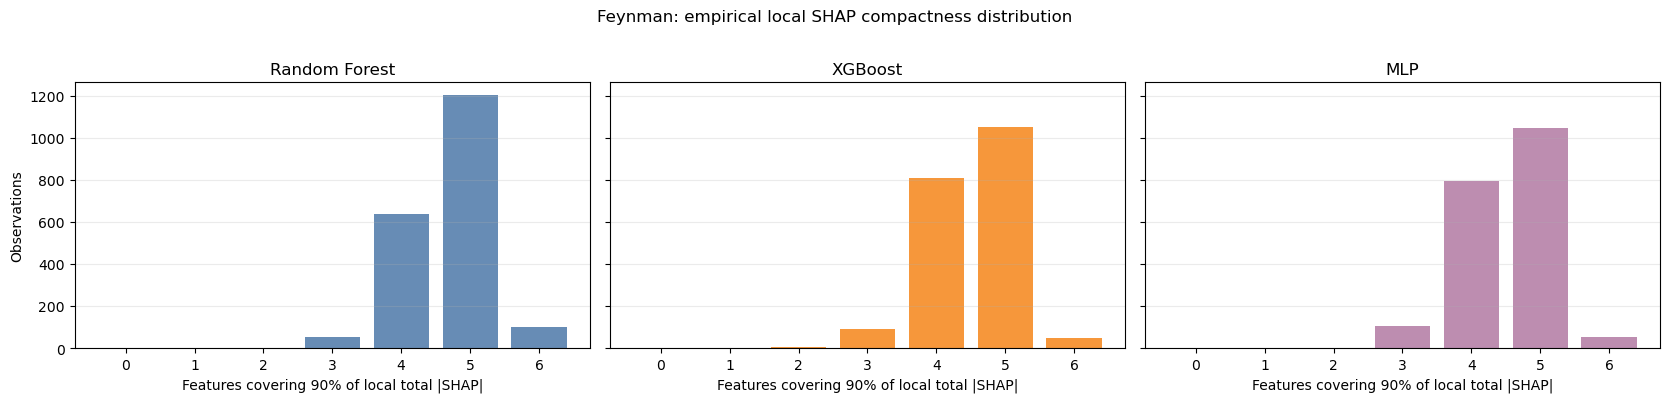

**Displayed native PySR equation**

`m2_m1 / ((square(y1_x1 - y2_x1) + square(z2_x1 - z1_x1)) + square(x2_x1 - square(1.0)))`

**Native PySR structural audit (separate units from SHAP feature counts)**

,Dataset,PySR recorded complexity,Audited expression-tree nodes,Distinct variables,Variables,Operator occurrences,Distinct operator types,Operators,Numeric constant leaves
0,Feynman,17,17,6,"m2_m1, y1_x1, y2_x1, z2_x1, z1_x1, x2_x1",10,4,"/, +, square, -",1


In [13]:
from scripts.explanation_metrics import feature_counts_for_shap_coverage, shap_compactness_tables
import ast

SHAP_COMPACTNESS_COVERAGES = (0.80, 0.90, 0.95)
SHAP_ZERO_TOTAL_TOLERANCE = np.finfo(float).eps






def plot_shap_compactness_distribution(shap_values_by_method, dataset, output_path):
    methods = list(shap_values_by_method)
    maximum_features = max(np.asarray(values).shape[1] for values in shap_values_by_method.values())
    fig, axes = plt.subplots(1, len(methods), figsize=(5.6 * len(methods), 3.9), sharey=True)
    axes = np.atleast_1d(axes)
    for axis, method in zip(axes, methods):
        counts = feature_counts_for_shap_coverage(shap_values_by_method[method], 0.90)
        frequencies = pd.Series(counts).value_counts().reindex(range(maximum_features + 1), fill_value=0)
        axis.bar(frequencies.index, frequencies.values, color=COLORS[method], alpha=0.85)
        axis.set_title(method)
        axis.set_xlabel("Features covering 90% of local total |SHAP|")
        tick_step = 1 if maximum_features <= 8 else 2
        axis.set_xticks(range(0, maximum_features + 1, tick_step))
        axis.grid(axis="y", alpha=0.25)
    axes[0].set_ylabel("Observations")
    fig.suptitle(f"{dataset}: empirical local SHAP compactness distribution", y=1.02)
    plt.tight_layout()
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()


def audit_displayed_expression(dataset, equation, valid_variables, recorded_complexity):
    variable_occurrences = []
    operator_occurrences = []
    numeric_constants = []
    binary_operator_names = {
        ast.Add: "+",
        ast.Sub: "-",
        ast.Mult: "*",
        ast.Div: "/",
        ast.Pow: "power",
    }

    def visit(node):
        if isinstance(node, ast.BinOp):
            if type(node.op) not in binary_operator_names:
                raise TypeError(f"Unsupported binary operator: {ast.dump(node.op)}")
            operator_occurrences.append(binary_operator_names[type(node.op)])
            visit(node.left)
            visit(node.right)
        elif isinstance(node, ast.Call) and isinstance(node.func, ast.Name):
            if node.func.id != "square" or len(node.args) != 1 or node.keywords:
                raise TypeError(f"Unsupported function call: {ast.dump(node)}")
            operator_occurrences.append("square")
            visit(node.args[0])
        elif isinstance(node, ast.Name):
            if node.id not in valid_variables:
                raise ValueError(f"Unexpected variable in displayed equation: {node.id}")
            variable_occurrences.append(node.id)
        elif isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
            numeric_constants.append(float(node.value))
        elif (
            isinstance(node, ast.UnaryOp)
            and isinstance(node.op, (ast.USub, ast.UAdd))
            and isinstance(node.operand, ast.Constant)
            and isinstance(node.operand.value, (int, float))
        ):
            sign = -1 if isinstance(node.op, ast.USub) else 1
            numeric_constants.append(sign * float(node.operand.value))
        else:
            raise TypeError(f"Unsupported expression node: {ast.dump(node)}")

    visit(ast.parse(equation, mode="eval").body)
    distinct_variables = list(dict.fromkeys(variable_occurrences))
    distinct_operators = list(dict.fromkeys(operator_occurrences))
    audited_nodes = len(variable_occurrences) + len(operator_occurrences) + len(numeric_constants)
    return pd.DataFrame(
        [
            {
                "Dataset": dataset,
                "PySR recorded complexity": int(recorded_complexity),
                "Audited expression-tree nodes": audited_nodes,
                "Distinct variables": len(distinct_variables),
                "Variables": ", ".join(distinct_variables),
                "Operator occurrences": len(operator_occurrences),
                "Distinct operator types": len(distinct_operators),
                "Operators": ", ".join(distinct_operators),
                "Numeric constant leaves": len(numeric_constants),
            }
        ]
    )


feynman_tree_compactness, feynman_tree_compactness_distribution = shap_compactness_tables(
    feynman_shap_values
)
feynman_tree_compactness.to_csv(
    COMPARISON_DIRS["feynman"] / "shap_compactness_summary.csv", index=False
)
feynman_tree_compactness_distribution.to_csv(
    COMPARISON_DIRS["feynman"] / "shap_compactness_distribution_90.csv", index=False
)
display(Markdown("**RF/XGBoost/MLP SHAP compactness summary and 80%/95% sensitivity**"))
display(
    feynman_tree_compactness.style.format(
        {
            "Mean features": "{:.2f}",
            "Median features": "{:.1f}",
            "Q1": "{:.1f}",
            "Q3": "{:.1f}",
            "IQR": "{:.1f}",
        }
    )
)
display(Markdown("**Empirical distribution at 90% attribution coverage**"))
display(
    feynman_tree_compactness_distribution.style.format(
        {"Percent of observations": "{:.1f}%"}
    )
)
plot_shap_compactness_distribution(
    feynman_shap_values,
    "Feynman",
    COMPARISON_DIRS["feynman"] / "shap_compactness_distribution_90.png",
)

display(Markdown(f"**Displayed native PySR equation**\n\n`{feynman_pysr['raw_equation']}`"))
feynman_symbolic_compactness = audit_displayed_expression(
    "Feynman",
    feynman_pysr["raw_equation"],
    set(feynman_features),
    feynman_pysr["complexity"],
)
assert (
    feynman_symbolic_compactness.loc[0, "Audited expression-tree nodes"]
    == feynman_symbolic_compactness.loc[0, "PySR recorded complexity"]
)
display(Markdown("**Native PySR structural audit (separate units from SHAP feature counts)**"))
display(feynman_symbolic_compactness)


### Feynman: interpretation

Validation-only selection across the 183 completed saved PySR configurations still recovers the generating equation. Nine planned configurations are absent and were not rerun. Fresh final performance is separate from the previously inspected test results. Generating-equation agreement and local fitted-model faithfulness answer different questions; neither is replaced by predictive accuracy.

On the 2,000 historical test observations, the 90%-absolute-SHAP count has mean 4.68, median 5 and IQR 1 feature for Random Forest, and mean 4.52, median 5 and IQR 1 for XGBoost. No observation has zero total attribution. Mean counts move from 3.81/3.68 at 80% coverage to 5.26/5.13 at 95% for RF/XGBoost, showing the expected threshold sensitivity. The displayed PySR equation uses six distinct variables and ten operator occurrences; its independently audited 17-node expression tree agrees with, but is reported separately from, PySR's recorded complexity of 17. These are representation-specific descriptions, not a compactness ranking between SHAP and PySR.

The following generated MLP summary supplements the retained RF/XGBoost/PySR interpretation. All conclusions remain specific to the evaluated model, representation and sampling design.


In [14]:
# Generated from validated MLP artefacts, never copied from tree-model conclusions.
mlp_performance = mlp_table("feynman", "metrics.csv").iloc[0]
mlp_compactness = mlp_table("feynman", "compactness.csv").query("`Attribution coverage` == '90%'").iloc[0]
display(Markdown(
    f"**MLP results.** R² = {mlp_performance.R2:.6f}, RMSE = {mlp_performance.RMSE:.6f}, "
    f"MAE = {mlp_performance.MAE:.6f}. At 90% attribution coverage, the mean local size is "
    f"{mlp_compactness['Mean features']:.2f} features (median {mlp_compactness['Median features']:.1f}, "
    f"IQR {mlp_compactness['IQR']:.1f}). These feature counts measure attribution coverage, not prediction recovery."
))
display(mlp_table("feynman", "local_correctness_summary.csv").round(4))
display(mlp_table("feynman", "completeness_summary.csv")[[
    "Method", "Median sustained reconstruction features", "Reconstruction tolerance",
    "Mean normalized preservation error at 90% SHAP", "Mean normalized deletion change at 90% SHAP"
]].round(4))
display(mlp_table("feynman", "continuity_summary.csv")[[
    "Method", "Noise (% training SD)", "Retained proportion", "Mean cosine similarity",
    "Mean absolute attribution distance"
]].round(6))


**MLP results.** R² = 0.999734, RMSE = 0.006354, MAE = 0.001915. At 90% attribution coverage, the mean local size is 4.52 features (median 5.0, IQR 1.0). These feature counts measure attribution coverage, not prediction recovery.

,Method,Metric,N,Defined N,Undefined N,Median,Q1,Q3,IQR
0,MLP,Spearman correlation,50,50,0,0.7714,0.5571,0.8286,0.2714
1,MLP,Top-three overlap,50,50,0,0.6667,0.6667,1.0000,0.3333


,Method,Median sustained reconstruction features,Reconstruction tolerance,Mean normalized preservation error at 90% SHAP,Mean normalized deletion change at 90% SHAP
0,MLP,6.0,0.0198,0.3104,0.953


,Method,Noise (% training SD),Retained proportion,Mean cosine similarity,Mean absolute attribution distance
0,MLP,2.5,0.917,0.999361,0.003186
1,MLP,5.0,0.626,0.998018,0.005808


## Body-fat dataset

### Body fat: data and models

These are downloaded HPC results, not mock models. The principal explanation space contains 13 raw measurements. `ACratio` and `HTratio` are derived inputs recomputed inside the prediction wrapper from abdomen/chest and hip/thigh respectively; they are not treated as two additional independent explanation features.

The symbolic expression below is the PySR equation selected by validation RMSE, not by test performance.

In [15]:
with project_path("hpc_results/bodyfat/pysr_20260719_232448/pysr_manifest.json").open(
    encoding="utf-8"
) as handle:
    bodyfat_pysr_manifest = json.load(handle)

bodyfat_raw_features = bodyfat_manifest["explanation_columns"]
bodyfat_pysr = bodyfat_pysr_manifest["representative_equations"]["best_validation_rmse"]
display(
    pd.DataFrame(
        {
            "Artifact status": [bodyfat_manifest["artifact_status"]],
            "Raw explanation features": [len(bodyfat_raw_features)],
            "Validation-selected PySR equation": [bodyfat_pysr["equation"]],
            "Complexity": [bodyfat_pysr["complexity"]],
            "Variables used": [bodyfat_pysr["n_variables_used"]],
        },
        index=["Body fat"],
    )
)
display(pd.DataFrame({"Raw explanation feature": bodyfat_raw_features}))

,Artifact status,Raw explanation features,Validation-selected PySR equation,Complexity,Variables used
Body fat,analysis_from_downloaded_hpc_results,13,((-272.58493 * Wrist) + square(Abdomen)) / (Weight + (Neck - Biceps)),12,5


,Raw explanation feature
0,Age
1,Weight
2,Height
3,Neck
4,Chest
5,Abdomen
6,Hip
7,Thigh
8,Knee
9,Ankle


### Body fat: predictive performance

The saved test metrics cover 51 subjects. R², RMSE and MAE are shown in separate panels so their scales are not conflated. These results contextualise the explanations but are not themselves a Co-12 explanation-quality property.

,Method,R2,RMSE,MAE,MSE
0,Random Forest,0.633,4.130,3.440,nan
1,XGBoost,0.635,4.121,3.517,nan
2,PySR,0.676,3.883,3.256,nan
3,MLP,0.700,3.737,3.110,13.964408


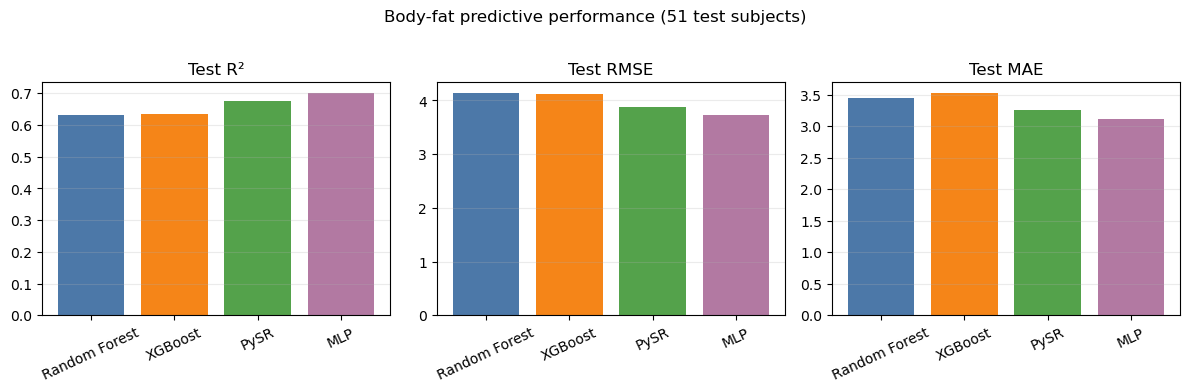

In [16]:
bodyfat_performance = pd.read_csv(project_path("outputs/bodyfat/analysis/clean_performance.csv"))
bodyfat_performance = include_mlp(bodyfat_performance, "bodyfat", "metrics.csv")

display(
    bodyfat_performance.style.format(
        {"R2": "{:.3f}", "RMSE": "{:.3f}", "MAE": "{:.3f}"}
    )
)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, metric, label in zip(
    axes,
    ["R2", "RMSE", "MAE"],
    ["Test R²", "Test RMSE", "Test MAE"],
):
    ax.bar(
        bodyfat_performance["Method"],
        bodyfat_performance[metric],
        color=[COLORS[name] for name in bodyfat_performance["Method"]],
    )
    ax.set_title(label)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Body-fat predictive performance (51 test subjects)", y=1.02)
plt.tight_layout()
plt.show()

**Prediction wrapper and native PySR rule audit**

Load the existing fitted trees and MLP pipeline and reconstruct the original raw-feature wrapper. Check feature order, training/test disjointness, prepared inputs and saved predictions before explanation calculations. The native PySR rule uses the exact displayed constants, original units and direct body-fat-percentage output. No PySR SHAP score is used.
For MLP, the 13-raw-input wrapper recomputes both ratios, then the saved pipeline scales the 15 inputs and inverse-transforms the target. No scaling is refitted, and Density remains excluded.


In [17]:
# Reuse the existing raw-feature wrapper and saved HPC estimators; never refit.
import hashlib
import itertools
import warnings
import sklearn
import xgboost
from scipy.stats import rankdata

BODYFAT_AUDIT_DIR = project_path("outputs/bodyfat/analysis/reliability_audit")
BODYFAT_AUDIT_DIR.mkdir(parents=True, exist_ok=True)
RERUN_BODYFAT_SHAP = False
RERUN_BODYFAT_DELETION = False
EXPLANATION_COLUMNS = bodyfat_raw_features
FEATURE_COLUMNS = bodyfat_manifest["feature_columns"]
bodyfat_train_rows = pd.read_csv(project_path("hpc_results/bodyfat/prepared/train_raw_split.csv"))
bodyfat_test_rows = pd.read_csv(project_path("hpc_results/bodyfat/prepared/test_raw_split.csv"))
bodyfat_X_train_raw = bodyfat_train_rows[EXPLANATION_COLUMNS].astype(float)
bodyfat_X_test_raw = bodyfat_test_rows[EXPLANATION_COLUMNS].astype(float)
bodyfat_subject_ids = bodyfat_test_rows["source_row_index"].to_numpy()
assert len(EXPLANATION_COLUMNS) == 13
assert not set(bodyfat_subject_ids) & set(bodyfat_train_rows["source_row_index"])

def prepared_feature_frame(raw_rows):
    raw = pd.DataFrame(raw_rows, columns=EXPLANATION_COLUMNS).copy()
    if not np.isfinite(raw.to_numpy(dtype=float)).all():
        raise ValueError("Raw body-fat rows contain non-finite values.")
    if (raw[["Chest", "Thigh"]] == 0).any().any():
        raise ValueError("Chest and Thigh must be non-zero to derive ratios.")
    prepared = raw.copy()
    prepared["ACratio"] = prepared["Abdomen"] / prepared["Chest"]
    prepared["HTratio"] = prepared["Hip"] / prepared["Thigh"]
    return prepared[FEATURE_COLUMNS]

def model_prediction_function(model):
    def predict(rows):
        return np.asarray(model.predict(prepared_feature_frame(rows)), dtype=float).ravel()
    return predict

bodyfat_tree_models = {
    "Random Forest": joblib.load(project_path("hpc_results/bodyfat/random_forest_20260719_232404/rf_best.joblib")),
    "XGBoost": joblib.load(project_path("hpc_results/bodyfat/xgboost_20260719_232404/xgb_best.joblib")),
}
for model in bodyfat_tree_models.values():
    model.set_params(n_jobs=1)  # inference scheduling only
bodyfat_tree_predict = {name: model_prediction_function(model) for name, model in bodyfat_tree_models.items()}
bodyfat_background = bodyfat_X_train_raw.sample(n=50, random_state=42)
bodyfat_background_ids = bodyfat_train_rows.loc[bodyfat_background.index, "source_row_index"].to_numpy()

# Finite complete measurements here mean the saved training-median imputation is
# an identity. Ratios precede imputation in the preparation script; no scaling
# or output transformation is applied. Do not silently change missing-data rules.
assert np.isfinite(bodyfat_X_train_raw.to_numpy()).all()
prepared_test = pd.read_csv(project_path("hpc_results/bodyfat/prepared/X_test.csv"), index_col=0)
np.testing.assert_array_equal(prepared_test.index, bodyfat_subject_ids)
np.testing.assert_allclose(prepared_feature_frame(bodyfat_X_test_raw), prepared_test, atol=1e-12, rtol=1e-12)
prediction_checks = []
for name, prefix, folder in [
    ("Random Forest", "rf", "random_forest_20260719_232404"),
    ("XGBoost", "xgb", "xgboost_20260719_232404"),
]:
    saved = pd.read_csv(project_path(f"hpc_results/bodyfat/{folder}/{prefix}_test_predictions.csv"))
    np.testing.assert_array_equal(saved.source_row_index, bodyfat_subject_ids)
    actual = bodyfat_tree_predict[name](bodyfat_X_test_raw)
    expected = saved[f"{prefix}_predicted_bodyfat"].to_numpy()
    np.testing.assert_allclose(actual, expected, rtol=1e-6, atol=1e-6)
    prediction_checks.append({"Method": name, "Maximum saved-prediction difference": float(np.max(np.abs(actual-expected)))})
display(pd.DataFrame(prediction_checks))

bodyfat_models = {**bodyfat_tree_models, "MLP": mlp_audits["bodyfat"].model}
bodyfat_predict = {**bodyfat_tree_predict, "MLP": model_prediction_function(bodyfat_models["MLP"])}
np.testing.assert_array_equal(mlp_audits["bodyfat"].test.index, bodyfat_subject_ids)
np.testing.assert_allclose(bodyfat_predict["MLP"](bodyfat_X_test_raw),
                           mlp_audits["bodyfat"].predict(mlp_audits["bodyfat"].test), atol=1e-12, rtol=1e-12)
display(pd.DataFrame([{"Method": "MLP", "Maximum saved-prediction difference": mlp_audits["bodyfat"].prediction_max_error}]))


C:\Users\jarra\miniconda3\envs\xai-compare\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.9.0 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\jarra\miniconda3\envs\xai-compare\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from version 1.9.0 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


,Method,Maximum saved-prediction difference
0,Random Forest,7.105427e-15
1,XGBoost,5.505371e-07


,Method,Maximum saved-prediction difference
0,MLP,7.105427e-15


In [18]:
bodyfat_native_equation = bodyfat_pysr["equation"]
bodyfat_namespace = {f: sp.Symbol(f) for f in FEATURE_COLUMNS}
bodyfat_namespace["square"] = lambda x:x**2
bodyfat_native_expr = sp.sympify(bodyfat_native_equation, locals=bodyfat_namespace)
bodyfat_native_fn = sp.lambdify([bodyfat_namespace[f] for f in FEATURE_COLUMNS], bodyfat_native_expr, "numpy")
bodyfat_native_prepared = prepared_feature_frame(bodyfat_X_test_raw)
bodyfat_native_pred = bodyfat_native_fn(*[bodyfat_native_prepared[f].to_numpy() for f in FEATURE_COLUMNS])
bodyfat_native_saved = pd.read_csv(project_path("hpc_results/bodyfat/pysr_20260719_232448/pysr_test_predictions.csv"))
np.testing.assert_array_equal(bodyfat_native_saved.source_row_index, bodyfat_subject_ids)
expected = bodyfat_native_saved["pysr_best_validation_rmse_predicted_bodyfat"].to_numpy()
# Compare the actual printed constants at a strict numerical tolerance.
native_difference = np.abs(bodyfat_native_pred-expected)
np.testing.assert_allclose(bodyfat_native_pred, expected, rtol=0, atol=1e-12)
native_check_rows.append({"Dataset":"Body fat", "Rows":"Historical test", "N":len(expected),
                          "Maximum prediction difference":native_difference.max()})
native_audit = pd.DataFrame(native_check_rows)
native_audit.to_csv(BODYFAT_AUDIT_DIR / "native_equation_audit.csv", index=False)
display(Markdown("**Native prediction rule (body-fat percentage points)**"))
display(bodyfat_native_expr)
display(native_audit)
print("No feature scaling or output transform. Training-median imputation is inactive for these complete rows.")
print("ACratio = Abdomen/Chest and HTratio = Hip/Thigh are recomputed; selected equation does not use them.")
print("Printed-constant maximum discrepancy:", native_difference.max(), "percentage points; tolerance 1e-12.")

# Confirm the body-fat selection itself remains validation-only across saved candidates.
bodyfat_candidates = pd.read_csv(project_path("hpc_results/bodyfat/pysr_20260719_232448/pysr_equation_metrics.csv"))
selected_by_validation = bodyfat_candidates.sort_values(["validation_RMSE", "complexity"], kind="stable").iloc[0]
assert selected_by_validation["label"] == bodyfat_pysr["label"]
assert int(selected_by_validation["equation_index"]) == int(bodyfat_pysr["equation_index"])


**Native prediction rule (body-fat percentage points)**

(Abdomen**2 - 272.58493*Wrist)/(-Biceps + Neck + Weight)

,Dataset,Rows,N,Maximum prediction difference
0,Feynman,Historical test,2000,4.440892e-16
1,Feynman,Fresh final,2000,1.332268e-15
2,Body fat,Historical test,51,3.552714e-15


No feature scaling or output transform. Training-median imputation is inactive for these complete rows.
ACratio = Abdomen/Chest and HTratio = Hip/Thigh are recomputed; selected equation does not use them.
Printed-constant maximum discrepancy: 3.552713678800501e-15 percentage points; tolerance 1e-12.


**Body-fat SHAP reliability**

The inspected producer (`BodyFat_Mock_Models_Analysis.ipynb`, original zero-based cell 13) still used `max_evals = 2 * 13 + 1 = 27`. This is one forward/reverse cycle; [SHAP's permutation documentation](https://shap.readthedocs.io/en/stable/generated/shap.PermutationExplainer.html) makes clear that additivity alone is not evidence of convergence. No earlier convergence artefact was found.

Keep the original background: 50 rows sampled without replacement from the training split with pandas `random_state=42`. The wrapper retains 13 raw features and recomputes both ratios. Calibration covers 12 subjects spanning pooled model predictions plus the largest standardized raw-feature outlier, using cycles 1, 4, 16, 64 and 256 and seeds 42, 1729 and 2026. Each calculation constructs a fresh explainer. Compare attribution values, local ranks, top-three membership and 90%-SHAP counts across independent seeds and against full exact enumeration of all 8,192 feature coalitions using the same wrapper and background.

Criteria are recorded before the run: normalized attribution L1 p90 ≤ 0.10; rank rho median ≥ 0.98 and p10 ≥ 0.95; mean top-three overlap ≥ 0.95; exact 90%-count agreement ≥ 0.90 and all counts within one feature, for both models and both comparison types. Record the smallest passing permutation budget, if any. **Protocol extension:** borderline 90% counts at 16 and 64 cycles motivated an exact reference; the original criteria were not relaxed. Because exact enumeration is practical in 13 dimensions, the final budget is **8,192 coalitions per subject** (at most 409,600 background-expanded rows), with no permutation Monte Carlo error. Independently compute the full test set twice (seeds 314159 and 271828, which exact enumeration does not consume). Retain the first exact calculation for reporting and use the second to check implementation consistency. Individual arrays, base values, feature order, subject/background identifiers and settings are saved. Independent identical-input variability is reported rather than inferred from a reused zero-noise array. This calibrates Monte Carlo variability for one fixed background, not uncertainty over background choice.
**MLP extension:** exact enumeration is used directly on the identical 50 background rows. A second independent exact calculation checks the fixed 12 continuity subjects. The masker skips strictly equal cells only; near-equal measurements are evaluated, preserving tight numerical additivity for the smooth MLP. The historical tree permutation-budget selection is not presented as an MLP calibration result.


In [19]:
def bodyfat_explain(rows, method, cycles, seed):
    # A fresh explainer for EVERY calculation, including identical input rows.
    explainer = shap.Explainer(
        bodyfat_tree_predict[method],
        shap.maskers.Independent(bodyfat_background, max_samples=50),
        algorithm="permutation", feature_names=EXPLANATION_COLUMNS, seed=int(seed),
    )
    result = explainer(rows, max_evals=int(cycles)*(2*len(EXPLANATION_COLUMNS)+1),
                       batch_size=2000, silent=True)
    pred = bodyfat_tree_predict[method](rows)
    np.testing.assert_allclose(result.values.sum(axis=1)+result.base_values, pred, atol=1e-6, rtol=1e-6)
    return result


def bodyfat_exact_explain(rows, method):
    explainer = shap.Explainer(
        bodyfat_tree_predict[method], shap.maskers.Independent(bodyfat_background, max_samples=50),
        algorithm="exact", feature_names=EXPLANATION_COLUMNS,
    )
    result = explainer(rows, max_evals=2**len(EXPLANATION_COLUMNS), batch_size=32768, silent=True)
    np.testing.assert_allclose(result.values.sum(1)+result.base_values, bodyfat_tree_predict[method](rows), atol=1e-10, rtol=1e-10)
    return result

def attribution_differences(a, b, ids):
    ca, cb = feature_counts_for_shap_coverage(a), feature_counts_for_shap_coverage(b)
    rows = []
    for i, subject in enumerate(ids):
        rec = local_agreement(np.abs(a[i]), np.abs(b[i]))
        rec.update({"source_row_index": int(subject),
                    "Normalized L1 difference": float(np.abs(a[i]-b[i]).sum()/max(np.abs(b[i]).sum(), 1e-12)),
                    "Attribution MAE": float(np.abs(a[i]-b[i]).mean()),
                    "Maximum attribution difference": float(np.abs(a[i]-b[i]).max()),
                    "90% count difference": int(abs(ca[i]-cb[i]))})
        rows.append(rec)
    return rows

if RERUN_BODYFAT_SHAP:
    cache_sources = ["hpc_results/bodyfat/prepared/train_raw_split.csv",
                     "hpc_results/bodyfat/prepared/test_raw_split.csv",
                     "hpc_results/bodyfat/random_forest_20260719_232404/rf_best.joblib",
                     "hpc_results/bodyfat/xgboost_20260719_232404/xgb_best.joblib"]
    cache_identity = {p: hashlib.sha256(project_path(p).read_bytes()).hexdigest() for p in cache_sources}
    cache_identity["feature_order"] = EXPLANATION_COLUMNS
    cache_identity["background_ids"] = bodyfat_background_ids.tolist()
    cache_identity["wrapper"] = "13 raw features; ACratio=Abdomen/Chest; HTratio=Hip/Thigh; identity output"
    cache_path = BODYFAT_AUDIT_DIR / "cache_inputs.json"
    if cache_path.exists() and json.loads(cache_path.read_text()) != cache_identity:
        raise RuntimeError("Cached explanations use different inputs or models. Preserve the old audit and choose a new audit directory.")
    cache_path.write_text(json.dumps(cache_identity, indent=2), encoding="utf-8")
    # Fixed before inspecting convergence: cover the fitted response range with
    # 12 evenly spaced subjects, plus the largest standardized raw-feature outlier.
    mean_pred = np.mean([f(bodyfat_X_test_raw) for f in bodyfat_tree_predict.values()], axis=0)
    order = np.argsort(mean_pred, kind="stable")
    positions = order[np.linspace(0, len(order)-1, 12).round().astype(int)]
    z = (bodyfat_X_test_raw-bodyfat_X_train_raw.mean())/bodyfat_X_train_raw.std(ddof=0)
    positions = np.unique(np.r_[positions, np.argmax(np.linalg.norm(z, axis=1))])
    subset = bodyfat_X_test_raw.iloc[positions]
    ids = bodyfat_subject_ids[positions]
    seeds = [42, 1729, 2026]
    budgets = [1, 4, 16, 64, 256]
    arrays, comparison_rows = {}, []
    # Cache complete calculations, so interrupted calibration can resume.
    for cycles in budgets:
        for method in bodyfat_tree_models:
            key = method.lower().replace(" ", "_")
            for seed in seeds:
                path = BODYFAT_AUDIT_DIR / f"calibration_{key}_{cycles}_{seed}.npz"
                if not path.exists():
                    e = bodyfat_explain(subset, method, cycles, seed)
                    np.savez_compressed(path, values=e.values, base_values=e.base_values,
                                        source_row_index=ids, feature_names=EXPLANATION_COLUMNS)
                with np.load(path) as a:
                    np.testing.assert_array_equal(a["source_row_index"], ids)
                    arrays[method, cycles, seed] = a["values"].copy()
            print(f"Calibration completed: {method}, {cycles} cycles", flush=True)
    for method in bodyfat_tree_models:
        for cycles in budgets:
            for sa, sb in itertools.combinations(seeds, 2):
                for row in attribution_differences(arrays[method, cycles, sa], arrays[method, cycles, sb], ids):
                    comparison_rows.append({"Method": method, "Cycles": cycles, "Comparison": "independent seeds",
                                            "Seed A": sa, "Seed B": sb, **row})

            reference_path = BODYFAT_AUDIT_DIR / f"exact_reference_{method.lower().replace(' ', '_')}.npz"
            if not reference_path.exists():
                e = bodyfat_exact_explain(subset, method)
                np.savez_compressed(reference_path, values=e.values, base_values=e.base_values, source_row_index=ids)
            with np.load(reference_path) as a:
                np.testing.assert_array_equal(a["source_row_index"], ids)
                reference = a["values"].copy()
            for seed in seeds:
                for row in attribution_differences(arrays[method, cycles, seed], reference, ids):
                    comparison_rows.append({"Method": method, "Cycles": cycles, "Comparison": "exact coalition reference",
                                            "Seed A": seed, "Seed B": -1, **row})
    calibration = pd.DataFrame(comparison_rows)
    calibration.to_csv(BODYFAT_AUDIT_DIR / "shap_convergence_rows.csv", index=False)
    summaries = []
    for (method, cycles, comparison), g in calibration.groupby(["Method", "Cycles", "Comparison"], sort=False):
        summaries.append({"Method": method, "Cycles": cycles, "max_evals": cycles*27, "Comparison": comparison,
                          "L1 p90": g["Normalized L1 difference"].quantile(.9),
                          "Attribution MAE median": g["Attribution MAE"].median(),
                          "Rank rho median": g["Spearman correlation"].median(),
                          "Rank rho p10": g["Spearman correlation"].quantile(.1),
                          "Mean top-three overlap": g["Top-three overlap"].mean(),
                          "90% count exact agreement": (g["90% count difference"] == 0).mean(),
                          "90% count within one": (g["90% count difference"] <= 1).mean()})
    convergence = pd.DataFrame(summaries)
    convergence["Pass"] = ((convergence["L1 p90"] <= .10)
        & (convergence["Rank rho median"] >= .98) & (convergence["Rank rho p10"] >= .95)
        & (convergence["Mean top-three overlap"] >= .95)
        & (convergence["90% count exact agreement"] >= .90)
        & (convergence["90% count within one"] == 1))
    convergence.to_csv(BODYFAT_AUDIT_DIR / "shap_convergence_summary.csv", index=False)

    # At only 13 features, full coalition enumeration is feasible. It eliminates
    # the finite-permutation ambiguity at the discontinuous 90% cutoff without
    # weakening the original pass criteria. Same empirical SHAP estimand/background.
    eligible = [int(b) for b in budgets if convergence.loc[convergence.Cycles==b, "Pass"].all()]
    selected_cycles = min(eligible) if eligible else None
    final_seeds = [314159, 271828]
    final_arrays, repeat_rows = {}, []
    for method in bodyfat_tree_models:
        key = method.lower().replace(" ", "_")
        calculations = []
        for seed in final_seeds:
            # Seeds are deliberately set independently but unused by ExactSHAP.
            # Recompute identical inputs, never reuse the reference array.
            np.random.seed(seed)
            path = BODYFAT_AUDIT_DIR / f"clean_exact_{key}_{seed}.npz"
            if not path.exists():
                values, bases = [], []
                for i in range(len(bodyfat_X_test_raw)):
                    e = bodyfat_exact_explain(bodyfat_X_test_raw.iloc[[i]], method)
                    values.append(e.values); bases.append(e.base_values)
                    if i % 10 == 0:
                        print(f"Exact full-test SHAP: {method}, seed {seed}, row {i+1}/51", flush=True)
                np.savez_compressed(path, values=np.concatenate(values), base_values=np.concatenate(bases),
                                    source_row_index=bodyfat_subject_ids, feature_names=EXPLANATION_COLUMNS)
            with np.load(path) as a:
                np.testing.assert_array_equal(a["source_row_index"], bodyfat_subject_ids)
                calculations.append(a["values"].copy())
                base = a["base_values"].copy()
        final_arrays[key] = calculations[0]
        final_arrays[key+"_replicates"] = np.stack(calculations)
        final_arrays[key+"_base_values"] = base
        final_arrays[key+"_prediction"] = bodyfat_tree_predict[method](bodyfat_X_test_raw)
        np.testing.assert_allclose(final_arrays[key].sum(1)+base, final_arrays[key+"_prediction"], atol=1e-10, rtol=1e-10)
        for row in attribution_differences(calculations[0], calculations[1], bodyfat_subject_ids):
            repeat_rows.append({"Method":method,"Seed A":final_seeds[0],"Seed B":final_seeds[1], **row})
    final_arrays.update(feature_names=np.array(EXPLANATION_COLUMNS), source_row_index=bodyfat_subject_ids,
                        background_source_row_index=bodyfat_background_ids, background_values=bodyfat_background.to_numpy(),
                        seeds=final_seeds, max_evals=8192, algorithm="exact")
    np.savez_compressed(BODYFAT_AUDIT_DIR / "shap_values.npz", **final_arrays)
    pd.DataFrame(repeat_rows).to_csv(BODYFAT_AUDIT_DIR / "shap_identical_input_repeats.csv", index=False)
    sources = ["BodyFat_Mock_Models_Analysis.ipynb", "outputs/bodyfat/analysis/shap_values.npz",
               "hpc_results/bodyfat/prepared/train_raw_split.csv", "hpc_results/bodyfat/prepared/test_raw_split.csv",
               "hpc_results/bodyfat/random_forest_20260719_232404/rf_best.joblib",
               "hpc_results/bodyfat/xgboost_20260719_232404/xgb_best.joblib"]
    manifest = {"status":"completed", "legacy_max_evals":27,
        "legacy_source_cell":"BodyFat_Mock_Models_Analysis.ipynb, original cell 13 (zero-based)",
        "legacy_artifact":"../shap_values.npz", "feature_order":EXPLANATION_COLUMNS,
        "subject_ids":bodyfat_subject_ids.tolist(), "background_ids":bodyfat_background_ids.tolist(),
        "background":"50 training rows sampled without replacement, pandas sample random_state=42; unchanged from original",
        "subset_ids":ids.tolist(), "subset_rule":"12 evenly spaced pooled prediction ranks plus largest standardized raw-feature outlier",
        "calibration_cycles":budgets,"calibration_seeds":seeds,
        "smallest_passing_permutation_cycles":selected_cycles,
        "selected_algorithm":"exact", "max_evals_per_seed":8192,"final_seeds":final_seeds,
        "seed_effect":"Exact enumeration does not consume random permutations; independent repetitions are an implementation consistency check",
        "reported_estimate":"First full exact enumeration over all 8192 coalitions and the same 50-row empirical background; second independent calculation verifies consistency",
        "criterion":"Permutation checks: both models and both independent-seed/exact-reference comparisons: L1 p90<=0.10; rho median>=0.98, p10>=0.95; mean top3>=0.95; count exact>=0.90, within1=1",
        "protocol_extension":"After borderline 90% counts at 16 and 64 cycles, added exact coalition enumeration as a deterministic reference and final budget; original criteria were not relaxed",
        "uncertainty_scope":"No permutation Monte Carlo error in final arrays; fixed-background dependence and floating-point error remain; no population uncertainty assessed",
        "link":"identity","batch_size":32768,"ratios":{"ACratio":"Abdomen / Chest","HTratio":"Hip / Thigh"},
        "versions":{"numpy":np.__version__,"shap":shap.__version__,"sklearn":sklearn.__version__,"xgboost":xgboost.__version__},
        "source_sha256":{p:hashlib.sha256(project_path(p).read_bytes()).hexdigest() for p in sources}}
    (BODYFAT_AUDIT_DIR / "shap_manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")

with (BODYFAT_AUDIT_DIR / "shap_manifest.json").open() as f:
    bodyfat_shap_audit = json.load(f)
bodyfat_convergence = pd.read_csv(BODYFAT_AUDIT_DIR / "shap_convergence_summary.csv")
bodyfat_identical_repeats = pd.read_csv(BODYFAT_AUDIT_DIR / "shap_identical_input_repeats.csv")
with np.load(BODYFAT_AUDIT_DIR / "shap_values.npz") as a:
    np.testing.assert_array_equal(a["feature_names"], EXPLANATION_COLUMNS)
    np.testing.assert_array_equal(a["source_row_index"], bodyfat_subject_ids)
    np.testing.assert_array_equal(a["background_source_row_index"], bodyfat_background_ids)
    np.testing.assert_allclose(a["background_values"], bodyfat_background.to_numpy(), atol=0, rtol=0)
    bodyfat_saved_shap = {m: a[m.lower().replace(" ", "_")].copy() for m in bodyfat_tree_models}
    for m, v in bodyfat_saved_shap.items():
        key = m.lower().replace(" ", "_")
        np.testing.assert_allclose(v.sum(1)+a[key+"_base_values"], bodyfat_tree_predict[m](bodyfat_X_test_raw), atol=1e-10, rtol=1e-10)
bodyfat_saved_shap["MLP"] = mlp_shap("bodyfat")
bodyfat_identical_repeats = include_mlp(bodyfat_identical_repeats, "bodyfat", "shap_identical_input_repeats.csv")
display(Markdown("The permutation calibration below is the historical tree audit. MLP uses exact enumeration directly; its independent-repeat check is included below."))
display(bodyfat_convergence.round(4))
display(agreement_summary(bodyfat_identical_repeats[bodyfat_identical_repeats.Method.isin(TREE_METHODS)]).round(4))
display(bodyfat_identical_repeats.groupby("Method")[["Normalized L1 difference", "Attribution MAE", "90% count difference"]].agg(["median", "max"]).round(4))
print("Final exact SHAP budget:", bodyfat_shap_audit["max_evals_per_seed"], "coalitions. RF/XGBoost full test arrays repeated twice; MLP independently repeated on the 12 continuity subjects.")


The permutation calibration below is the historical tree audit. MLP uses exact enumeration directly; its independent-repeat check is included below.

,Method,Cycles,max_evals,Comparison,L1 p90,Attribution MAE median,Rank rho median,Rank rho p10,Mean top-three overlap,90% count exact agreement,90% count within one,Pass
0,Random Forest,1,27,independent seeds,0.1709,0.0468,0.9203,0.8462,0.9259,0.5278,0.9722,False
1,Random Forest,1,27,exact coalition reference,0.1363,0.0368,0.9560,0.8352,0.9259,0.7500,1.0000,False
2,Random Forest,4,108,independent seeds,0.0734,0.0218,0.9780,0.9038,1.0000,0.7778,1.0000,False
3,Random Forest,4,108,exact coalition reference,0.0558,0.0150,0.9835,0.9368,1.0000,0.8611,1.0000,False
4,Random Forest,16,432,independent seeds,0.0382,0.0105,0.9945,0.9780,0.9815,0.8333,1.0000,False
5,Random Forest,16,432,exact coalition reference,0.0242,0.0080,0.9945,0.9725,0.9815,0.8889,1.0000,False
6,Random Forest,64,1728,independent seeds,0.0176,0.0058,0.9945,0.9890,0.9815,0.8333,1.0000,False
7,Random Forest,64,1728,exact coalition reference,0.0162,0.0039,0.9945,0.9890,0.9907,0.9167,1.0000,True
8,Random Forest,256,6912,independent seeds,0.0101,0.0029,1.0000,0.9890,0.9815,0.9444,1.0000,True
9,Random Forest,256,6912,exact coalition reference,0.0071,0.0020,1.0000,0.9945,0.9907,0.9722,1.0000,True


,Method,Metric,N,Defined N,Undefined N,Median,Q1,Q3,IQR
0,Random Forest,Spearman correlation,51,51,0,1.0,1.0,1.0,0.0
1,Random Forest,Top-three overlap,51,51,0,1.0,1.0,1.0,0.0
2,XGBoost,Spearman correlation,51,51,0,1.0,1.0,1.0,0.0
3,XGBoost,Top-three overlap,51,51,0,1.0,1.0,1.0,0.0


Normalized L1 difference      Attribution MAE       \
                                median  max          median  max   
Method                                                             
MLP                                0.0  0.0             0.0  0.0   
Random Forest                      0.0  0.0             0.0  0.0   
XGBoost                            0.0  0.0             0.0  0.0   

              90% count difference      
                            median max  
Method                                  
MLP                            0.0   0  
Random Forest                  0.0   0  
XGBoost                        0.0   0

Final exact SHAP budget: 8192 coalitions. RF/XGBoost full test arrays repeated twice; MLP independently repeated on the 12 continuity subjects.


### Body fat: supplementary native feature importance versus SHAP

The native RF and XGBoost importances refer to **15 fitted model inputs**: 13 raw measurements plus `ACratio = Abdomen / Chest` and `HTratio = Hip / Thigh`. In contrast, the existing exact-SHAP audit above explains the **13-input prediction wrapper**, which recomputes both ratios whenever raw measurements change. Those vectors answer a different question and cannot be directly matched to 15 native importances; dropping the ratios or arbitrarily assigning their importance to raw measurements would not resolve this difference.

For this supplementary comparison only, compute **TreeSHAP directly on the 15-input fitted estimators**, using all 51 prepared test rows in their verified model-input order. `feature_perturbation="tree_path_dependent"` explicitly uses the fitted trees' path counts, with `model_output="raw"` (body-fat percentage points for these regressors). No separate background sample is supplied. Additivity is checked against the fitted predictions before averaging absolute attributions. The models remain frozen, and the existing 13-feature exact-SHAP arrays, wrappers and audits are not replaced or rerun.

The tables and charts use the same MDI/gain definitions, normalisation, average-rank Spearman correlation and tie-aware top-three overlap described in the Feynman supplementary section. A positive rank difference again means lower importance under SHAP. Raw mean absolute SHAP is in body-fat percentage points, while the chart displays separately normalised shares. These are descriptive summaries over 15 features and 51 test subjects; no population significance claim is made.

**Scope:** this compares importance in the engineered model-input representation. The ratio inputs are deterministically related to raw measurements, and this direct TreeSHAP setup does not enforce the raw-wrapper relationships when attributing contributions. It therefore does not provide the same raw-measurement interpretation or background convention as the existing exact-SHAP analysis. Correlated and derived inputs can share or redistribute importance differently under native split importance and SHAP. Agreement is consistency between global importance summaries, not evidence of causality or correctness.

**MLP is intentionally excluded** from this native-importance comparison. Its primary explanations remain in the 13-raw-measurement space.


,Dataset,Method,Native definition,Evaluation rows,Features,Spearman correlation,Top-three overlap,Third-place boundary tie,Zero native total,Zero SHAP total
0,Body fat (15 model inputs),Random Forest,MDI,51,15,0.821,1.000,False,False,False
1,Body fat (15 model inputs),XGBoost,Gain,51,15,0.629,0.667,False,False,False


**Body fat (15 model inputs) — Random Forest: feature rankings**

,Feature,Native importance (normalised),Mean absolute SHAP,SHAP share,Native rank,SHAP rank,SHAP rank minus native rank
0,Abdomen,0.4307,2.985643,0.3958,1.0,1.0,+0.0
1,ACratio,0.1835,1.709363,0.2266,2.0,2.0,+0.0
2,Chest,0.1109,0.574893,0.0762,3.0,3.0,+0.0
3,Height,0.0322,0.377291,0.0500,6.0,4.0,-2.0
4,Age,0.0249,0.306086,0.0406,7.0,5.0,-2.0
5,Wrist,0.0150,0.289247,0.0383,12.0,6.0,-6.0
6,Biceps,0.0232,0.259485,0.0344,8.0,7.0,-1.0
7,Weight,0.0463,0.256140,0.0340,4.0,8.0,+4.0
8,Hip,0.0383,0.149370,0.0198,5.0,9.0,+4.0
9,Ankle,0.0171,0.143104,0.0190,11.0,10.0,-1.0


**Body fat (15 model inputs) — XGBoost: feature rankings**

,Feature,Native importance (normalised),Mean absolute SHAP,SHAP share,Native rank,SHAP rank,SHAP rank minus native rank
0,Abdomen,0.2736,2.987996,0.3189,1.0,1.0,+0.0
1,ACratio,0.1519,1.943778,0.2075,3.0,2.0,-1.0
2,Wrist,0.0333,0.807012,0.0861,8.0,3.0,-5.0
3,Age,0.0351,0.776475,0.0829,7.0,4.0,-3.0
4,Biceps,0.0352,0.635956,0.0679,6.0,5.0,-1.0
5,Chest,0.1075,0.538374,0.0575,4.0,6.0,+2.0
6,Height,0.0508,0.531182,0.0567,5.0,7.0,+2.0
7,Neck,0.0154,0.262596,0.0280,14.0,8.0,-6.0
8,Knee,0.0264,0.237780,0.0254,10.0,9.0,-1.0
9,HTratio,0.0233,0.162975,0.0174,11.0,10.0,-1.0


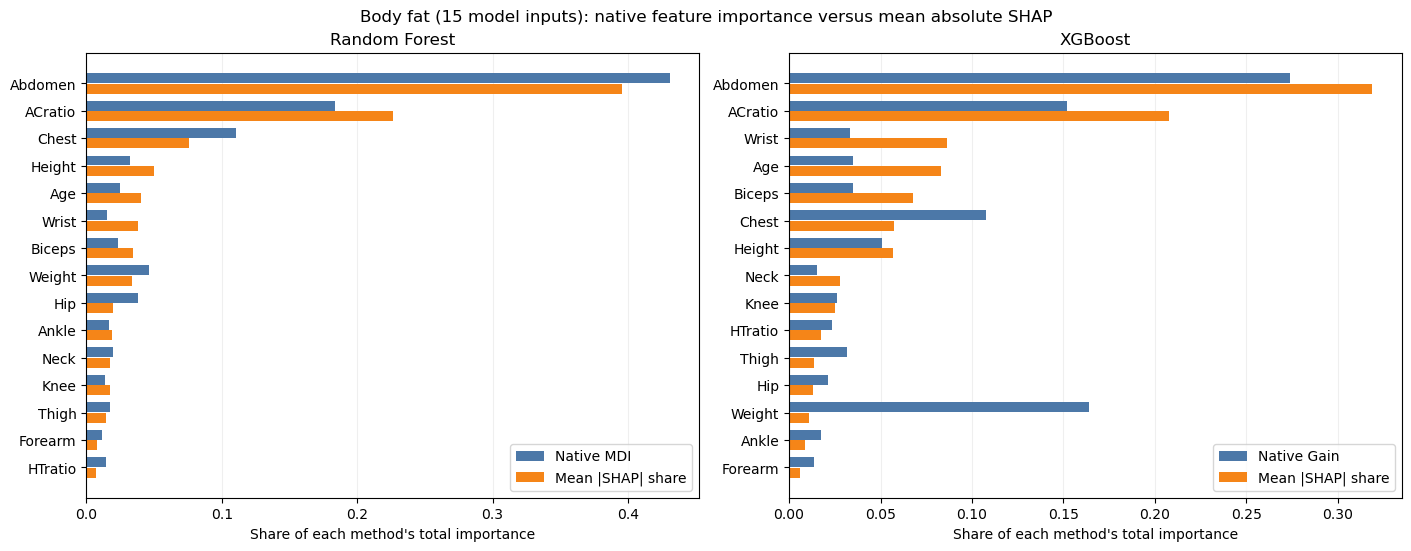

**Within-section observations.**

**Random Forest:** Spearman correlation = 0.821; top-three overlap = 1.000. Highest native importance: Abdomen; highest mean absolute SHAP: Abdomen.

**XGBoost:** Spearman correlation = 0.629; top-three overlap = 0.667. Highest native importance: Abdomen; highest mean absolute SHAP: Abdomen.

These values describe global ranking agreement for these fitted models and evaluation rows; they do not establish correctness or replace the existing local explanation audits.

In [20]:
bodyfat_native_shap_input_rows = prepared_feature_frame(bodyfat_X_test_raw)
np.testing.assert_array_equal(bodyfat_native_shap_input_rows.columns, FEATURE_COLUMNS)
np.testing.assert_allclose(bodyfat_native_shap_input_rows, prepared_test, atol=1e-12, rtol=1e-12)
bodyfat_native_input_shap_values = {}
bodyfat_native_input_mean_abs_shap = {}
for native_shap_method, native_shap_model in bodyfat_tree_models.items():
    native_shap_explainer = shap.TreeExplainer(
        native_shap_model, feature_perturbation="tree_path_dependent", model_output="raw"
    )
    native_shap_values = shap_matrix(native_shap_explainer, bodyfat_native_shap_input_rows)
    if native_shap_values.shape != bodyfat_native_shap_input_rows.shape or not np.isfinite(native_shap_values).all():
        raise ValueError("Direct TreeSHAP must contain one finite attribution per row and model input.")
    np.testing.assert_allclose(
        native_shap_values.sum(axis=1) + np.asarray(native_shap_explainer.expected_value).reshape(-1)[0],
        native_shap_model.predict(bodyfat_native_shap_input_rows), atol=1e-4, rtol=1e-5,
        err_msg=f"Direct TreeSHAP additivity failed for {native_shap_method}",
    )
    bodyfat_native_input_shap_values[native_shap_method] = native_shap_values
    bodyfat_native_input_mean_abs_shap[native_shap_method] = np.mean(np.abs(native_shap_values), axis=0)

bodyfat_native_shap_features, bodyfat_native_shap_agreement = compare_native_with_shap(
    bodyfat_tree_models, FEATURE_COLUMNS, bodyfat_native_input_mean_abs_shap,
    dataset="Body fat (15 model inputs)", n_rows=len(bodyfat_native_shap_input_rows),
)
display_native_shap_comparison(
    bodyfat_native_shap_features, bodyfat_native_shap_agreement, "Body fat (15 model inputs)"
)


### Body fat: correctness

The updated global summary averages the completed subject-feature deletion impacts across all 201 training donors and pairs these with the exact RF/XGBoost/MLP absolute SHAP values. The following subject-level analysis provides the local evidence. Original global scores, based on 20 unpaired donor draws and one permutation cycle, remain in the parent analysis directory for provenance.


In [21]:
bodyfat_local_features = pd.read_csv(BODYFAT_AUDIT_DIR / "local_feature_impacts.csv")
bodyfat_local_features = include_mlp(bodyfat_local_features, "bodyfat", "local_feature_impacts.csv")
bodyfat_correctness_rankings = pd.DataFrame({"Feature": EXPLANATION_COLUMNS})
global_rows = []
for method in SHAP_METHODS:
    g = bodyfat_local_features[bodyfat_local_features.Method==method].groupby("Feature").mean(numeric_only=True).reindex(EXPLANATION_COLUMNS)
    sv = g["Absolute SHAP"].to_numpy()
    dv = g["Mean absolute prediction change"].to_numpy()
    correlation = spearmanr(sv,dv)
    global_rows.append({"Method":method, "Spearman correlation":correlation.statistic,
                       "Normalized profile L1 distance":np.abs(sv/sv.sum()-dv/dv.sum()).sum()})
    bodyfat_correctness_rankings[f"{method} mean |SHAP|"] = sv
    bodyfat_correctness_rankings[f"{method} SHAP rank"] = rankdata(-sv)
    bodyfat_correctness_rankings[f"{method} deletion impact"] = dv
    bodyfat_correctness_rankings[f"{method} deletion rank"] = rankdata(-dv)
bodyfat_deletion_correctness = pd.DataFrame(global_rows)
bodyfat_deletion_correctness.to_csv(COMPARISON_DIRS["bodyfat"] / "single_deletion_correctness.csv",index=False)
bodyfat_correctness_rankings.to_csv(COMPARISON_DIRS["bodyfat"] / "feature_correctness_rankings.csv",index=False)
display(Markdown("**Updated global faithfulness summary (descriptive)**"))
display(bodyfat_deletion_correctness.round(4))
display(bodyfat_correctness_rankings.round(4))


**Updated global faithfulness summary (descriptive)**

,Method,Spearman correlation,Normalized profile L1 distance
0,Random Forest,0.9615,0.1084
1,XGBoost,0.9286,0.1412
2,MLP,0.9890,0.0629


,Feature,Random Forest mean |SHAP|,Random Forest SHAP rank,Random Forest deletion impact,Random Forest deletion rank,XGBoost mean |SHAP|,XGBoost SHAP rank,XGBoost deletion impact,XGBoost deletion rank,MLP mean |SHAP|,MLP SHAP rank,MLP deletion impact,MLP deletion rank
0,Age,0.3145,4.0,0.4533,4.0,0.8320,3.0,1.0842,3.0,1.0268,4.0,1.3800,4.0
1,Weight,0.2186,7.0,0.3221,6.0,0.1002,11.0,0.0959,12.0,0.3556,8.0,0.5354,8.0
2,Height,0.4077,3.0,0.5982,3.0,0.5546,6.0,0.7609,5.0,0.6032,5.0,0.8986,5.0
3,Neck,0.1406,10.0,0.2240,11.0,0.2748,7.0,0.3194,8.0,0.2927,9.0,0.4394,9.0
4,Chest,0.4594,2.0,1.2027,2.0,0.5646,5.0,1.4201,2.0,1.0277,3.0,1.7486,2.0
5,Abdomen,4.5518,1.0,7.0594,1.0,4.8654,1.0,7.6153,1.0,5.3831,1.0,8.6273,1.0
6,Hip,0.1608,8.0,0.3150,8.0,0.1268,10.0,0.2197,10.0,0.0488,13.0,0.0762,13.0
7,Thigh,0.1272,12.0,0.3013,9.0,0.2192,9.0,0.3542,7.0,0.3803,7.0,0.5827,7.0
8,Knee,0.1391,11.0,0.2186,12.0,0.2458,8.0,0.3166,9.0,0.1914,11.0,0.2892,10.0
9,Ankle,0.1464,9.0,0.2502,10.0,0.0872,12.0,0.1338,11.0,0.0823,12.0,0.1216,12.0


**Instance-level correctness: model-faithfulness evidence**

For every test subject and raw feature, measure the mean absolute prediction change across all 201 training donors, with dependent ratios recomputed. Identical donors are used for all three fitted models. Enumerating the empirical distribution removes donor Monte Carlo error in the final result; repeated random budgets from 20 to 1,000 are compared with this exact reference to assess adequacy. This reference is conditional on these training subjects, not a population expectation.

Each subject's impact ranking is compared with their absolute SHAP ranking. Spearman uses average ranks for ties and leaves constant-vector correlations undefined (NaN); the summary reports their number and excludes them from quantiles. Top-three overlap is expressed as a fraction, with fractional inclusion at the third-place boundary; feature-order tie-breaking is retained as a sensitivity column. Medians and IQRs describe the 51 subjects, not population confidence intervals. Low-agreement examples use the smallest correlations, with undefined cases shown first.

This adapts Single Deletion in Nauta et al. (2023), §6.1, pp. 20–21. SHAP averages marginal contributions over coalitions, whereas deletion changes one input while fixing all others, so interactions can produce disagreement. Training-donor replacements preserve individual marginal values but can create unrealistic combinations of measurements; these are faithfulness diagnostics, not causal effects.


impact_L1_p90  impact_rho_median  local_rho_change_p90  \
Method        Donors                                                           
MLP           20             0.1829             0.9780                0.0703   
              50             0.1214             0.9890                0.0538   
              100            0.0842             0.9945                0.0330   
              200            0.0590             0.9945                0.0330   
              500            0.0381             1.0000                0.0275   
              1000           0.0261             1.0000                0.0220   
Random Forest 20             0.1954             0.9670                0.1187   
              50             0.1234             0.9780                0.0813   
              100            0.0797             0.9890                0.0549   
              200            0.0610             0.9945                0.0440   
              500            0.0374             0.9945                0.0495   
              1000           0.0269             1.0000                0.0374   
XGBoost       20             0.1900             0.9780                0.0769   
              50             0.1149             0.9890                0.0549   
              100            0.0839             0.9945                0.0484   
              200            0.0593             0.9945                0.0374   
              500            0.0348             1.0000                0.0275   
              1000           0.0262             1.0000                0.0220   

                      impact_top3_mean  
Method        Donors                    
MLP           20                0.9085  
              50                0.9390  
              100               0.9542  
              200               0.9782  
              500               0.9804  
              1000              0.9826  
Random Forest 20                0.8824  
              50                0.9368  
              100               0.9630  
              200               0.9673  
              500               0.9935  
              1000              0.9913  
XGBoost       20                0.8932  
              50                0.9303  
              100               0.9281  
              200               0.9717  
              500               0.9804  
              1000              0.9847

,Method,Metric,N,Defined N,Undefined N,Median,Q1,Q3,IQR
0,Random Forest,Spearman correlation,51,51,0,0.7308,0.6264,0.8269,0.2005
1,Random Forest,Top-three overlap,51,51,0,0.6667,0.6667,1.0000,0.3333
2,XGBoost,Spearman correlation,51,51,0,0.8462,0.7143,0.8984,0.1841
3,XGBoost,Top-three overlap,51,51,0,0.6667,0.6667,1.0000,0.3333
4,MLP,Spearman correlation,51,51,0,0.8791,0.7967,0.9423,0.1456
5,MLP,Top-three overlap,51,51,0,0.6667,0.6667,1.0000,0.3333


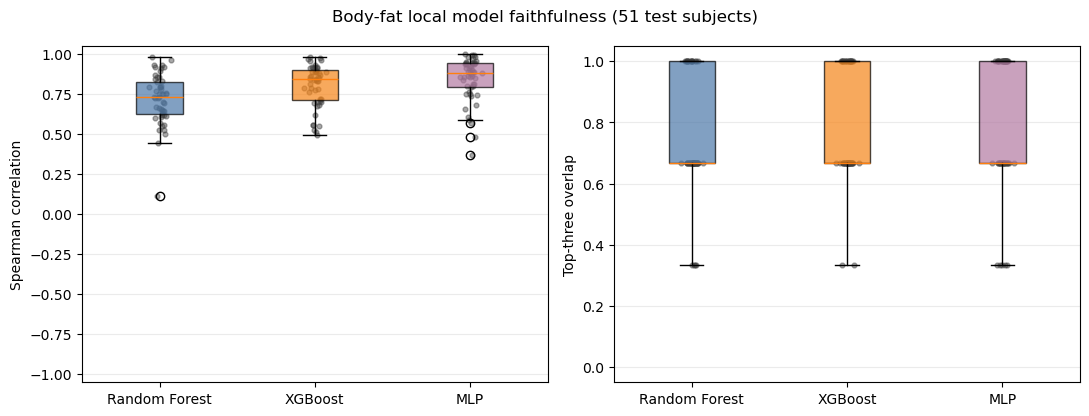

Subjects
Method        Top-three overlap          
MLP           0.333333                  5
              0.666667                 21
              1.000000                 25
Random Forest 0.333333                  4
              0.666667                 32
              1.000000                 15
XGBoost       0.333333                  2
              0.666667                 30
              1.000000                 19

,Method,source_row_index,Spearman correlation,Top-three overlap,Top-three overlap (feature-order ties),Undefined correlation,SHAP tied values,Impact tied values,Top SHAP features,Top deletion features
0,Random Forest,96,0.1154,0.6667,0.6667,False,0,0,"Abdomen, Height, Age","Abdomen, Chest, Height"
1,MLP,162,0.3681,0.3333,0.3333,False,0,0,"Wrist, Age, Thigh","Abdomen, Wrist, Chest"
2,Random Forest,235,0.4451,0.6667,0.6667,False,0,0,"Abdomen, Height, Age","Abdomen, Chest, Height"
3,MLP,101,0.4835,0.3333,0.3333,False,0,0,"Wrist, Biceps, Height","Abdomen, Wrist, Chest"
4,XGBoost,68,0.4945,1.0000,1.0000,False,0,0,"Abdomen, Biceps, Chest","Abdomen, Chest, Biceps"
5,Random Forest,172,0.5000,0.6667,0.6667,False,0,0,"Age, Abdomen, Height","Abdomen, Chest, Height"
6,XGBoost,178,0.5110,0.6667,0.6667,False,0,0,"Age, Abdomen, Biceps","Abdomen, Chest, Age"
7,XGBoost,124,0.5275,0.6667,0.6667,False,0,0,"Abdomen, Biceps, Knee","Abdomen, Biceps, Chest"
8,MLP,178,0.5714,0.6667,0.6667,False,0,0,"Age, Chest, Thigh","Abdomen, Chest, Age"


In [22]:
if RERUN_BODYFAT_DELETION:
    # Enumerate all 201 training donors once: an exact reference for the chosen
    # empirical replacement estimand, with no Monte Carlo error in final scores.
    # Independent random draws below check what the former 20-donor budget misses.
    n, p, d = len(bodyfat_X_test_raw), len(EXPLANATION_COLUMNS), len(bodyfat_X_train_raw)
    donor_changes = {}
    for method, predict in bodyfat_tree_predict.items():
        clean = predict(bodyfat_X_test_raw)
        changes = np.empty((n, p, d))
        for j in range(p):
            rows = np.repeat(bodyfat_X_test_raw.to_numpy(), d, axis=0)
            rows[:, j] = np.tile(bodyfat_X_train_raw.iloc[:, j].to_numpy(), n)
            changes[:, j, :] = np.abs(predict(rows).reshape(n, d)-clean[:, None])
        donor_changes[method] = changes
        print("All training donors evaluated:", method, flush=True)
    donor_seeds, donor_budgets = [42, 1729, 2026], [20, 50, 100, 200, 500, 1000]
    donor_indices = np.stack([np.random.default_rng(s).integers(d, size=(n, p, max(donor_budgets))) for s in donor_seeds])
    budget_rows, local_rows, impacts_long, replicate_rows = [], [], [], []
    for method, changes in donor_changes.items():
        exact = changes.mean(axis=2)
        shap_values = np.abs(bodyfat_saved_shap[method])
        for i, subject in enumerate(bodyfat_subject_ids):
            rec = local_agreement(shap_values[i], exact[i])
            local_rows.append({"Method": method, "source_row_index": subject, **rec})
            for j, feature in enumerate(EXPLANATION_COLUMNS):
                impacts_long.append({"Method": method, "source_row_index": subject, "Feature": feature,
                                     "Mean absolute prediction change": exact[i,j], "Absolute SHAP": shap_values[i,j],
                                     "SHAP rank": rankdata(-shap_values[i])[j], "Impact rank": rankdata(-exact[i])[j]})
        for si, seed in enumerate(donor_seeds):
            drawn = np.take_along_axis(changes, donor_indices[si], axis=2)
            for budget in donor_budgets:
                estimate = drawn[:, :, :budget].mean(axis=2)
                for i, subject in enumerate(bodyfat_subject_ids):
                    agr = local_agreement(estimate[i], exact[i])
                    estimated_rho = local_agreement(shap_values[i], estimate[i])["Spearman correlation"]
                    exact_rho = local_agreement(shap_values[i], exact[i])["Spearman correlation"]
                    budget_rows.append({"Method": method, "source_row_index": subject, "Donors": budget, "Seed": seed,
                                        "Impact rank rho": agr["Spearman correlation"], "Impact top-three overlap": agr["Top-three overlap"],
                                        "Normalized impact L1": np.abs(estimate[i]-exact[i]).sum()/max(exact[i].sum(),1e-12),
                                        "Local rho difference": abs(estimated_rho-exact_rho)})
        with np.load(BODYFAT_AUDIT_DIR / "shap_values.npz") as a:
            for si, values in enumerate(a[method.lower().replace(" ", "_")+"_replicates"]):
                for i, subject in enumerate(bodyfat_subject_ids):
                    replicate_rows.append({"Method": method, "source_row_index": subject,
                                           "Seed": int(a["seeds"][si]), **local_agreement(np.abs(values[i]), exact[i])})
    bodyfat_local = pd.DataFrame(local_rows)
    bodyfat_local.to_csv(BODYFAT_AUDIT_DIR / "local_correctness.csv", index=False)
    pd.DataFrame(impacts_long).to_csv(BODYFAT_AUDIT_DIR / "local_feature_impacts.csv", index=False)
    agreement_summary(bodyfat_local).to_csv(BODYFAT_AUDIT_DIR / "local_correctness_summary.csv", index=False)
    pd.DataFrame(budget_rows).to_csv(BODYFAT_AUDIT_DIR / "deletion_budget_rows.csv", index=False)
    pd.DataFrame(replicate_rows).to_csv(BODYFAT_AUDIT_DIR / "local_correctness_shap_repeats.csv", index=False)
    np.savez_compressed(BODYFAT_AUDIT_DIR / "deletion_donors.npz", **{m.lower().replace(" ", "_"): c for m,c in donor_changes.items()},
                        random_donor_indices=donor_indices, random_seeds=donor_seeds, random_budgets=donor_budgets,
                        source_row_index=bodyfat_subject_ids, donor_source_row_index=bodyfat_train_rows.source_row_index.to_numpy(),
                        feature_names=EXPLANATION_COLUMNS)
    (BODYFAT_AUDIT_DIR / "deletion_manifest.json").write_text(json.dumps({
        "status": "completed", "final_budget": d, "sampling": "all training donors exactly once per subject-feature-model; uniform empirical expectation",
        "draws_paired_across_models": True, "random_budget_check_seeds": donor_seeds, "random_budgets": donor_budgets,
        "impact": "mean_d abs(f(x with raw feature j from training donor d)-f(x)); derived ratios recomputed",
        "ties": "Spearman average ranks; constant vectors yield NaN; fractional top-three boundary membership, plus feature-order sensitivity",
        "limitations": "Single-feature replacements can create unrealistic combinations; interactions differ from SHAP coalition averaging; descriptive faithfulness evidence, not causal or population inference"
    }, indent=2), encoding="utf-8")

bodyfat_local = pd.read_csv(BODYFAT_AUDIT_DIR / "local_correctness.csv")
bodyfat_local_summary = pd.read_csv(BODYFAT_AUDIT_DIR / "local_correctness_summary.csv")
bodyfat_local_features = pd.read_csv(BODYFAT_AUDIT_DIR / "local_feature_impacts.csv")
bodyfat_deletion_budget = pd.read_csv(BODYFAT_AUDIT_DIR / "deletion_budget_rows.csv")
bodyfat_local = include_mlp(bodyfat_local, "bodyfat", "local_correctness.csv")
bodyfat_local_summary = include_mlp(bodyfat_local_summary, "bodyfat", "local_correctness_summary.csv")
bodyfat_local_features = include_mlp(bodyfat_local_features, "bodyfat", "local_feature_impacts.csv")
bodyfat_deletion_budget = include_mlp(bodyfat_deletion_budget, "bodyfat", "deletion_budget_rows.csv")

display(bodyfat_deletion_budget.groupby(["Method", "Donors"]).agg(
    impact_L1_p90=("Normalized impact L1", lambda s:s.quantile(.9)),
    impact_rho_median=("Impact rank rho", "median"),
    local_rho_change_p90=("Local rho difference", lambda s:s.quantile(.9)),
    impact_top3_mean=("Impact top-three overlap", "mean")).round(4))
assert len(bodyfat_local) == len(bodyfat_subject_ids)*len(bodyfat_models)
for method, group in bodyfat_local.groupby("Method"):
    assert set(group.source_row_index) == set(bodyfat_subject_ids)
assert len(bodyfat_local_features) == len(bodyfat_subject_ids)*len(EXPLANATION_COLUMNS)*len(bodyfat_models)
display(bodyfat_local_summary.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, metric in zip(axes, ["Spearman correlation", "Top-three overlap"]):
    groups = [bodyfat_local.loc[bodyfat_local.Method == m, metric].dropna() for m in bodyfat_models]
    box = ax.boxplot(groups, tick_labels=list(bodyfat_models), patch_artist=True)
    for patch, method in zip(box["boxes"], bodyfat_models):
        patch.set_facecolor(COLORS[method]); patch.set_alpha(.7)
    for x, group in enumerate(groups, 1):
        ax.scatter(np.full(len(group),x)+np.random.default_rng(42).normal(0,.035,len(group)), group, s=12, alpha=.45, color="0.25")
    ax.set_ylabel(metric); ax.grid(axis="y", alpha=.25)
axes[0].set_ylim(-1.05, 1.05); axes[1].set_ylim(-.05, 1.05)
fig.suptitle("Body-fat local model faithfulness (51 test subjects)")
plt.tight_layout(); plt.show()
display(bodyfat_local.groupby(["Method", "Top-three overlap"]).size().rename("Subjects").to_frame())
low_examples = bodyfat_local.sort_values("Spearman correlation", na_position="first").groupby("Method", sort=False).head(3)
example_rows = []
for _, row in low_examples.iterrows():
    f = bodyfat_local_features[(bodyfat_local_features.Method==row.Method)&(bodyfat_local_features.source_row_index==row.source_row_index)]
    example_rows.append({**row.to_dict(), "Top SHAP features": ", ".join(f.sort_values("SHAP rank", kind="stable").Feature.head(3)),
                         "Top deletion features": ", ".join(f.sort_values("Impact rank", kind="stable").Feature.head(3))})
display(pd.DataFrame(example_rows).round(4))


### Body fat: completeness

The same preservation/addition and deletion definitions are applied to all 51 test subjects, with each model's local features ranked by the validated exact absolute SHAP values. The paired donors are the 50 fixed training-background rows used by the exact SHAP calculation; each donor is enumerated once for every subject, subset and model. Thirty-two repeated random feature orders use the same donor rows. This keeps the functional test aligned with the SHAP background and removes donor Monte Carlo error conditional on that background.

All replacements occur in the 13 raw-measurement explanation space. The existing prediction wrapper then recomputes `ACratio = Abdomen / Chest` and `HTratio = Hip / Thigh` after every replacement before constructing the fitted model input. Raw preservation errors and deletion changes are percentage points. The normalized curves, 90%-SHAP subset checks, sustained 5%-of-training-prediction-SD reconstruction tolerance, near-zero-denominator rule, endpoint checks and non-monotonicity reporting are identical to the Feynman protocol above.

A whole donor row keeps dependence among simultaneously replaced measurements, but the hybrid boundary between retained measurements from the test subject and replaced measurements from a donor can still break correlations and create anatomically implausible combinations. Recomputed ratios ensure deterministic feature engineering; they do not make the hybrid observation realistic. These are conditional fitted-model diagnostics, not causal interventions or population estimates.

,Method,Mean features for 90% absolute SHAP,Mean normalized preservation error at 90% SHAP,Mean matched-random normalized preservation error,Mean normalized deletion change at 90% SHAP,Mean matched-random normalized deletion change,Reconstruction tolerance,Median sustained reconstruction features,Subjects with preservation direction reversal,Subjects with deletion direction reversal,Subjects with undefined normalization
0,Random Forest,6.3529,0.1003,0.5629,0.9679,0.5514,0.3740,11.0,48,50,0
1,XGBoost,5.9412,0.1247,0.6403,1.0029,0.5642,0.3702,10.0,51,51,0
2,MLP,6.4314,0.1629,0.6619,0.9744,0.6588,0.3561,11.0,51,51,0


,Dataset,Method,Full-preservation maximum error,Zero-deletion maximum change,All-replaced endpoint maximum discrepancy,Maximum additivity residual,Median additivity residual,Numerical endpoint floor,Normalization epsilon
0,Body fat,Random Forest,0.000e+00,0.000e+00,0.000e+00,2.984e-13,6.395e-14,0.000000,0.000007
1,Body fat,XGBoost,0.000e+00,0.000e+00,0.000e+00,1.386e-13,4.619e-14,0.000000,0.000007
2,Body fat,MLP,6.821e-15,6.821e-15,0.000e+00,1.776e-13,6.395e-14,0.000000,0.000007


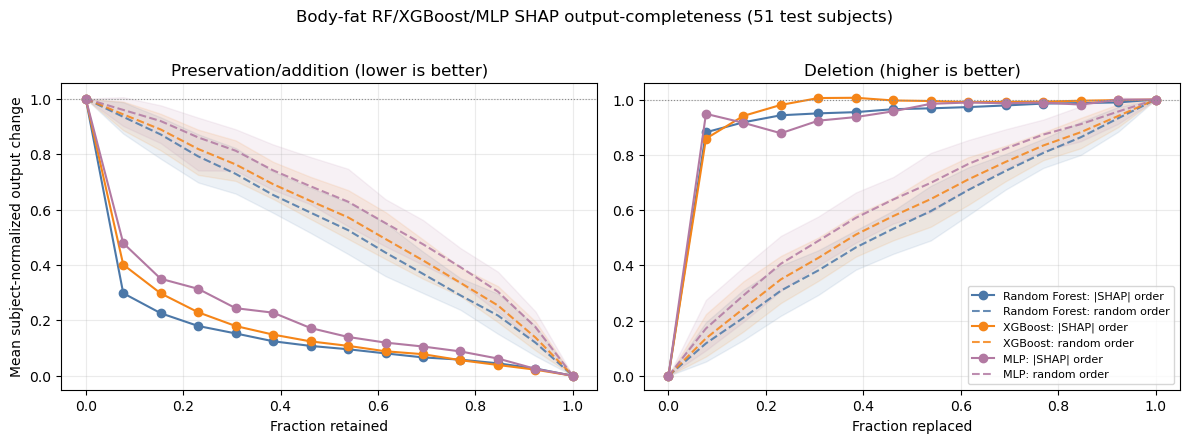

In [23]:
RERUN_BODYFAT_COMPLETENESS = False
BODYFAT_COMPLETENESS_REQUIRED = [
    BODYFAT_AUDIT_DIR / "completeness_manifest.json",
    BODYFAT_AUDIT_DIR / "completeness_curves.csv",
    BODYFAT_AUDIT_DIR / "completeness_subjects.csv",
    BODYFAT_AUDIT_DIR / "completeness_summary.csv",
    BODYFAT_AUDIT_DIR / "completeness_endpoint_checks.csv",
    BODYFAT_AUDIT_DIR / "completeness_design.npz",
]
bodyfat_completeness_stale = False
if BODYFAT_COMPLETENESS_REQUIRED[0].exists():
    bodyfat_completeness_stale = (
        json.loads(BODYFAT_COMPLETENESS_REQUIRED[0].read_text(encoding="utf-8"))
        .get("protocol_version")
        != COMPLETENESS_PROTOCOL_VERSION
    )

if RERUN_BODYFAT_COMPLETENESS or bodyfat_completeness_stale or not all(
    path.exists() for path in BODYFAT_COMPLETENESS_REQUIRED
):
    with np.load(BODYFAT_AUDIT_DIR / "shap_values.npz") as archive:
        np.testing.assert_array_equal(archive["feature_names"], EXPLANATION_COLUMNS)
        np.testing.assert_array_equal(archive["source_row_index"], bodyfat_subject_ids)
        bodyfat_completeness_shap = {
            method: archive[method.lower().replace(" ", "_")].copy()
            for method in bodyfat_tree_models
        }
        bodyfat_completeness_base = {
            method: archive[method.lower().replace(" ", "_") + "_base_values"].copy()
            for method in bodyfat_tree_models
        }
        np.testing.assert_allclose(
            archive["background_values"], bodyfat_background.to_numpy(), atol=0, rtol=0
        )
    bodyfat_donor_indices = np.tile(
        np.arange(len(bodyfat_background)), (len(bodyfat_X_test_raw), 1)
    )
    run_output_completeness(
        dataset="Body fat",
        output_dir=BODYFAT_AUDIT_DIR,
        X_eval=bodyfat_X_test_raw,
        observation_ids=bodyfat_subject_ids,
        X_training=bodyfat_X_train_raw,
        donor_pool=bodyfat_background,
        donor_indices=bodyfat_donor_indices,
        feature_names=EXPLANATION_COLUMNS,
        predictors=bodyfat_tree_predict,
        shap_values=bodyfat_completeness_shap,
        base_values=bodyfat_completeness_base,
        random_repeats=32,
        random_order_seed=314160,
        target_unit="body-fat percentage points",
        shap_source="outputs/bodyfat/analysis/reliability_audit/shap_values.npz; exact 8,192-coalition SHAP over the fixed 50-row training background",
        donor_protocol="All 50 fixed SHAP-background rows enumerated once per explained row and subset; paired across models and checks",
        source_files=[
            "outputs/bodyfat/analysis/reliability_audit/shap_values.npz",
            "hpc_results/bodyfat/prepared/train_raw_split.csv",
            "hpc_results/bodyfat/prepared/test_raw_split.csv",
            "hpc_results/bodyfat/random_forest_20260719_232404/rf_best.joblib",
            "hpc_results/bodyfat/xgboost_20260719_232404/xgb_best.joblib",
        ],
    )

bodyfat_completeness_curves = include_mlp(pd.read_csv(BODYFAT_AUDIT_DIR / "completeness_curves.csv"), "bodyfat", "completeness_curves.csv")
bodyfat_completeness_subjects = include_mlp(pd.read_csv(BODYFAT_AUDIT_DIR / "completeness_subjects.csv"), "bodyfat", "completeness_subjects.csv")
bodyfat_completeness_summary = include_mlp(pd.read_csv(BODYFAT_AUDIT_DIR / "completeness_summary.csv"), "bodyfat", "completeness_summary.csv")
bodyfat_completeness_endpoints = include_mlp(pd.read_csv(BODYFAT_AUDIT_DIR / "completeness_endpoint_checks.csv"), "bodyfat", "completeness_endpoint_checks.csv")
display(
    bodyfat_completeness_summary[
        [
            "Method",
            "Mean features for 90% absolute SHAP",
            "Mean normalized preservation error at 90% SHAP",
            "Mean matched-random normalized preservation error",
            "Mean normalized deletion change at 90% SHAP",
            "Mean matched-random normalized deletion change",
            "Reconstruction tolerance",
            "Median sustained reconstruction features",
            "Subjects with preservation direction reversal",
            "Subjects with deletion direction reversal",
            "Subjects with undefined normalization",
        ]
    ].round(4)
)
display(bodyfat_completeness_endpoints.style.format({
    "Full-preservation maximum error": "{:.3e}",
    "Zero-deletion maximum change": "{:.3e}",
    "All-replaced endpoint maximum discrepancy": "{:.3e}",
    "Maximum additivity residual": "{:.3e}",
    "Median additivity residual": "{:.3e}",
}))
plot_completeness_curves(
    bodyfat_completeness_curves,
    "Body-fat RF/XGBoost/MLP SHAP output-completeness (51 test subjects)",
    COMPARISON_DIRS["bodyfat"] / "completeness_curves.png",
)

**Interpretation.** The displayed 90%-SHAP subset results and complete curves are empirical output-completeness measurements for RF/XGBoost/MLP, not evidence that feature attributions reproduce every internal reasoning step. The separately reported sustained-tolerance feature count measures prediction reconstruction directly and can differ from the attribution-coverage count. Any direction reversals are retained because interactions and hybrid donor inputs can make addition or deletion non-monotonic.

The displayed PySR equation plus its audited input preparation, inactive-on-these-rows median-imputation rule, and identity output transformation constitute the complete prediction rule for the fitted symbolic model. That rule is reasoning-complete with respect to the model itself: its mathematical operations and parameters are exposed. It does **not** establish that the equation is a complete or correct account of human body composition, especially in a small observational dataset. No PySR SHAP calculation is used for this primary comparison.

### Body fat: continuity

Aggregate RMSE under noise, individual prediction sensitivity and explanation continuity answer different questions and are displayed separately. The existing 100-repeat prediction experiment on all 51 test subjects is retained unchanged. The corrected explanation audit uses the same paired perturbation stream, but its actual design is **12 previously fixed audit subjects x 10 repeats = 120 candidate pairs per model and non-zero noise level**. The subset spans pooled fitted predictions and includes the largest standardized raw-feature outlier; it was fixed during SHAP calibration before continuity outcomes were inspected.

Every SHAP calculation uses exact enumeration of all 8,192 coalitions, an identity link, 13 raw-measurement explanation features, and the fixed 50-row training background sampled without replacement with `random_state=42`. Noise is applied in raw space at 2.5% and 5% of feature-specific training SD. `ACratio = Abdomen/Chest` and `HTratio = Hip/Thigh` are then recomputed by the prediction wrapper. Inputs must remain finite and positive; `Chest` and `Thigh` must be non-zero. Training-range violations are counted but not clipped.

The primary response-stability threshold is **0.433743 body-fat percentage points**, equal to 5% of the training-response SD. Retained counts and proportions are reported explicitly, and the filter is repeated at 2.5%, 5% and 10% to check threshold sensitivity. Cosine similarity measures direction with cosine = 1 for two zero vectors and 0 if exactly one is zero. The magnitude-sensitive distance is the **mean absolute attribution distance**, $13^{-1}\sum_j |\phi_j(x')-\phi_j(x)|$, in body-fat percentage points per feature; it is 0 for two zero vectors and retains the non-zero magnitude for a one-zero pair.

Estimation variability is controlled rather than conflated with perturbation sensitivity. Two fresh exact explainers independently recomputed all 51 unchanged test inputs and returned identical attributions; the original SHAP array was not reused as a repeat. Exact enumeration removes permutation Monte Carlo variability conditional on this fixed background, but not background dependence or floating-point effects. Displayed explanation intervals are empirical 2.5th and 97.5th percentiles of repeat-level means from repeated perturbations of the same 12 subjects, not independent-subject or population confidence intervals.

Native PySR is treated in its own representation. The single fitted global equation is structurally unchanged across inputs. Its prediction changes under the same perturbations are labelled **equation/model sensitivity**, not SHAP continuity, and no cosine or attribution-distance value is assigned. The original low-budget PySR SHAP files remain in `outputs/bodyfat/analysis` for provenance but are excluded from the primary comparison.
MLP reuses the saved 12 audit subjects; their historical tree-informed selection is not recalculated after adding MLP. The same 10 explanation and 100 prediction repeats are paired across models.


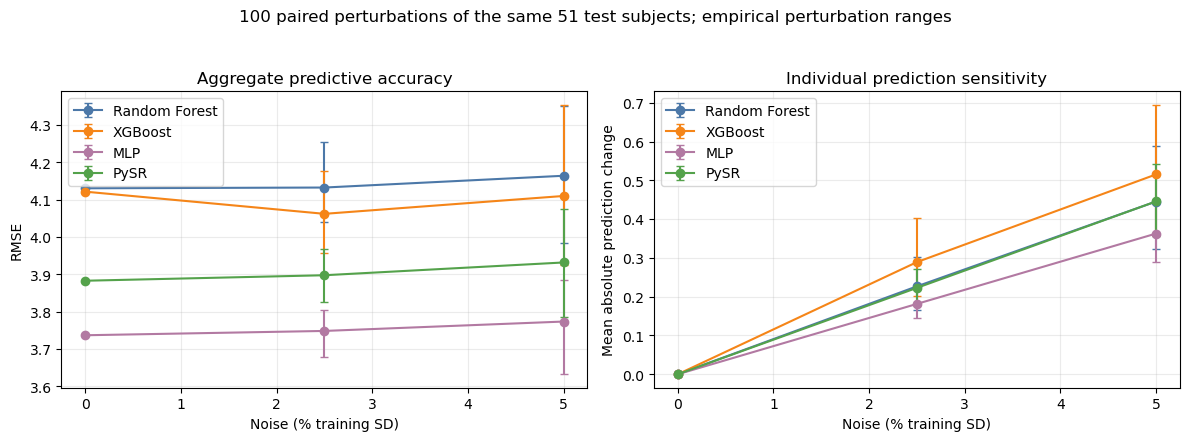

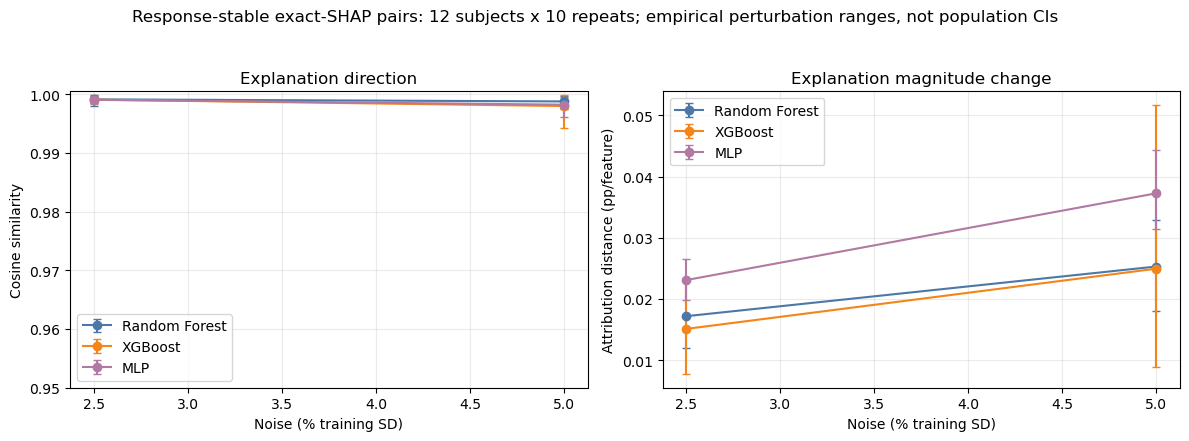

**Primary RF/XGBoost/MLP exact-SHAP continuity (5% response-SD threshold)**

,Method,Noise (% training SD),Explanation subjects,Perturbation repeats,Candidate explanation pairs,Retained explanation pairs,Retained proportion,Response-stability threshold (percentage points),Mean cosine similarity,Median cosine similarity,Repeat-mean cosine 2.5%,Repeat-mean cosine 97.5%,Mean absolute attribution distance,Median absolute attribution distance,Repeat-mean attribution distance 2.5%,Repeat-mean attribution distance 97.5%,Both-zero vector pairs,One-zero vector pairs
0,Random Forest,2.5,12,10,120,104,0.866667,0.433743,0.999134,0.999935,0.998047,0.999809,0.017219,0.013182,0.012028,0.022893,0,0
1,Random Forest,5.0,12,10,120,90,0.750000,0.433743,0.998780,0.999841,0.997438,0.999677,0.025331,0.023972,0.018015,0.032938,0,0
2,XGBoost,2.5,12,10,120,83,0.691667,0.433743,0.999087,0.999953,0.998281,0.999860,0.015143,0.008195,0.007733,0.023365,0,0
3,XGBoost,5.0,12,10,120,74,0.616667,0.433743,0.997993,0.999839,0.994198,0.999879,0.024982,0.018723,0.008986,0.051744,0,0
4,MLP,2.5,12,10,120,110,0.916667,0.433743,0.999049,NaN,0.998515,0.999698,0.023117,NaN,0.019853,0.026636,0,0
5,MLP,5.0,12,10,120,78,0.650000,0.433743,0.998230,NaN,0.996146,0.999487,0.037296,NaN,0.031507,0.044318,0,0


**Response-threshold sensitivity**

,Method,Noise (% training SD),Threshold (% training response SD),Threshold (percentage points),Candidate explanation pairs,Retained explanation pairs,Retained proportion,Mean cosine similarity,Mean absolute attribution distance
0,Random Forest,2.5,2.5,0.216871,120,83,0.691667,0.999675,0.012384
1,Random Forest,5.0,2.5,0.216871,120,66,0.550000,0.999279,0.019777
2,XGBoost,2.5,2.5,0.216871,120,67,0.558333,0.999374,0.010810
3,XGBoost,5.0,2.5,0.216871,120,53,0.441667,0.998897,0.018413
4,Random Forest,2.5,5.0,0.433743,120,104,0.866667,0.999134,0.017219
5,Random Forest,5.0,5.0,0.433743,120,90,0.750000,0.998780,0.025331
6,XGBoost,2.5,5.0,0.433743,120,83,0.691667,0.999087,0.015143
7,XGBoost,5.0,5.0,0.433743,120,74,0.616667,0.997993,0.024982
8,Random Forest,2.5,10.0,0.867486,120,113,0.941667,0.997699,0.021656
9,Random Forest,5.0,10.0,0.867486,120,105,0.875000,0.996727,0.032092


**Independent unchanged-input exact-SHAP repeatability**

...

**Input and native-equation domain audit over all 100 x 51 perturbed rows per level**

,Noise (% training SD),Evaluated subject-perturbation rows,Finite raw rows,Non-positive raw cells,Finite prepared rows,Minimum Chest,Minimum Thigh,ACratio minimum,ACratio maximum,HTratio minimum,HTratio maximum,Rows with any training-range violation,Newly out-of-training-range cells,PySR minimum absolute denominator,PySR numerical singularity tolerance,PySR near-zero denominators,Finite PySR predictions,Maximum absolute PySR prediction,Maximum native-equation gradient norm
0,2.5,5100,5100,0,5100,88.880671,50.038957,0.810409,1.094160,1.541500,1.787984,200,53,147.890206,2.000000e-08,0,5100,44.082123,2.170399
1,5.0,5100,5100,0,5100,88.461343,49.777914,0.800655,1.100981,1.532091,1.801552,209,63,145.930411,2.000000e-08,0,5100,44.575899,2.200229


**Zero-noise prediction checks**

,Method,Rows,Maximum zero-noise prediction change,Exact zero-noise check
0,Random Forest,51,0.0,True
1,XGBoost,51,0.0,True
2,PySR,51,0.0,True
3,MLP,51,0.0,True


Response-stability threshold: 0.433743 percentage points; fixed SHAP background: 50 training rows sampled with random_state=42.


In [24]:
RERUN_BODYFAT_CONTINUITY = False
bodyfat_continuity_required = [
    BODYFAT_AUDIT_DIR / "continuity_manifest.json",
    BODYFAT_AUDIT_DIR / "continuity_summary.csv",
    BODYFAT_AUDIT_DIR / "continuity_repeat_summary.csv",
    BODYFAT_AUDIT_DIR / "continuity_threshold_sensitivity.csv",
    BODYFAT_AUDIT_DIR / "continuity_input_validity.csv",
    BODYFAT_AUDIT_DIR / "continuity_zero_noise_prediction_checks.csv",
    BODYFAT_AUDIT_DIR / "native_equation_sensitivity_summary.csv",
]
if RERUN_BODYFAT_CONTINUITY or not all(path.exists() for path in bodyfat_continuity_required):
    from scripts.bodyfat_continuity_audit import run_bodyfat_continuity
    run_bodyfat_continuity(PROJECT_ROOT)

bodyfat_noise = pd.read_csv(project_path("outputs/bodyfat/analysis/noise_sensitivity.csv"))
bodyfat_noise_repeats = pd.read_csv(
    project_path("outputs/bodyfat/analysis/noise_sensitivity_repeats.csv")
)
with (BODYFAT_AUDIT_DIR / "continuity_manifest.json").open(encoding="utf-8") as handle:
    bodyfat_continuity_manifest = json.load(handle)
bodyfat_continuity = pd.read_csv(BODYFAT_AUDIT_DIR / "continuity_summary.csv")
bodyfat_continuity_repeats = pd.read_csv(
    BODYFAT_AUDIT_DIR / "continuity_repeat_summary.csv"
)
bodyfat_threshold_sensitivity = pd.read_csv(
    BODYFAT_AUDIT_DIR / "continuity_threshold_sensitivity.csv"
)
bodyfat_input_validity = pd.read_csv(
    BODYFAT_AUDIT_DIR / "continuity_input_validity.csv"
)
bodyfat_zero_noise = pd.read_csv(
    BODYFAT_AUDIT_DIR / "continuity_zero_noise_prediction_checks.csv"
)
bodyfat_equation_sensitivity = pd.read_csv(
    BODYFAT_AUDIT_DIR / "native_equation_sensitivity_summary.csv"
)
bodyfat_repeatability = pd.read_csv(
    BODYFAT_AUDIT_DIR / "shap_identical_input_repeats.csv"
)

bodyfat_noise = include_mlp(bodyfat_noise, "bodyfat", "noise_sensitivity.csv")
bodyfat_noise_repeats = include_mlp(bodyfat_noise_repeats, "bodyfat", "noise_sensitivity_repeats.csv")
bodyfat_continuity = include_mlp(bodyfat_continuity, "bodyfat", "continuity_summary.csv")
bodyfat_continuity_repeats = include_mlp(bodyfat_continuity_repeats, "bodyfat", "continuity_repeat_summary.csv")
bodyfat_threshold_sensitivity = include_mlp(bodyfat_threshold_sensitivity, "bodyfat", "continuity_threshold_sensitivity.csv")
bodyfat_zero_noise = include_mlp(bodyfat_zero_noise, "bodyfat", "continuity_zero_noise_prediction_checks.csv")
bodyfat_repeatability = include_mlp(bodyfat_repeatability, "bodyfat", "shap_identical_input_repeats.csv")

prediction_ranges = (
    bodyfat_noise_repeats.groupby(["Method", "Noise (% training SD)"])
    ["Mean absolute prediction change"]
    .quantile([0.025, 0.975])
    .unstack()
    .reset_index()
    .rename(columns={0.025: "Prediction change 2.5%", 0.975: "Prediction change 97.5%"})
)
bodyfat_tree_prediction_plot = bodyfat_noise.merge(
    prediction_ranges, on=["Method", "Noise (% training SD)"], how="left"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for method in PREDICTIVE_METHODS:
    subset = bodyfat_tree_prediction_plot[
        bodyfat_tree_prediction_plot["Method"] == method
    ].sort_values("Noise (% training SD)")
    axes[0].errorbar(
        subset["Noise (% training SD)"], subset["RMSE"],
        yerr=errorbar_from_columns(subset, "RMSE", "RMSE 2.5%", "RMSE 97.5%"),
        marker="o", capsize=3, color=COLORS[method], label=method,
    )
    axes[1].errorbar(
        subset["Noise (% training SD)"], subset["Mean absolute prediction change"],
        yerr=errorbar_from_columns(
            subset, "Mean absolute prediction change",
            "Prediction change 2.5%", "Prediction change 97.5%"
        ),
        marker="o", capsize=3, color=COLORS[method], label=method,
    )
axes[0].set(title="Aggregate predictive accuracy", ylabel="RMSE")
axes[1].set(title="Individual prediction sensitivity", ylabel="Mean absolute prediction change")
for axis in axes:
    axis.set_xlabel("Noise (% training SD)")
    axis.grid(alpha=0.25)
    axis.legend()
fig.suptitle(
    "100 paired perturbations of the same 51 test subjects; empirical perturbation ranges",
    y=1.04,
)
plt.tight_layout()
fig.savefig(COMPARISON_DIRS["bodyfat"] / "continuity_prediction_context.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for method in SHAP_METHODS:
    subset = bodyfat_continuity[bodyfat_continuity["Method"] == method].sort_values(
        "Noise (% training SD)"
    )
    axes[0].errorbar(
        subset["Noise (% training SD)"], subset["Mean cosine similarity"],
        yerr=errorbar_from_columns(
            subset, "Mean cosine similarity",
            "Repeat-mean cosine 2.5%", "Repeat-mean cosine 97.5%"
        ),
        marker="o", capsize=3, color=COLORS[method], label=method,
    )
    axes[1].errorbar(
        subset["Noise (% training SD)"], subset["Mean absolute attribution distance"],
        yerr=errorbar_from_columns(
            subset, "Mean absolute attribution distance",
            "Repeat-mean attribution distance 2.5%",
            "Repeat-mean attribution distance 97.5%",
        ),
        marker="o", capsize=3, color=COLORS[method], label=method,
    )
axes[0].set(title="Explanation direction", ylabel="Cosine similarity", ylim=(0.95, 1.0005))
axes[1].set(
    title="Explanation magnitude change",
    ylabel="Attribution distance (pp/feature)",
)
for axis in axes:
    axis.set_xlabel("Noise (% training SD)")
    axis.grid(alpha=0.25)
    axis.legend()
fig.suptitle(
    "Response-stable exact-SHAP pairs: 12 subjects x 10 repeats; empirical perturbation ranges, not population CIs",
    y=1.04,
)
plt.tight_layout()
fig.savefig(COMPARISON_DIRS["bodyfat"] / "continuity_explanations.png", dpi=200, bbox_inches="tight")
plt.show()

display(Markdown("**Primary RF/XGBoost/MLP exact-SHAP continuity (5% response-SD threshold)**"))
display(bodyfat_continuity.round(6))
display(Markdown("**Response-threshold sensitivity**"))
display(bodyfat_threshold_sensitivity.round(6))

bodyfat_repeatability_summary = bodyfat_repeatability.groupby("Method").agg(
    independently_recomputed_rows=("source_row_index", "size"),
    maximum_normalized_L1=("Normalized L1 difference", "max"),
    maximum_attribution_MAE=("Attribution MAE", "max"),
    maximum_90pct_count_difference=("90% count difference", "max"),
).reset_index()
display(Markdown("**Independent unchanged-input exact-SHAP repeatability**"))
display(bodyfat_repeatability_summary.round(12))
display(Markdown("**Native PySR equation/model sensitivity on the same 12 x 10 input pairs**"))
display(bodyfat_equation_sensitivity.round(6))
display(Markdown("**Input and native-equation domain audit over all 100 x 51 perturbed rows per level**"))
display(bodyfat_input_validity.round(8))
display(Markdown("**Zero-noise prediction checks**"))
display(bodyfat_zero_noise)
print(
    "Response-stability threshold:",
    f"{bodyfat_continuity_manifest['primary_response_stability_threshold']:.6f} percentage points;",
    "fixed SHAP background:", len(bodyfat_continuity_manifest["background_ids"]),
    "training rows sampled with random_state=42."
)

### Body fat: compactness

RF/XGBoost/MLP compactness uses the same validated exact-SHAP arrays, 51 subject identifiers and final 13-raw-feature representation as local correctness and the beeswarms. The primary 90% distribution and the 80%/95% sensitivity checks use the definition and explicit zero-total rule introduced in the Feynman section.

The unchanged historical file `outputs/bodyfat/analysis/compactness.csv` is retained for provenance. Its previously reported PySR value of 2.84 features is a legacy **SHAP-on-PySR** result and is not displayed as native equation compactness or used in the primary comparison.

Native PySR is instead audited from the exact displayed validation-selected equation. PySR's recorded complexity, the independently calculated expression-tree nodes, distinct variables, and operator occurrences/types are shown separately. Saved RF/XGBoost tree and leaf counts are retained only as fitted-model-size context; they are not the size of any displayed local SHAP explanation and are not ranked against the equation.


**Exact RF/XGBoost/MLP SHAP compactness summary and 80%/95% sensitivity**

,Method,Attribution coverage,Observations,Zero-total observations,Mean features,Median features,Q1,Q3,IQR,Minimum,Maximum
0,Random Forest,80%,51,0,3.96,4.0,3.0,5.0,2.0,1,8
1,Random Forest,90%,51,0,6.35,6.0,5.0,7.0,2.0,3,10
2,Random Forest,95%,51,0,8.33,8.0,8.0,9.0,1.0,5,11
3,XGBoost,80%,51,0,4.12,4.0,4.0,5.0,1.0,1,6
4,XGBoost,90%,51,0,5.94,6.0,5.0,7.0,2.0,3,8
5,XGBoost,95%,51,0,7.84,8.0,7.0,9.0,2.0,4,10
6,MLP,80%,51,0,4.45,5.0,4.0,5.0,1.0,2,7
7,MLP,90%,51,0,6.43,7.0,6.0,7.0,1.0,3,9
8,MLP,95%,51,0,8.20,8.0,7.5,9.0,1.5,5,10


**Empirical distribution at 90% attribution coverage**

,Method,Feature count,Observations,Percent of observations,Zero-total category
0,Random Forest,3,2,3.9%,False
1,Random Forest,4,3,5.9%,False
2,Random Forest,5,9,17.6%,False
3,Random Forest,6,14,27.5%,False
4,Random Forest,7,13,25.5%,False
5,Random Forest,8,5,9.8%,False
6,Random Forest,9,4,7.8%,False
7,Random Forest,10,1,2.0%,False
8,XGBoost,3,1,2.0%,False
9,XGBoost,4,4,7.8%,False


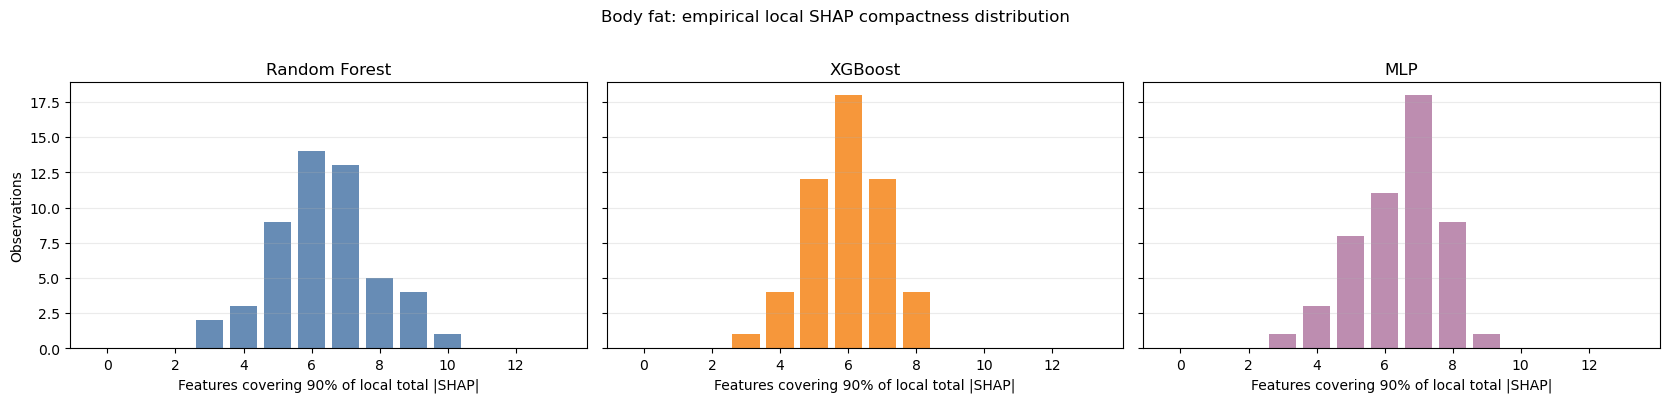

**Displayed native PySR equation**

`((-272.58493 * Wrist) + square(Abdomen)) / (Weight + (Neck - Biceps))`

**Native PySR structural audit (separate units from SHAP feature counts)**

,Dataset,PySR recorded complexity,Audited expression-tree nodes,Distinct variables,Variables,Operator occurrences,Distinct operator types,Operators,Numeric constant leaves
0,Body fat,12,12,5,"Wrist, Abdomen, Weight, Neck, Biceps",6,5,"/, +, *, square, -",1


**Fitted-tree size context only**

,Method,Saved fitted-model size context (not local explanation size)
0,Random Forest,419 trees; 14741 total leaves
1,XGBoost,77 trees; 296 total leaves


**MLP fitted-model size context only**

,Method,Hidden units,Trainable parameters,Interpretation
0,MLP,8,137,"Network size, not SHAP explanation size"


In [25]:
bodyfat_historical_compactness = pd.read_csv(
    project_path("outputs/bodyfat/analysis/compactness.csv")
)
legacy_pysr_shap_row = bodyfat_historical_compactness[
    bodyfat_historical_compactness["Method"] == "PySR"
]
assert len(legacy_pysr_shap_row) == 1

bodyfat_tree_compactness, bodyfat_tree_compactness_distribution = shap_compactness_tables(
    bodyfat_saved_shap
)
bodyfat_tree_compactness.to_csv(COMPARISON_DIRS["bodyfat"] / "compactness.csv", index=False)
bodyfat_tree_compactness_distribution.to_csv(
    COMPARISON_DIRS["bodyfat"] / "compactness_distribution_90.csv", index=False
)
display(Markdown("**Exact RF/XGBoost/MLP SHAP compactness summary and 80%/95% sensitivity**"))
display(
    bodyfat_tree_compactness.style.format(
        {
            "Mean features": "{:.2f}",
            "Median features": "{:.1f}",
            "Q1": "{:.1f}",
            "Q3": "{:.1f}",
            "IQR": "{:.1f}",
        }
    )
)
display(Markdown("**Empirical distribution at 90% attribution coverage**"))
display(
    bodyfat_tree_compactness_distribution.style.format(
        {"Percent of observations": "{:.1f}%"}
    )
)
plot_shap_compactness_distribution(
    bodyfat_saved_shap,
    "Body fat",
    COMPARISON_DIRS["bodyfat"] / "compactness_distribution_90.png",
)

display(Markdown(f"**Displayed native PySR equation**\n\n`{bodyfat_native_equation}`"))
bodyfat_symbolic_compactness = audit_displayed_expression(
    "Body fat",
    bodyfat_native_equation,
    set(FEATURE_COLUMNS),
    bodyfat_pysr["complexity"],
)
assert bodyfat_symbolic_compactness.loc[0, "Distinct variables"] == bodyfat_pysr["n_variables_used"]
assert (
    bodyfat_symbolic_compactness.loc[0, "Audited expression-tree nodes"]
    == bodyfat_symbolic_compactness.loc[0, "PySR recorded complexity"]
)
display(Markdown("**Native PySR structural audit (separate units from SHAP feature counts)**"))
display(bodyfat_symbolic_compactness)

bodyfat_model_size_context = (
    bodyfat_historical_compactness[
        bodyfat_historical_compactness["Method"].isin(["Random Forest", "XGBoost"])
    ][["Method", "Direct representation snapshot (not comparable)"]]
    .rename(
        columns={
            "Direct representation snapshot (not comparable)": (
                "Saved fitted-model size context (not local explanation size)"
            )
        }
    )
    .reset_index(drop=True)
)
display(Markdown("**Fitted-tree size context only**"))
display(bodyfat_model_size_context)

display(Markdown("**MLP fitted-model size context only**"))
display(pd.DataFrame([{"Method": "MLP", "Hidden units": 8, "Trainable parameters": 137,
                       "Interpretation": "Network size, not SHAP explanation size"}]))


### Body fat: final explanation figures

The RF/XGBoost/MLP beeswarms below use the exact 13-raw-feature arrays and verified subject identifiers used in local correctness and compactness. The existing plotting style is retained. The supplementary survey responses are presented in the following subsection. The exact survey presentation materials can be documented there. The native PySR equation and complete preprocessing/output rule are audited above.


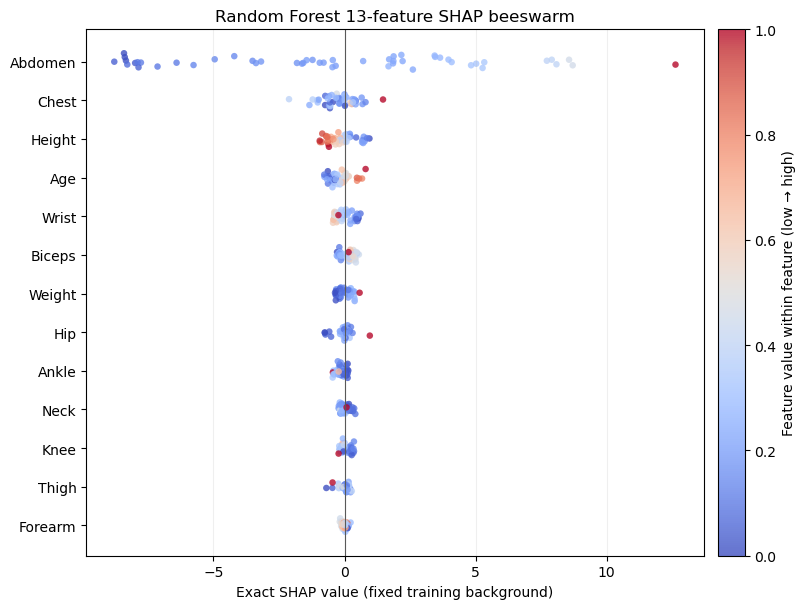

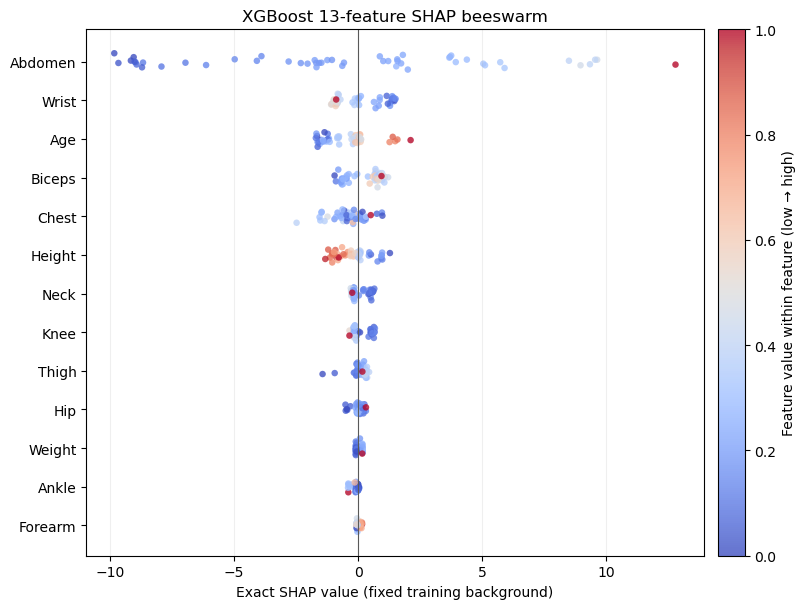

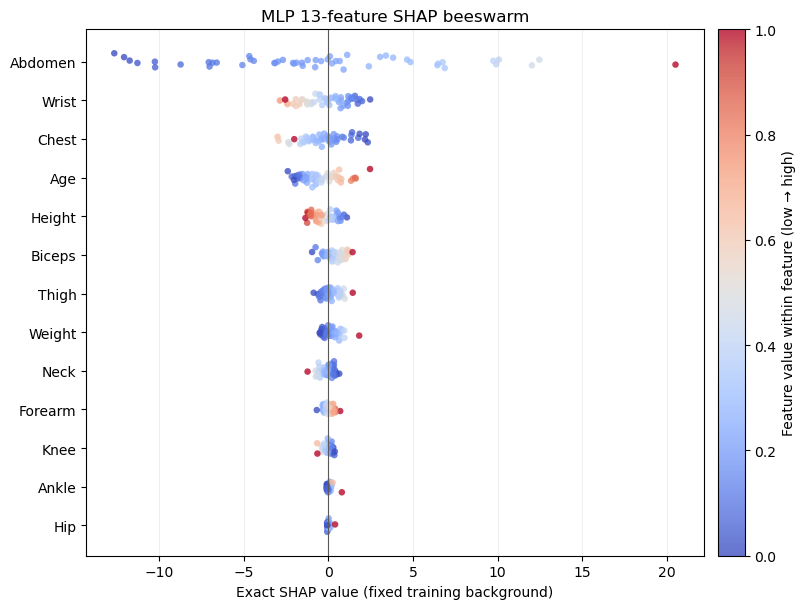

In [26]:
for method, values in bodyfat_saved_shap.items():
    expected = (len(bodyfat_X_test_raw), len(bodyfat_raw_features))
    if values.shape != expected:
        raise ValueError(f"{method} SHAP shape {values.shape} does not match expected {expected}.")


def bodyfat_beeswarm(method, shap_values, feature_frame):
    order = np.argsort(np.mean(np.abs(shap_values), axis=0))
    rng = np.random.default_rng(42)
    fig, ax = plt.subplots(figsize=(8.5, 6.2))
    scatter = None
    for y_position, feature_index in enumerate(order):
        feature_values = feature_frame.iloc[:, feature_index].to_numpy(dtype=float)
        span = feature_values.max() - feature_values.min()
        colour_values = (
            np.zeros_like(feature_values)
            if span <= np.finfo(float).eps
            else (feature_values - feature_values.min()) / span
        )
        jitter = rng.normal(0, 0.085, size=len(feature_values))
        scatter = ax.scatter(
            shap_values[:, feature_index],
            y_position + jitter,
            c=colour_values,
            cmap="coolwarm",
            norm=Normalize(0, 1),
            s=22,
            alpha=0.78,
            edgecolors="none",
        )
    ax.axvline(0, color="0.35", linewidth=0.8)
    ax.set_yticks(range(len(order)), [feature_frame.columns[i] for i in order])
    ax.set_xlabel("Exact SHAP value (fixed training background)")
    ax.set_title(f"{method} 13-feature SHAP beeswarm")
    ax.grid(axis="x", alpha=0.2)
    colour_bar = fig.colorbar(scatter, ax=ax, pad=0.02)
    colour_bar.set_label("Feature value within feature (low → high)")
    plt.tight_layout()
    fig.savefig(COMPARISON_DIRS["bodyfat"] / (method.lower().replace(" ", "_")+"_shap_beeswarm.png"), dpi=150, bbox_inches="tight")
    plt.show()


for method in SHAP_METHODS:
    bodyfat_beeswarm(method, bodyfat_saved_shap[method], bodyfat_X_test_raw)


### Body fat: exploratory survey evaluation

The supplementary **Bodyfat Model Comparison** survey contains two responses. Each response includes three blocks of six numerical ratings, three explanation-preference questions, a reason for the preference, an optional question about implausible, misleading or unclear content, and a relevant-expertise question.

| Survey label | Model |
|---|---|
| A | Random Forest (RF) |
| B | XGBoost |
| C | PySR |

The label-to-model mapping was confirmed by the researcher. The three repeated rating blocks are read in questionnaire order A, B and C. The export does not repeat the explanation labels in the rating-column headings.

The original CSV is retained as `data/bodyfat/survey_responses.csv`. Respondents are labelled R1 and R2 in source-row order; timestamps are omitted from the displayed tables. The tables show the individual recorded ratings and preference counts. No aggregate rating score or inferential test is calculated.

**Recruitment and administration:** The survey was sent out to colleagues of my supervisor in the data science field to be filled out oveer google forms.

**Rating scale:** Each explanation was rated using the same six required items on a five-point agreement scale, from 1 (Strongly Disagree) to 5 (Strongly Agree). The intermediate values 2, 3 and 4 were numbered but had no verbal labels in the supplied form.

**Survey presentation materials:** The supplied form presented Model A (Random Forest), Model B (XGBoost) and Model C (PySR) in that order, using the labels A, B and C. Introductory information described the observational dataset of 252 men, the measurement units and derived ratios, and the exclusion of body density from the predictors because it determines the target through Siri's equation. Participants were asked to evaluate understandability, plausibility and practical usefulness; the stated purpose was explanation evaluation rather than assessment of clinical suitability.

Models A and B were presented as SHAP beeswarm summaries across held-out test cases, with 13 raw measurements ordered by overall influence. Instructions explained that each dot represented a person, horizontal position indicated a positive or negative contribution relative to the model's average prediction, and red/blue represented relatively high/low measurement values. Feature labels included regression p-values, with a figure footnote identifying separate univariable linear regressions on the full dataset (n = 252).

Model C was presented as the equation:

$$\widehat{\mathrm{Body\ fat}}\;(\%) = \frac{\mathrm{Abdomen}^{2} - 272.58493\,\mathrm{Wrist}}{\mathrm{Weight} + \mathrm{Neck} - \mathrm{Biceps}}.$$

Accompanying instructions specified weight in pounds and abdomen, neck, biceps and wrist circumferences in centimetres, explained substitution of measurements to obtain the prediction, and stated that measurements absent from the equation do not directly affect its prediction. Each explanation was followed by its six rating items; comparative preference questions followed all three explanations.

**Scope:** MLP was not included in the presented survey materials and has no respondent ratings or preference counts. The computational extension does not change the recorded survey.


In [27]:
import csv

SURVEY_PATH = project_path("data/bodyfat/survey_responses.csv")
SURVEY_MODELS = {"A": "Random Forest", "B": "XGBoost", "C": "PySR"}
with SURVEY_PATH.open(encoding="utf-8-sig", newline="") as handle:
    survey_rows = list(csv.reader(handle))
survey_header, survey_records = survey_rows[0], survey_rows[1:]
if len(survey_header) != 25 or not survey_records:
    raise ValueError("Expected a 25-column survey export with at least one response.")
if any(len(row) != len(survey_header) for row in survey_records):
    raise ValueError("Survey row width differs from the header.")
if not (survey_header[1:7] == survey_header[7:13] == survey_header[13:19]):
    raise ValueError("Expected the same six rating questions in each explanation block.")

survey_respondents = [f"R{i + 1}" for i in range(len(survey_records))]
survey_question_ids = [f"Q{i + 1}" for i in range(6)]
survey_questions = pd.DataFrame({"Item": survey_question_ids, "Question": survey_header[1:7]})
survey_rating_rows = []
for respondent, record in zip(survey_respondents, survey_records):
    for block, (label, model) in enumerate(SURVEY_MODELS.items()):
        for item, value in zip(survey_question_ids, record[1 + block * 6:7 + block * 6]):
            if value and (not value.isdigit() or int(value) not in range(1, 6)):
                raise ValueError(f"Unexpected rating code for {respondent}, {label}, {item}: {value}")
            survey_rating_rows.append({"Respondent": respondent, "Explanation": label,
                                       "Model": model, "Item": item,
                                       "Rating": int(value) if value else pd.NA})
survey_ratings = pd.DataFrame(survey_rating_rows)
survey_ratings["Rating"] = survey_ratings["Rating"].astype("Int64")
survey_preferences = pd.DataFrame(
    [row[19:22] for row in survey_records], index=survey_respondents,
    columns=survey_header[19:22],
)
if not survey_preferences.isin([*SURVEY_MODELS, ""]).all().all():
    raise ValueError("Preference responses must be A, B, C or blank.")
survey_participants = pd.DataFrame({
    "Respondent": survey_respondents,
    "Reported relevant expertise": [row[24] or "Not provided" for row in survey_records],
})
survey_completeness = pd.DataFrame({
    "Recorded information": ["Respondents", "Rating answers", "Missing rating answers",
                             "Preference answers", "Missing preference answers"],
    "Count": [len(survey_records), int(survey_ratings["Rating"].notna().sum()),
              int(survey_ratings["Rating"].isna().sum()),
              int(survey_preferences.ne("").sum().sum()),
              int(survey_preferences.eq("").sum().sum())],
})
display(survey_participants)
display(survey_completeness)


,Respondent,Reported relevant expertise
0,R1,"Statistics, data science or machine learning"
1,R2,"Statistics, data science or machine learning"


,Recorded information,Count
0,Respondents,2
1,Rating answers,36
2,Missing rating answers,0
3,Preference answers,6
4,Missing preference answers,0


#### Recorded ratings

The question key reproduces the six rating questions. Each results column identifies the explanation/model and respondent. Missing ratings, if present, are displayed as “Not provided”.


In [28]:
display(survey_questions.set_index("Item"))
survey_rating_table = survey_ratings.pivot(
    index="Item", columns=["Explanation", "Respondent"], values="Rating"
).reindex(index=survey_question_ids, columns=pd.MultiIndex.from_product(
    [SURVEY_MODELS, survey_respondents], names=["Explanation", "Respondent"]
))
survey_rating_table.columns = [
    f"{label}: {SURVEY_MODELS[label]} ({respondent})"
    for label, respondent in survey_rating_table.columns
]
display(survey_rating_table.astype(object).where(survey_rating_table.notna(), "Not provided"))


,Question
Item,
Q1,I understand how to read and evaluate this explanation.
Q2,The measurements emphasised by this explanation are plausible contributors to body-fat estimates.
Q3,The directions of influence shown by this explanation are plausible according to existing domain...
Q4,I can tell how a higher or lower value of an influential measurement would generally affect the ...
Q5,The amount of information is appropriate for a quick interpretation.
Q6,This explanation would be useful when reviewing or communicating a model-generated body-fat esti...


,A: Random Forest (R1),A: Random Forest (R2),B: XGBoost (R1),B: XGBoost (R2),C: PySR (R1),C: PySR (R2)
Item,,,,,,
Q1,5,5,5,5,5,5
Q2,2,4,4,4,4,4
Q3,3,4,4,4,5,5
Q4,2,3,3,3,5,5
Q5,4,5,4,5,5,5
Q6,4,4,4,4,4,5


#### Recorded preferences and comments

Preference counts are shown separately for each question, with the number of recorded answers. Comments are reproduced as submitted. “Not provided” indicates an empty response field.


In [29]:
survey_preference_counts = pd.DataFrame({
    f"{label}: {model}": [(survey_preferences[question] == label).sum()
                         for question in survey_preferences.columns]
    for label, model in SURVEY_MODELS.items()
}, index=survey_preferences.columns)
survey_preference_counts.index.name = "Preference question"
survey_preference_counts["Recorded answers"] = survey_preferences.ne("").sum(axis=0)
survey_preference_counts["Missing answers"] = survey_preferences.eq("").sum(axis=0)
display(survey_preference_counts)
survey_comments = pd.DataFrame({
    "Respondent": survey_respondents,
    "Main reason for preference": [row[22] or "Not provided" for row in survey_records],
    "Implausible, misleading or unclear content": [row[23] or "Not provided" for row in survey_records],
})
display(survey_comments.set_index("Respondent"))


,A: Random Forest,B: XGBoost,C: PySR,Recorded answers,Missing answers
Preference question,,,,,
Which explanation was easiest to interpret?,0,0,2,2,0
Which explanation was most consistent with your body-composition knowledge?,0,0,2,2,0
Which explanation would you prefer to use when reviewing a body-fat prediction?,0,0,2,2,0


,Main reason for preference,"Implausible, misleading or unclear content"
Respondent,,
R1,Discover more factors that reflect the bodyfat,Not provided
R2,Clearer about the direction of feature effects,Not provided


#### Survey interpretation

Both respondents selected PySR on all three preference questions and gave it ratings equal to or higher than those given to Random Forest and XGBoost. However, all three explanations received the highest rating for understanding how to read and evaluate them. The clearest distinction concerned understanding how higher or lower measurement values affect the prediction: PySR received ratings of 5 from both respondents, compared with 2 and 3 for Random Forest and 3 and 3 for XGBoost. This pattern is consistent with one respondent’s stated preference for clearer directions of feature effects.

The relatively compact mathematical equation may have contributed to this preference, although the survey did not directly establish that explanation. Both respondents reported statistical, data-science or machine-learning expertise, which may also influence their familiarity with mathematical representations. PySR additionally received the highest ratings for the plausibility of its directions of influence. Together, these responses suggest that its directional information was perceived as understandable and plausible by these respondents. They do not establish the scientific correctness of those relationships.

These preferences provide no evidence about MLP explanations, which respondents did not evaluate.


### Body fat: interpretation

The historical tree/PySR results are retained; MLP predictive performance is added above. Correctness uses subject-level exact-SHAP comparisons with empirical training-donor deletion impacts, and completeness uses separately defined preservation/deletion interventions. Continuity uses exact SHAP on 12 fixed audit subjects over 10 paired perturbations at each noise level, conditional on small fitted-response change.

At the primary 0.433743-percentage-point threshold, RF retains 104/120 pairs at 2.5% noise and 90/120 at 5%; XGBoost retains 83/120 and 74/120. Mean cosine similarities are 0.9980-0.9991, while mean absolute attribution distances are non-zero at 0.0151-0.0253 percentage points per feature. Tightening or relaxing the response threshold changes retention materially and moves the magnitude estimates in the expected direction, but does not change the qualitative conclusion that both tree models have high directional similarity among retained pairs. These compact repeated-subject results do not support a population ranking between RF and XGBoost.

Across all 51 subjects, the 90%-absolute-SHAP count has mean 6.35, median 6 and IQR 2 raw features for Random Forest, and mean 5.94, median 6 and IQR 2 for XGBoost. No subject has zero total attribution. Mean counts change from 3.96/4.12 at 80% coverage to 8.33/7.84 at 95% for RF/XGBoost. The displayed PySR equation uses five distinct variables and six operator occurrences; its independently audited 12-node expression tree agrees with, but remains distinct from, the recorded PySR complexity of 12. The legacy 2.84-feature PySR SHAP result is not native equation compactness.

The native PySR rule reproduces saved predictions at floating-point precision and has no undefined or near-singular evaluations in the inspected perturbation domain. Its one global equation remains structurally unchanged, while its output changes under perturbed inputs. That output change is equation/model sensitivity, not an explanation-continuity score and not evidence that PySR is numerically superior to SHAP. Observational associations and replacement effects remain non-causal.

**Survey integration**

The computational evaluation provides evidence about faithfulness to fitted predictions, completeness, continuity and representation-specific compactness. The survey adds observations about how respondents perceived and understood the displayed explanations. Although the tree explanations performed well on several computational checks, both respondents preferred the PySR explanation. This illustrates why computational explanation properties and user preferences should be examined separately: measured faithfulness or stability does not, by itself, establish ease of interpretation.

The following generated MLP summary supplements the retained RF/XGBoost/PySR interpretation. All conclusions remain specific to the evaluated model, representation and sampling design.


In [30]:
# Generated from validated MLP artefacts, never copied from tree-model conclusions.
mlp_performance = mlp_table("bodyfat", "metrics.csv").iloc[0]
mlp_compactness = mlp_table("bodyfat", "compactness.csv").query("`Attribution coverage` == '90%'").iloc[0]
display(Markdown(
    f"**MLP results.** R² = {mlp_performance.R2:.6f}, RMSE = {mlp_performance.RMSE:.6f}, "
    f"MAE = {mlp_performance.MAE:.6f}. At 90% attribution coverage, the mean local size is "
    f"{mlp_compactness['Mean features']:.2f} features (median {mlp_compactness['Median features']:.1f}, "
    f"IQR {mlp_compactness['IQR']:.1f}). These feature counts measure attribution coverage, not prediction recovery."
))
display(mlp_table("bodyfat", "local_correctness_summary.csv").round(4))
display(mlp_table("bodyfat", "completeness_summary.csv")[[
    "Method", "Median sustained reconstruction features", "Reconstruction tolerance",
    "Mean normalized preservation error at 90% SHAP", "Mean normalized deletion change at 90% SHAP"
]].round(4))
display(mlp_table("bodyfat", "continuity_summary.csv")[[
    "Method", "Noise (% training SD)", "Retained proportion", "Mean cosine similarity",
    "Mean absolute attribution distance"
]].round(6))


**MLP results.** R² = 0.699807, RMSE = 3.736898, MAE = 3.110427. At 90% attribution coverage, the mean local size is 6.43 features (median 7.0, IQR 1.0). These feature counts measure attribution coverage, not prediction recovery.

,Method,Metric,N,Defined N,Undefined N,Median,Q1,Q3,IQR
0,MLP,Spearman correlation,51,51,0,0.8791,0.7967,0.9423,0.1456
1,MLP,Top-three overlap,51,51,0,0.6667,0.6667,1.0000,0.3333


,Method,Median sustained reconstruction features,Reconstruction tolerance,Mean normalized preservation error at 90% SHAP,Mean normalized deletion change at 90% SHAP
0,MLP,11.0,0.3561,0.1629,0.9744


,Method,Noise (% training SD),Retained proportion,Mean cosine similarity,Mean absolute attribution distance
0,MLP,2.5,0.916667,0.999049,0.023117
1,MLP,5.0,0.650000,0.998230,0.037296


## Cross-dataset synthesis

The table records implementation state, not a combined interpretability score.

In [31]:
cross_dataset_status = pd.DataFrame(
    {
        "Feynman": [
            "Fresh final evaluation; predictive context only",
            "Generating-equation alignment + local fitted-model faithfulness",
            "Measured SHAP output + native structural",
            "TreeSHAP/exact-MLP continuity + equation/model sensitivity",
            "SHAP distributions at 80/90/95% + audited equation structure",
            "Not assessed",
        ],
        "Body fat": [
            "Saved 51-subject evaluation; predictive context only",
            "Local fitted-model faithfulness + native execution audit",
            "Measured SHAP output + native structural",
            "Response-conditioned exact SHAP + equation/model sensitivity",
            "Exact-SHAP distributions at 80/90/95% + audited equation structure",
            "Two responses for RF/XGBoost/PySR only; MLP not surveyed",
        ],
        "Final status": [
            "Available as context, not an explanation score",
            "Implemented with dataset-specific claims",
            "Implemented; distinct constructs",
            "Implemented; representations kept distinct",
            "Implemented; separate units and no cross-representation ranking",
            "Results and exploratory interpretation included",
        ],
    },
    index=[
        "Predictive performance",
        "Correctness",
        "Completeness",
        "Continuity",
        "Compactness",
        "Exploratory survey",
    ],
)
display(cross_dataset_status)


,Feynman,Body fat,Final status
Predictive performance,Fresh final evaluation; predictive context only,Saved 51-subject evaluation; predictive context only,"Available as context, not an explanation score"
Correctness,Generating-equation alignment + local fitted-model faithfulness,Local fitted-model faithfulness + native execution audit,Implemented with dataset-specific claims
Completeness,Measured SHAP output + native structural,Measured SHAP output + native structural,Implemented; distinct constructs
Continuity,TreeSHAP/exact-MLP continuity + equation/model sensitivity,Response-conditioned exact SHAP + equation/model sensitivity,Implemented; representations kept distinct
Compactness,SHAP distributions at 80/90/95% + audited equation structure,Exact-SHAP distributions at 80/90/95% + audited equation structure,Implemented; separate units and no cross-representation ranking
Exploratory survey,Not assessed,Two responses for RF/XGBoost/PySR only; MLP not surveyed,Results and exploratory interpretation included


Feynman evaluates recovery of the known generating equation separately from faithfulness to fitted models. Body fat evaluates fitted-model faithfulness where no ground-truth explanation exists. The primary comparison is **RF/XGBoost/MLP SHAP versus native PySR equations**.

For RF/XGBoost/MLP, a SHAP vector is local to one observation; beeswarms, mean absolute magnitudes and compactness distributions are global summaries over those local vectors. They do not become a single global decision rule. Completeness is the measured ability of locally SHAP-ranked subsets to preserve or disrupt fitted predictions, while continuity is the change in recomputed SHAP vectors for paired nearby inputs whose fitted responses remain sufficiently close. Directional cosine and magnitude-sensitive attribution distance are reported together.

For PySR, the one displayed equation is the global fitted prediction rule. Completeness is structural and continuity is not assigned a SHAP-like number: the audited equation is fixed, and only its prediction sensitivity and evaluated numerical domain are reported. Original PySR SHAP artefacts remain supplementary and are not used for native-rule correctness, completeness, continuity or primary compactness. None of these constructs is converted into a common score.

**Survey contribution to the synthesis**

The Feynman benchmark provides a controlled setting in which PySR’s recovered equation can be compared with a known generating relationship. The body-fat experiments assess fitted-model behaviour without an equivalent ground-truth explanation. The survey adds a small amount of human feedback to the body-fat evaluation, particularly concerning perceived directional clarity and plausibility. It therefore extends the types of evidence considered, while providing no direct assessment of the Feynman explanations or independent validation of the body-fat equation.

MLP is included in all computational SHAP properties. Body-fat uses the same raw-feature representation and empirical background across all three models; Feynman retains the different tree-path and MLP empirical-background conditioning explicitly. No human evaluation of MLP is available.


## Limitations and conclusion

- The body-fat test set contains only 51 subjects, and its corrected SHAP continuity audit explains a fixed, model-informed audit subset of 12 subjects over 10 paired perturbations per noise level. The Feynman continuity audit uses 50 fixed historical test rows over 20 repeats.
- Repeated perturbations of the same subjects are dependent. Reported 2.5th-97.5th percentile ranges describe perturbation-to-perturbation variability of repeat-level means; they are not independent-subject or population confidence intervals.
- The response-stability threshold is operational rather than universal. Sensitivity checks at 2.5%, 5% and 10% of training-response SD preserve the qualitative high-cosine conclusion but materially change retained counts and include progressively larger attribution distances.
- Body-fat continuity, local faithfulness and output-completeness are conditional on one fixed 50-row training background. Exact coalition enumeration removes permutation Monte Carlo error for that background, not background-choice or population uncertainty.
- Body-fat data are observational; explanation patterns, prediction sensitivities and replacement effects do not support causal interpretation.
- Whole-row donor replacement preserves dependence inside the replaced block, but retained and replaced blocks form hybrids that can be unrealistic. Recomputing body-fat ratios maintains deterministic feature engineering but does not restore anatomical plausibility. Partial Feynman ratio replacement can likewise break shared-denominator physical relationships.
- Continuity noise is not clipped. All evaluated body-fat perturbations remained finite and positive with valid recomputed ratios, but some values crossed empirical training ranges. This is documented rather than treated as a projection rule.
- No inspected PySR perturbation produced a non-finite prediction or a near-zero equation denominator. This finite audit does not prove stability outside the evaluated domain.
- Cosine similarity is insensitive to attribution magnitude, so it is paired with mean absolute attribution distance. Neither metric translates into structural equation continuity.
- A PySR equation is one fixed global rule and is structurally unchanged across inputs. That fact is not a numerical counterpart to local SHAP similarity and does not by itself justify awarding PySR superior continuity.
- Native PySR equations are reasoning-complete for their own fitted prediction rules only. This does not make them complete, correct or causal descriptions of the real-world phenomenon.
- SHAP additivity is a numerical accounting identity for the chosen explanation setup. It is not proof that SHAP reveals the fitted model's complete internal reasoning.
- The Feynman correction covers 183 completed saved configurations of 192 planned. Training-only RF/XGBoost cross-validation was preserved, and MLP was independently selected using training-only cross-validation; fresh validation selection and final evaluation do not erase the historical test-set use.
- The new Feynman final sample follows the documented synthetic physical-input sampling design. Its 50-row local-faithfulness and completeness checks are compact, not exhaustive; its 512-donor estimate retains finite donor-sampling uncertainty.
- The body-fat RF was saved with scikit-learn 1.9.0 and evaluated locally with 1.8.0. Saved test predictions reproduce within floating-point tolerance, but this does not guarantee portability to other versions.
- The compactness distributions include zero-total attribution observations as 0-feature explanations and report their count explicitly; none occurs in either analysed dataset/model combination. The 80% and 95% checks show that the threshold materially changes local feature counts, especially for body fat.
- The historical body-fat PySR value of 2.84 features is SHAP applied to PySR and is excluded from native equation compactness. Saved tree/leaf counts describe fitted-model size, not the size of a displayed SHAP explanation.
- Representation-specific compactness measures, the two completeness constructs and the continuity evidence are not directly equivalent and remain separate.

### Survey limitations

Recorded sample: two respondents, both selecting statistics, data science or machine learning as their relevant expertise.

Only two responses were collected, so the observed preferences cannot be treated as representative of the wider field or as evidence of consensus. Both respondents reported expertise in statistics, data science or machine learning, limiting the disciplinary coverage of the feedback. The survey also measured self-reported understanding rather than performance on an interpretation task.

The findings concern the specific explanations presented. A more complex symbolic equation could be more difficult to interpret and receive different ratings, but this possibility was not investigated. Furthermore, the comparison changed both the underlying model and its explanation representation, so their separate contributions to the preferences cannot be determined. The results should consequently be treated as exploratory feedback on these particular model–explanation combinations.

### PySR and SHAP comparison framework

Predictive performance remains context, properties remain separate, and the columns are not converted into a single interpretability score.

| Dataset or evidence source | Comparison dimension | SHAP explanations (Random Forest, XGBoost and MLP) | PySR symbolic explanation | Comparative conclusion |
|---|---|---|---|---|
| Representation | Native explanation form | Local signed feature attributions for a fitted black box; global plots/tables aggregate local vectors | Audited executable global equation plus preprocessing/output rule | Different explanation forms; compare property-specific evidence, not a single score |
| Feynman | Predictive performance *(context only)* | Saved aggregate accuracy and individual prediction sensitivity | Saved aggregate accuracy and equation/model sensitivity | Prediction metrics contextualise explanations but do not measure continuity |
| Feynman | Correctness | Global generating-equation alignment plus local fitted-model faithfulness | Validation-selected equation equals the known generator on the audited domain | Ground-truth agreement and fitted-model faithfulness remain separate claims |
| Feynman | Completeness | Preservation/addition and deletion curves from local absolute-SHAP orders, paired empirical donors and random-order baselines | Complete fitted symbolic rule; additionally identical to the known generator on the audited domain | Measured output-completeness for fitted predictive models is distinct from PySR reasoning-completeness |
| Feynman | Continuity | Response-conditioned RF/XGBoost TreeSHAP cosine 0.9975-0.9994, distance 0.0025-0.0054; MLP exact SHAP cosine 0.9980-0.9994, distance 0.0032-0.0058; 50 subjects x 20 repeats | Fixed equation structure; saved prediction sensitivity and finite-domain audit only | High local SHAP continuity and fixed symbolic structure are different evidence, not a shared score |
| Feynman | Compactness | At 90%: RF mean 4.68, median 5, IQR 1; XGBoost mean 4.52, median 5, IQR 1; MLP mean 4.52, median 5, IQR 1; 0/2,000 zero-total rows for each model. Full distributions and 80%/95% sensitivity shown above | Displayed equation: 6 distinct variables, 10 operator occurrences; recorded complexity 17 and audited tree-node count 17 | Local feature counts and global expression structure use different units; no ranking |
| Body fat | Predictive performance *(context only)* | Saved aggregate accuracy and 100-repeat individual prediction sensitivity | Saved aggregate accuracy and equation/model sensitivity | Prediction metrics remain separate from explanation continuity |
| Body fat | Correctness | Exact-SHAP local faithfulness against empirical deletion impacts | Printed equation reproduces saved predictions | No real-world ground-truth explanation is available |
| Body fat | Completeness | Exact fixed-background donor preservation/deletion curves from local absolute-SHAP orders, with paired random-order baselines and recomputed ratios | Complete fitted equation and audited transformations, but no real-world ground-truth completeness claim | Output reconstruction/disruption and structural rule disclosure answer different questions |
| Body fat | Continuity | Response-conditioned RF/XGBoost exact-SHAP cosine 0.9980-0.9991, distance 0.0151-0.0253; MLP cosine 0.9982-0.9990, distance 0.0231-0.0373 percentage points/feature; 12 subjects x 10 repeats | Fixed equation structure; equation/model prediction sensitivity and finite-domain audit only | Do not interpret unchanged equation text as numerically superior continuity |
| Body fat | Compactness | At 90%: RF mean 6.35, median 6, IQR 2; XGBoost mean 5.94, median 6, IQR 2; MLP mean 6.43, median 7, IQR 1; 0/51 zero-total rows for each model. Full distributions and 80%/95% sensitivity shown above | Displayed equation: 5 distinct variables, 6 operator occurrences; recorded complexity 12 and audited tree-node count 12 | The legacy 2.84-feature PySR SHAP value is excluded; no cross-representation ranking |
| Body-fat exploratory survey (n = 2) | Six rating items, three preference questions and optional comments | A = Random Forest; B = XGBoost. Individual ratings recorded; 0 selections for each model on each preference question | C = PySR. Individual ratings recorded; 2 selections on each preference question | Both respondents preferred the presented PySR explanation on all three preference questions; this finding is limited to two respondents and the specific explanations evaluated. |
| Cross-dataset synthesis | Main strength | Quantified local fitted-output faithfulness, completeness, continuity and compactness distributions | Direct inspection of every operation in the fitted prediction rule | Complementary evidence rather than interchangeable metrics |
| Cross-dataset synthesis | Main limitation | Donor hybrids, background dependence, compact repeated-subject samples and no guarantee of internal reasoning completeness | Structural transparency does not establish empirical truth or supply a SHAP-like local stability metric | Claims remain model-, representation- and estimand-specific |
| Cross-dataset synthesis | Overall thesis conclusion | Property-specific local evidence for the fitted model explanations | Property-specific structural transparency for the fitted symbolic rules | No defensible single overall interpretability score or overall winner |

### Survey contribution to the final conclusion

The survey carries limited weight in the overall conclusion because of its small sample. Its contribution is the opportunity to compare respondent perceptions with the computational evaluation: both respondents preferred the PySR explanation, with a particularly clear rating difference in understanding feature-effect directions. This provides preliminary human feedback alongside the measured explanation properties, without establishing an overall interpretability winner or a general preference for symbolic regression.

### Scope of the MLP extension

The framework table includes the retained RF/XGBoost results and the new MLP values, with full per-model summaries in each dataset section. MLP does not have native split importance, a symbolic equation, or survey responses. Its exact SHAP values explain the complete scaled prediction pipeline in original target units. Feynman MLP uses empirical-background masking while the trees use training-path conditioning, so their differences cannot be attributed to model family alone.
